## Step 1 – Import Ottawa Vehicle Theft Data and Select Columns

Import vehicle theft data directly from the Ottawa Police Service Open Data API.

- Retrieve all available records.
- Select and rename the 11 relevant columns.
- Convert Vehicle_Year to integer format while preserving missing values.
- Verify successful data retrieval and display the dataset dimensions and first five records.

In [1]:
# Step 1 – Import Ottawa Vehicle Theft Data and Select Columns

import pandas as pd
import requests

# Ottawa Police Open Data API
url = "https://services7.arcgis.com/2vhcNzw0NfUwAD3d/ArcGIS/rest/services/Auto_Theft_Open_Data/FeatureServer/0/query"

# Selected columns: original field names and readable names
columns = {
    "VEH_YEAR": "Vehicle_Year",
    "VEH_MAKE": "Vehicle_Make",
    "VEH_STYLE": "Vehicle_Style",
    "OCC_DATE": "Occurred_Date",
    "YEAR": "Occurred_Year",
    "OCC_HOUR": "Occurred_Hour",
    "TOD": "Time_of_Day",
    "NB_NAME_EN": "Neighbourhood",
    "REP_DATE": "Reported_Date",
    "REP_HOUR": "Reported_Hour",
    "RECOVERED": "Recovered"
}

# Request all records
params = {
    "where": "1=1",
    "outFields": ",".join(columns.keys()),
    "returnGeometry": "false",
    "f": "json",
    "resultRecordCount": 15000
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()
data = response.json()

if "error" in data:
    raise RuntimeError(data["error"])

if data.get("exceededTransferLimit"):
    raise RuntimeError("Not all records were returned.")

# Create DataFrame with selected columns in logical order
df = pd.DataFrame(
    [feature["attributes"] for feature in data["features"]]
)

df = df[list(columns.keys())].rename(columns=columns)

# Convert Vehicle Year to integer while preserving missing values
df["Vehicle_Year"] = pd.to_numeric(
    df["Vehicle_Year"], errors="coerce"
).astype("Int64")

# Display dataset dimensions and first 5 records
print(f"Dataset: {df.shape[0]:,} rows, {df.shape[1]} columns")
display(df.head())


Dataset: 11,740 rows, 11 columns


,Vehicle_Year,Vehicle_Make,Vehicle_Style,Occurred_Date,Occurred_Year,Occurred_Hour,Time_of_Day,Neighbourhood,Reported_Date,Reported_Hour,Recovered
0,2000,HONDA,Automobile,1514782800000,2018,0,Night,Carson Grove - Carson Meadows,1514782800000,700,Y
1,2009,HONDA,Automobile,1510894800000,2018,0,Night,Orléans Avalon - Notting Gate - Fallingbrook -...,1514782800000,1200,Y
2,2007,INTERNATIONAL HARVESTER,Truck,1514782800000,2018,200,Night,East Industrial,1514782800000,900,Y
3,2010,CHEVROLET,Automobile,1514782800000,2018,100,Night,Orléans Queenswood Heights,1514782800000,1200,Y
4,2016,HYUNDAI,Automobile,1514610000000,2018,900,Morning,Vanier South,1514869200000,900,Y


## Step 2 – Format Date and Time Columns

Standardize the date and time columns to ensure consistent formatting and prepare the data for further processing.

- Convert ArcGIS timestamps to datetime format.
- Validate and convert hour values from HHMM to HH:MM format.
- Replace invalid date and time values with missing values.
- Convert Occurred_Year to integer format while preserving missing values.
- Display the first five records of the formatted columns.

In [2]:
# Step 2 – Format Date and Time Columns

# Convert ArcGIS timestamps to datetime
date_columns = ["Occurred_Date", "Reported_Date"]

for col in date_columns:
    df[col] = pd.to_datetime(
        df[col], unit="ms", errors="coerce"
    ).dt.normalize()

# Convert HHMM values to HH:MM format
hour_columns = ["Occurred_Hour", "Reported_Hour"]

for col in hour_columns:
    hours = pd.to_numeric(df[col], errors="coerce")

    # Validate hours and minutes
    valid = (
        hours.between(0, 2359)
        & ((hours % 100) < 60)
        & ((hours // 100) < 24)
    )

    df[col] = hours.where(valid).apply(
        lambda x: f"{int(x):04d}"[:2] + ":" + f"{int(x):04d}"[2:]
        if pd.notna(x) else None
    )

# Convert Year to integer
df["Occurred_Year"] = pd.to_numeric(
    df["Occurred_Year"], errors="coerce"
).astype("Int64")

# Display formatted columns
display(df[date_columns + hour_columns + ["Occurred_Year"]].head())


,Occurred_Date,Reported_Date,Occurred_Hour,Reported_Hour,Occurred_Year
0,2018-01-01,2018-01-01,00:00,07:00,2018
1,2017-11-17,2018-01-01,00:00,12:00,2018
2,2018-01-01,2018-01-01,02:00,09:00,2018
3,2018-01-01,2018-01-01,01:00,12:00,2018
4,2017-12-30,2018-01-02,09:00,09:00,2018


## Feature Engineering: 

## Step 3.1 – Create Vehicle Age and Age Group

Engineer two new features to represent vehicle age at the time of theft.

- Calculate Vehicle_Age by subtracting Vehicle_Year from Occurred_Year.
- Remove records with invalid vehicle ages below -1 while retaining missing values.
- Create three vehicle age groups: 0–1 Years, 2–5 Years, and 6+ Years.
- Include age -1 in the 0–1 Years group to accommodate next-year vehicle models.
- Display the engineered features, number of removed records, and remaining dataset size.

In [3]:
# Step 3.1 – Create Vehicle Age and Age Group

import numpy as np

# Convert Vehicle Year to numeric
df["Vehicle_Year"] = pd.to_numeric(
    df["Vehicle_Year"], errors="coerce"
)

# Calculate vehicle age at the time of theft
df["Vehicle_Age"] = df["Occurred_Year"] - df["Vehicle_Year"]

# Count invalid ages BEFORE filtering
invalid_ages = (df["Vehicle_Age"] < -1).fillna(False).sum()

# Remove invalid ages below -1, retain missing values
df = df[
    (df["Vehicle_Age"] >= -1).fillna(False) |
    df["Vehicle_Age"].isna()
].copy()

# Create vehicle age groups
conditions = [
    df["Vehicle_Age"].between(-1, 1).fillna(False).to_numpy(dtype=bool),
    df["Vehicle_Age"].between(2, 5).fillna(False).to_numpy(dtype=bool),
    (df["Vehicle_Age"] >= 6).fillna(False).to_numpy(dtype=bool)
]

choices = ["0–1 Years", "2–5 Years", "6+ Years"]

df["Vehicle_Age_Group"] = np.select(
    conditions, choices, default=None
)

# Convert vehicle year and age to integers
df["Vehicle_Year"] = df["Vehicle_Year"].astype("Int64")
df["Vehicle_Age"] = df["Vehicle_Age"].astype("Int64")

# Display results
display(
    df[["Vehicle_Year", "Occurred_Year",
        "Vehicle_Age", "Vehicle_Age_Group"]].head()
)

# Display removed records and reason
print(f"Records removed: {invalid_ages:,}")
print("Reason: Vehicle Age below -1 (invalid vehicle year)")
print(f"Remaining records: {len(df):,}")


,Vehicle_Year,Occurred_Year,Vehicle_Age,Vehicle_Age_Group
0,2000,2018,18,6+ Years
1,2009,2018,9,6+ Years
2,2007,2018,11,6+ Years
3,2010,2018,8,6+ Years
4,2016,2018,2,2–5 Years


Records removed: 6
Reason: Vehicle Age below -1 (invalid vehicle year)
Remaining records: 11,734


# Step 3.2 – Create Reporting Delay

Engineer a new feature representing the time between vehicle theft and its reporting to the police.

- Combine occurrence and reporting dates and times into full datetime values.
- Calculate the reporting delay in hours.
- Treat negative reporting delays as missing values.
- Categorize reporting delays into seven groups, ranging from Within 1 hour to Over 1 month.
- Display the first five records with the newly engineered Reporting_Delay feature.

In [4]:
# Step 3.2 – Create Reporting Delay

import numpy as np

# Combine dates and times into full datetime values
occurred_datetime = (
    df["Occurred_Date"]
    + pd.to_timedelta(df["Occurred_Hour"] + ":00")
)

reported_datetime = (
    df["Reported_Date"]
    + pd.to_timedelta(df["Reported_Hour"] + ":00")
)

# Calculate reporting delay in hours
delay_hours = (
    reported_datetime - occurred_datetime
).dt.total_seconds() / 3600

# Remove negative delays (invalid), retain missing values
delay_hours = delay_hours.where(delay_hours >= 0)

# Categorize reporting delay
conditions = [
    delay_hours <= 1,
    (delay_hours > 1) & (delay_hours <= 3),
    (delay_hours > 3) & (delay_hours <= 8),
    (delay_hours > 8) & (delay_hours <= 24),
    (delay_hours > 24) & (delay_hours <= 168),
    (delay_hours > 168) & (delay_hours <= 720),
    delay_hours > 720
]

choices = [
    "Within 1 hour",
    "1–3 hours",
    "3–8 hours",
    "8–24 hours",
    "1–7 days",
    "1 week–1 month",
    "Over 1 month"
]

df["Reporting_Delay"] = np.select(
    conditions, choices, default=None
)

# Display results
display(
    df[["Occurred_Date", "Occurred_Hour",
        "Reported_Date", "Reported_Hour",
        "Reporting_Delay"]].head()
)


,Occurred_Date,Occurred_Hour,Reported_Date,Reported_Hour,Reporting_Delay
0,2018-01-01,00:00,2018-01-01,07:00,3–8 hours
1,2017-11-17,00:00,2018-01-01,12:00,Over 1 month
2,2018-01-01,02:00,2018-01-01,09:00,3–8 hours
3,2018-01-01,01:00,2018-01-01,12:00,8–24 hours
4,2017-12-30,09:00,2018-01-02,09:00,1–7 days


## Step 4 – Clean Recovered Column

Standardize the target variable, Recovered, into a consistent binary format for classification.

- Convert "Y" to "Yes".
- Convert "N" to "No".
- Replace missing recovery values with "No".

In [5]:
# Step 4 – Clean Recovered Column

# Convert recovery values to Yes/No
df["Recovered"] = (
    df["Recovered"]
    .replace({
        "Y": "Yes",
        "N": "No"
    })
    .fillna("No")
)


## Step 5 – Check Missing Values in All Columns

Assess data completeness to identify columns requiring missing value treatment.

- Calculate the number and percentage of missing values in each column.
- Sort columns by missing value count in descending order.
- Display the missing value summary.
- Report the total number of records and missing values across the dataset.

In [6]:
# Step 5 – Check Missing Values in All Columns

# Count and calculate percentage of missing values
missing_values = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

# Sort by highest number of missing values
missing_values = missing_values.sort_values(
    by="Missing_Count", ascending=False
)

# Display results
display(missing_values)

print(f"Total records: {len(df):,}")
print(f"Total missing values: {df.isnull().sum().sum():,}")


,Missing_Count,Missing_Percentage
Vehicle_Year,1037,8.84
Vehicle_Age,1037,8.84
Vehicle_Age_Group,1037,8.84
Vehicle_Make,963,8.21
Neighbourhood,540,4.60
Vehicle_Style,538,4.58
Occurred_Date,0,0.00
Occurred_Year,0,0.00
Occurred_Hour,0,0.00
Time_of_Day,0,0.00


Total records: 11,734
Total missing values: 5,152


## Step 6 – Remove Missing Values and Clean Vehicle Categories

Clean the dataset to improve data quality and reduce the impact of insufficiently represented vehicle categories.

- Remove records containing missing values in any column.
- Remove records with Vehicle_Style classified as "Other".
- Remove vehicle makes appearing five times or fewer due to insufficient representation.
- Display the number of records removed by each cleaning operation and the remaining dataset size.

In [7]:
# Step 6 – Remove Missing Values and Clean Vehicle Categories

# 1. Remove records with any missing values
before = len(df)
df = df.dropna().copy()
removed_missing = before - len(df)

# 2. Remove records with Vehicle Style = Other
style_mask = df["Vehicle_Style"].eq("Other")
removed_style = style_mask.sum()

df = df.loc[~style_mask].copy()

# 3. Remove Vehicle Makes appearing 5 times or fewer
make_counts = df["Vehicle_Make"].value_counts()
rare_makes = make_counts[make_counts <= 5].index

make_mask = df["Vehicle_Make"].isin(rare_makes)
removed_make = make_mask.sum()

df = df.loc[~make_mask].copy()

# 4. Remove Vehicle Styles appearing 5 times or fewer
style_counts = df["Vehicle_Style"].value_counts()
rare_styles = style_counts[style_counts <= 5].index

style_mask = df["Vehicle_Style"].isin(rare_styles)
removed_style = style_mask.sum()

df = df.loc[~style_mask].copy()

# 5. Display results
print(f"Records removed (Missing Values): {removed_missing:,}")
print(f"Records removed (Vehicle Style = Other): {removed_style:,}")
print(f"Records removed (Vehicle Make <= 5): {removed_make:,}")
print(f"Remaining records: {len(df):,}")

Records removed (Missing Values): 1,929
Records removed (Vehicle Style = Other): 5
Records removed (Vehicle Make <= 5): 114
Remaining records: 9,590


## Step 7 – Verify Missing Values After Cleaning

Verify that the previous data cleaning operations have successfully removed all missing values.

- Recalculate the number and percentage of missing values in each column.
- Sort columns by missing value count in descending order.
- Report the remaining number of records and total missing values.
- Confirm that the dataset contains no remaining missing values.

In [8]:
# Step 7 – Check Missing Values in All Columns again

# Count and calculate percentage of missing values
missing_values = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

# Sort by highest number of missing values
missing_values = missing_values.sort_values(
    by="Missing_Count", ascending=False
)
print(f"Total records: {len(df):,}")
print(f"Total missing values: {df.isnull().sum().sum():,}")


Total records: 9,590
Total missing values: 0


## Step 8 – Recovery Statistics

Explore vehicle recovery patterns across different vehicle characteristics and theft circumstances.

- Calculate overall recovery counts and percentages.
- Analyze recovery outcomes by Vehicle Style, Occurred Year, Time of Day, Vehicle Age Group, and Reporting Delay.
- Display total theft counts, recovered and non-recovered counts, and their corresponding percentages.
- Sort results by total theft count, chronological year, or recovery percentage, as appropriate.
- Identify initial patterns and potential relationships between variables and recovery outcomes.

In [9]:
# Step 8 – Recovery Statistics

# Function to calculate recovery counts and percentages
def recovery_stats(group_col=None, sort_by="Total", ascending=False):
    if group_col is None:
        counts = df["Recovered"].value_counts().reindex(["Yes", "No"], fill_value=0)
        total = counts.sum()

        return pd.DataFrame({
            "Count": counts,
            "Percentage (%)": (counts / total * 100).round(2)
        })

    counts = pd.crosstab(
        df[group_col].fillna("Unknown"),
        df["Recovered"]
    ).reindex(columns=["Yes", "No"], fill_value=0)

    totals = counts.sum(axis=1)

    result = pd.DataFrame({
        "Total": totals,
        "Yes_Count": counts["Yes"],
        "Yes_Percent": (counts["Yes"] / totals * 100).round(2),
        "No_Count": counts["No"],
        "No_Percent": (counts["No"] / totals * 100).round(2)
    })

    # Sort by selected column or category index
    if sort_by == "index":
        return result.sort_index(ascending=ascending)

    return result.sort_values(by=sort_by, ascending=ascending)

# Overall recovery
print("Overall Recovery")
display(recovery_stats())

# Recovery by Vehicle Style (sort by Total)
print("Recovery by Vehicle Style")
display(recovery_stats("Vehicle_Style"))

# Recovery by Year (sort by Occurred_Year)
print("Recovery by Year")
display(recovery_stats("Occurred_Year", sort_by="index", ascending=True))

# Recovery by Time of Day (sort by Total)
print("Recovery by Time of Day")
display(recovery_stats("Time_of_Day"))

# Recovery by Vehicle Age Group (sort by Total)
print("Recovery by Vehicle Age Group")
display(recovery_stats("Vehicle_Age_Group"))

# Recovery by Reporting Delay (sort by Yes_Percent)
print("Recovery by Reporting Delay")
display(recovery_stats("Reporting_Delay", sort_by="Yes_Percent"))


Overall Recovery


,Count,Percentage (%)
Recovered,,
Yes,6019,62.76
No,3571,37.24


Recovery by Vehicle Style


,Total,Yes_Count,Yes_Percent,No_Count,No_Percent
Vehicle_Style,,,,,
Automobile,6392,4328,67.71,2064,32.29
Suv,2012,968,48.11,1044,51.89
Truck,900,523,58.11,377,41.89
Van,219,169,77.17,50,22.83
Motorcycle,37,18,48.65,19,51.35
Atv (4 Wheeler),12,5,41.67,7,58.33
Licence Plate,10,5,50.00,5,50.00
Trailer,8,3,37.50,5,62.50


Recovery by Year


,Total,Yes_Count,Yes_Percent,No_Count,No_Percent
Occurred_Year,,,,,
2018,727,505,69.46,222,30.54
2019,811,575,70.90,236,29.10
2020,709,465,65.59,244,34.41
2021,913,534,58.49,379,41.51
2022,1874,1041,55.55,833,44.45
2023,1826,1089,59.64,737,40.36
2024,1498,955,63.75,543,36.25
2025,1232,855,69.40,377,30.60


... (2 outputs left out)

Recovery by Vehicle Age Group


,Total,Yes_Count,Yes_Percent,No_Count,No_Percent
Vehicle_Age_Group,,,,,
2–5 Years,3570,1944,54.45,1626,45.55
6+ Years,3570,2667,74.71,903,25.29
0–1 Years,2450,1408,57.47,1042,42.53


Recovery by Reporting Delay


,Total,Yes_Count,Yes_Percent,No_Count,No_Percent
Reporting_Delay,,,,,
Within 1 hour,2664,2087,78.34,577,21.66
3–8 hours,1427,859,60.20,568,39.80
1–7 days,912,537,58.88,375,41.12
1–3 hours,718,420,58.50,298,41.50
Over 1 month,270,155,57.41,115,42.59
8–24 hours,3262,1792,54.94,1470,45.06
1 week–1 month,337,169,50.15,168,49.85


## Step 9 – Preview the Final Cleaned Dataset

Review the final dataset before proceeding to machine learning.

- Display the total number of records and columns.
- Preview the first five records.
- Verify the final column names and data types.

In [10]:
# Step 9 – Preview the Final Cleaned Dataset

# Dataset dimensions
print(f"Total records: {df.shape[0]:,}")
print(f"Total columns: {df.shape[1]}")

# Preview the first five records
display(df.head())

# Display column names and data types
display(df.dtypes.to_frame("Data_Type"))

Total records: 9,590
Total columns: 14


,Vehicle_Year,Vehicle_Make,Vehicle_Style,Occurred_Date,Occurred_Year,Occurred_Hour,Time_of_Day,Neighbourhood,Reported_Date,Reported_Hour,Recovered,Vehicle_Age,Vehicle_Age_Group,Reporting_Delay
0,2000,HONDA,Automobile,2018-01-01,2018,00:00,Night,Carson Grove - Carson Meadows,2018-01-01,07:00,Yes,18,6+ Years,3–8 hours
1,2009,HONDA,Automobile,2017-11-17,2018,00:00,Night,Orléans Avalon - Notting Gate - Fallingbrook -...,2018-01-01,12:00,Yes,9,6+ Years,Over 1 month
2,2007,INTERNATIONAL HARVESTER,Truck,2018-01-01,2018,02:00,Night,East Industrial,2018-01-01,09:00,Yes,11,6+ Years,3–8 hours
3,2010,CHEVROLET,Automobile,2018-01-01,2018,01:00,Night,Orléans Queenswood Heights,2018-01-01,12:00,Yes,8,6+ Years,8–24 hours
4,2016,HYUNDAI,Automobile,2017-12-30,2018,09:00,Morning,Vanier South,2018-01-02,09:00,Yes,2,2–5 Years,1–7 days


,Data_Type
Vehicle_Year,Int64
Vehicle_Make,object
Vehicle_Style,object
Occurred_Date,datetime64[ns]
Occurred_Year,Int64
Occurred_Hour,object
Time_of_Day,object
Neighbourhood,object
Reported_Date,datetime64[ns]
Reported_Hour,object


## Step 10 – Export Final Cleaned Dataset to CSV

Save the final cleaned dataset for future use and reproducibility.

- Export the dataset as Ottawa_Vehicle_Theft_Cleaned.csv.
- Exclude the DataFrame index from the exported file.
- Confirm successful export and display the total number of records and columns.

In [11]:
# Step 10 – Export Final Cleaned Dataset to CSV

df.to_csv("Ottawa_Vehicle_Theft_Cleaned.csv", index=False)

print("Dataset saved successfully!")
print(f"Records: {len(df):,}")
print(f"Columns: {len(df.columns)}")

Dataset saved successfully!
Records: 9,590
Columns: 14


## Step 11 – Stratified Train/Test Split

Prepare the dataset for supervised machine learning while preserving the original recovery class distribution.

- Select six predictors and Recovered as the target variable.
- Split the dataset into 80% training and 20% testing sets.
- Apply stratification to maintain similar recovery class proportions across both sets.
- Set random_state to 42 to ensure reproducibility.
- Compare recovery distributions across the full, training, and testing datasets.
- Display dataset sizes and confirm the selected predictors.

In [12]:
# Step 11 – Stratified Train/Test Split

import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Separate the 6 predictors (X) and target (y)
predictors = [
    "Vehicle_Make",
    "Vehicle_Style",
    "Vehicle_Age_Group",
    "Neighbourhood",
    "Time_of_Day",
    "Reporting_Delay"
]

X = df[predictors]
y = df["Recovered"]

# 2. Stratified split: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# 3. Compare recovery distributions
distribution = pd.DataFrame({
    "Full_Dataset": y.value_counts(normalize=True) * 100,
    "Training": y_train.value_counts(normalize=True) * 100,
    "Testing": y_test.value_counts(normalize=True) * 100
}).round(2)

print("\nRecovery Distribution (%):")
display(distribution)

# 4. Dataset sizes
print("\nDataset Sizes:")
print(f"Full dataset: {len(X):,}")
print(f"Training: {len(X_train):,} ({len(X_train)/len(X)*100:.1f}%)")
print(f"Testing: {len(X_test):,} ({len(X_test)/len(X)*100:.1f}%)")

# 5. Confirm selected predictors
print("\nSelected Predictors:")
print(X.columns.tolist())


Recovery Distribution (%):


,Full_Dataset,Training,Testing
Recovered,,,
Yes,62.76,62.76,62.77
No,37.24,37.24,37.23



Dataset Sizes:
Full dataset: 9,590
Training: 7,672 (80.0%)
Testing: 1,918 (20.0%)

Selected Predictors:
['Vehicle_Make', 'Vehicle_Style', 'Vehicle_Age_Group', 'Neighbourhood', 'Time_of_Day', 'Reporting_Delay']


## Step 12 – Preprocessing

Prepare the six categorical predictors for machine learning using One-Hot Encoding.

- Define a ColumnTransformer to apply One-Hot Encoding to all six predictors.
- Convert categorical values into binary numerical features.
- Configure the encoder to handle unseen categories without generating errors.
- Prepare a reusable preprocessing component for the machine learning pipelines.

In [13]:
# Step 12 – Preprocessing

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Define One-Hot Encoding for all six categorical predictors
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), X_train.columns.tolist())
    ]
)

### Step 13.1 – Model Fitting: 1. Logistic Regression

Establish the initial performance of Logistic Regression before further model diagnostics and hyperparameter tuning.

- Create a pipeline combining preprocessing and Logistic Regression.
- Apply stratified 5-fold cross-validation to the training dataset.
- Evaluate Accuracy, Precision, Recall, F1 Score, and ROC AUC.
- Use macro averaging for Precision, Recall, and F1 to give equal importance to both recovery classes.
- Display the mean and standard deviation of each performance metric across the five folds.

In [14]:
# Step 13.1 – Model fitting: 1. Logistic Regression

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

# 1. Create Logistic Regression pipeline
lr_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# 2. Define stratified 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Evaluate using cross-validation
lr_cv = cross_validate(
    lr_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "Accuracy": "accuracy",
        "Precision": "precision_macro",
        "Recall": "recall_macro",
        "F1": "f1_macro",
        "ROC_AUC": "roc_auc"
    },
    n_jobs=-1
)

# 4. Display average cross-validation results
lr_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"],
    "Mean": [
        lr_cv["test_Accuracy"].mean(),
        lr_cv["test_Precision"].mean(),
        lr_cv["test_Recall"].mean(),
        lr_cv["test_F1"].mean(),
        lr_cv["test_ROC_AUC"].mean()
    ],
    "Std": [
        lr_cv["test_Accuracy"].std(),
        lr_cv["test_Precision"].std(),
        lr_cv["test_Recall"].std(),
        lr_cv["test_F1"].std(),
        lr_cv["test_ROC_AUC"].std()
    ]
}).round(4)

display(lr_results)

,Metric,Mean,Std
0,Accuracy,0.6623,0.0111
1,Precision,0.6312,0.0140
2,Recall,0.6109,0.0134
3,F1,0.6128,0.0144
4,ROC_AUC,0.7011,0.0074


### Step 13.2 – Model Fitting: 2. Random Forest

Establish the initial performance of Random Forest before further model diagnostics and hyperparameter tuning.

- Create a pipeline combining preprocessing and Random Forest with 100 decision trees.
- Apply stratified 5-fold cross-validation to the training dataset.
- Evaluate Accuracy, Precision, Recall, F1 Score, and ROC AUC.
- Use macro averaging for Precision, Recall, and F1 to give equal importance to both recovery classes.
- Display the mean and standard deviation of each performance metric across the five folds.

In [15]:
# Step 13.2 – Model fitting: 2. Random Forest

from sklearn.ensemble import RandomForestClassifier

# 1. Create Random Forest pipeline
rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# 2. Evaluate using stratified 5-fold cross-validation
rf_cv = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "Accuracy": "accuracy",
        "Precision": "precision_macro",
        "Recall": "recall_macro",
        "F1": "f1_macro",
        "ROC_AUC": "roc_auc"
    },
    n_jobs=-1
)

# 3. Display average cross-validation results
rf_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"],
    "Mean": [
        rf_cv["test_Accuracy"].mean(),
        rf_cv["test_Precision"].mean(),
        rf_cv["test_Recall"].mean(),
        rf_cv["test_F1"].mean(),
        rf_cv["test_ROC_AUC"].mean()
    ],
    "Std": [
        rf_cv["test_Accuracy"].std(),
        rf_cv["test_Precision"].std(),
        rf_cv["test_Recall"].std(),
        rf_cv["test_F1"].std(),
        rf_cv["test_ROC_AUC"].std()
    ]
}).round(4)

display(rf_results)

,Metric,Mean,Std
0,Accuracy,0.6555,0.0102
1,Precision,0.6239,0.0124
2,Recall,0.6095,0.0108
3,F1,0.6117,0.0113
4,ROC_AUC,0.6819,0.0111


### Step 13.3 – Model Fitting: 3. Support Vector Machine (SVM)

Establish the initial performance of SVM before further model diagnostics and hyperparameter tuning.

- Create a pipeline combining preprocessing and SVM with the Radial Basis Function (RBF) kernel.
- Apply stratified 5-fold cross-validation to the training dataset.
- Evaluate Accuracy, Precision, Recall, F1 Score, and ROC AUC.
- Use macro averaging for Precision, Recall, and F1 to give equal importance to both recovery classes.
- Display the mean and standard deviation of each performance metric across the five folds.

In [16]:
# Step 13.3 – Model fitting: 3. Support Vector Machine (SVM)

from sklearn.svm import SVC

# 1. Create SVM pipeline
svm_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        random_state=42
    ))
])

# 2. Evaluate using stratified 5-fold cross-validation
svm_cv = cross_validate(
    svm_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "Accuracy": "accuracy",
        "Precision": "precision_macro",
        "Recall": "recall_macro",
        "F1": "f1_macro",
        "ROC_AUC": "roc_auc"
    },
    n_jobs=-1
)

# 3. Display average cross-validation results
svm_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"],
    "Mean": [
        svm_cv["test_Accuracy"].mean(),
        svm_cv["test_Precision"].mean(),
        svm_cv["test_Recall"].mean(),
        svm_cv["test_F1"].mean(),
        svm_cv["test_ROC_AUC"].mean()
    ],
    "Std": [
        svm_cv["test_Accuracy"].std(),
        svm_cv["test_Precision"].std(),
        svm_cv["test_Recall"].std(),
        svm_cv["test_F1"].std(),
        svm_cv["test_ROC_AUC"].std()
    ]
}).round(4)

display(svm_results)

,Metric,Mean,Std
0,Accuracy,0.6685,0.0050
1,Precision,0.6398,0.0070
2,Recall,0.6113,0.0046
3,F1,0.6125,0.0050
4,ROC_AUC,0.7021,0.0082


### Step 13.4 – Model Fitting: 4. Gradient Boosting

Establish the initial performance of Gradient Boosting before further model diagnostics and hyperparameter tuning.

- Create a pipeline combining preprocessing and Gradient Boosting with default hyperparameters.
- Apply stratified 5-fold cross-validation to the training dataset.
- Evaluate Accuracy, Precision, Recall, F1 Score, and ROC AUC.
- Use macro averaging for Precision, Recall, and F1 to give equal importance to both recovery classes.
- Display the mean and standard deviation of each performance metric across the five folds.

In [17]:
# Step 13.4 – Model fitting: 4. Gradient Boosting

from sklearn.ensemble import GradientBoostingClassifier

# 1. Create Gradient Boosting pipeline
gb_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", GradientBoostingClassifier(
        random_state=42
    ))
])

# 2. Evaluate using stratified 5-fold cross-validation
gb_cv = cross_validate(
    gb_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "Accuracy": "accuracy",
        "Precision": "precision_macro",
        "Recall": "recall_macro",
        "F1": "f1_macro",
        "ROC_AUC": "roc_auc"
    },
    n_jobs=-1
)

# 3. Display average cross-validation results
gb_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"],
    "Mean": [
        gb_cv["test_Accuracy"].mean(),
        gb_cv["test_Precision"].mean(),
        gb_cv["test_Recall"].mean(),
        gb_cv["test_F1"].mean(),
        gb_cv["test_ROC_AUC"].mean()
    ],
    "Std": [
        gb_cv["test_Accuracy"].std(),
        gb_cv["test_Precision"].std(),
        gb_cv["test_Recall"].std(),
        gb_cv["test_F1"].std(),
        gb_cv["test_ROC_AUC"].std()
    ]
}).round(4)

display(gb_results)

,Metric,Mean,Std
0,Accuracy,0.6627,0.0100
1,Precision,0.6339,0.0153
2,Recall,0.5945,0.0102
3,F1,0.5909,0.0116
4,ROC_AUC,0.7049,0.0091


## Step 14 – Compare Initial Model Performance

Compare the initial performance of the four machine learning models against a majority-class baseline before model optimization.

- Establish a baseline using a Dummy Classifier that always predicts the most frequent recovery class.
- Evaluate the baseline using the same stratified 5-fold cross-validation framework.
- Combine the cross-validation results for Logistic Regression, Random Forest, SVM, and Gradient Boosting.
- Compare mean Accuracy, Precision, Recall, F1 Score, and ROC AUC across all models.
- Rank the models by Accuracy in descending order.
- Assess how much each model improves upon the baseline.

In [18]:
# Step 14 – Compare Initial Model Performance

from sklearn.dummy import DummyClassifier

# 1. Majority-class baseline
baseline_model = DummyClassifier(strategy="most_frequent")

baseline_cv = cross_validate(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "Accuracy": "accuracy",
        "Precision": "precision_macro",
        "Recall": "recall_macro",
        "F1": "f1_macro",
        "ROC_AUC": "roc_auc"
    },
    n_jobs=-1
)

# 2. Combine cross-validation results
models_cv = {
    "Baseline": baseline_cv,
    "Logistic Regression": lr_cv,
    "Random Forest": rf_cv,
    "SVM": svm_cv,
    "Gradient Boosting": gb_cv
}

model_comparison = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": results["test_Accuracy"].mean(),
        "Precision": results["test_Precision"].mean(),
        "Recall": results["test_Recall"].mean(),
        "F1": results["test_F1"].mean(),
        "ROC_AUC": results["test_ROC_AUC"].mean()
    }
    for name, results in models_cv.items()
])

# 3. Sort by Accuracy
model_comparison = model_comparison.sort_values(
    by="Accuracy", ascending=False
).reset_index(drop=True)

display(model_comparison.round(4))

/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,SVM,0.6685,0.6398,0.6113,0.6125,0.7021
1,Gradient Boosting,0.6627,0.6339,0.5945,0.5909,0.7049
2,Logistic Regression,0.6623,0.6312,0.6109,0.6128,0.7011
3,Random Forest,0.6555,0.6239,0.6095,0.6117,0.6819
4,Baseline,0.6276,0.3138,0.5000,0.3856,0.5000


# Conclusion – Initial Model Performance Comparison

All four models were implemented using the same preprocessing pipeline and evaluated using stratified 5-fold cross-validation, ensuring a fair and consistent comparison while preventing preprocessing-related data leakage.

All four models outperform the majority-class baseline. SVM achieves the highest initial accuracy (66.26%), although the performance differences between models are relatively small.

Further model diagnostics, detailed evaluation, and hyperparameter tuning are needed before selecting the final model.

### Step 15.1 – SVM: Model Diagnostics

Evaluate SVM training and validation performance using stratified 5-fold cross-validation, comparing Accuracy, F1, ROC AUC, and Log Loss.

Examine performance gaps to identify overfitting or underfitting. Visualize the SVM decision function and analyze support vectors to understand how the model separates recovered (Yes) and unrecovered (No) vehicles.

In [ ]:
# Step 15.1 – SVM: Model Diagnostics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import cross_validate, cross_val_predict

# 1. Prepare SVM with probability estimates
svm_diagnostic_model = clone(svm_model)
svm_diagnostic_model.set_params(classifier__probability=True)

# 2. Stratified 5-fold cross-validation
svm_diagnostic = cross_validate(
    svm_diagnostic_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "Accuracy": "accuracy",
        "F1": "f1_macro",
        "ROC_AUC": "roc_auc",
        "Log_Loss": "neg_log_loss"
    },
    return_train_score=True,
    n_jobs=-1
)

# 3. Compare training and validation metrics
metrics = ["Accuracy", "F1", "ROC_AUC", "Log_Loss"]

svm_diagnostic_results = pd.DataFrame({
    "Metric": metrics,
    "Training": [
        svm_diagnostic[f"train_{m}"].mean()
        for m in metrics
    ],
    "Validation": [
        svm_diagnostic[f"test_{m}"].mean()
        for m in metrics
    ]
})

# Convert negative Log Loss to positive
mask = svm_diagnostic_results["Metric"] == "Log_Loss"

svm_diagnostic_results.loc[
    mask, ["Training", "Validation"]
] *= -1

# 4. Calculate training-validation gaps
svm_diagnostic_results["Gap"] = (
    svm_diagnostic_results["Training"]
    - svm_diagnostic_results["Validation"]
)

print("SVM – Training vs Validation Performance")
display(svm_diagnostic_results.round(4))

# 5. Out-of-fold SVM decision scores
svm_scores = cross_val_predict(
    svm_diagnostic_model,
    X_train,
    y_train,
    cv=cv,
    method="decision_function",
    n_jobs=-1
)

# 5. – SVM Decision Boundary Visualization

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.decomposition import PCA
from sklearn.svm import SVC

# 1. Fit the SVM pipeline on the training dataset
svm_fitted = clone(svm_diagnostic_model)
svm_fitted.fit(X_train, y_train)

# 2. Apply existing preprocessing
X_encoded = svm_fitted.named_steps["preprocessing"].transform(X_train)
if hasattr(X_encoded, "toarray"):
    X_encoded = X_encoded.toarray()

# 2. Reduce to two dimensions
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_encoded)

y_2d = (np.asarray(y_train) == "Yes").astype(int)

# 3. Bright, contrasting colors
colors = ["#007BFF", "#FF1744"]  # Blue = No, Red = Yes
background = ListedColormap(["#DCEBFF", "#FFE0E6"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, C in zip(axes, [0.1, 10]):

    model_2d = SVC(kernel="linear", C=C)
    model_2d.fit(X_2d, y_2d)

    x_min, x_max = X_2d[:, 0].min()-0.5, X_2d[:, 0].max()+0.5
    y_min, y_max = X_2d[:, 1].min()-0.5, X_2d[:, 1].max()+0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 150),
        np.linspace(y_min, y_max, 150)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    scores = model_2d.decision_function(grid).reshape(xx.shape)

    # Decision regions
    ax.contourf(
        xx, yy, scores,
        levels=[-1000, 0, 1000],
        cmap=background,
        alpha=0.65
    )

    # Decision boundary and margins
    ax.contour(
        xx, yy, scores,
        levels=[-1, 0, 1],
        colors=["#555555", "black", "#555555"],
        linestyles=["--", "-", "--"],
        linewidths=[1, 2, 1]
    )

    # Actual observations
    for label, color, name in [
        (0, colors[0], "No"),
        (1, colors[1], "Yes")
    ]:
        ax.scatter(
            X_2d[y_2d == label, 0],
            X_2d[y_2d == label, 1],
            c=color,
            s=13,
            alpha=0.55,
            edgecolors="none",
            label=name
        )

    # Highlight a sample of support vectors
    support_sample = model_2d.support_vectors_[::15]

    ax.scatter(
        support_sample[:, 0],
        support_sample[:, 1],
        s=55,
        facecolors="none",
        edgecolors="black",
        linewidths=0.8,
        label="Support Vectors (sample)"
    )

    ax.set_title(f"Linear SVM – C = {C}", fontsize=13)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.legend(loc="upper right")

plt.suptitle(
    "SVM Decision Boundaries and Margins – 2D PCA Projection",
    fontsize=15
)
plt.tight_layout()
plt.show()

print(
    f"Variance explained by two components: "
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

SVM – Training vs Validation Performance


,Metric,Training,Validation,Gap
0,Accuracy,0.7566,0.6685,0.0881
1,F1,0.7198,0.6125,0.1073
2,ROC_AUC,0.8523,0.7021,0.1502
3,Log_Loss,0.5182,0.6066,-0.0884


**SVM Decision Boundary Findings:**

- Recovered (Yes) and unrecovered (No) vehicles show substantial overlap in the 2D visualization.
- Changing regularization (`C = 0.1` vs. `C = 10`) changes the decision boundary but does not produce clear class separation.
- The first two PCA components explain only 20.39% of the original variance, limiting the visualization's ability to represent the full dataset.

**Conclusion:**

The 2D visualization suggests that the recovery classes are difficult to separate using a simple linear boundary. However, because PCA retains only 20.39% of the variance, this does not establish whether the full SVM model can separate the classes effectively.

Nonlinear kernels (RBF and polynomial) and regularization adjustments will be investigated during hyperparameter tuning.

### Step 15.2 – SVC: Detailed Model Evaluation

Evaluate SVC classification performance using stratified 5-fold cross-validation.

- Generate a confusion matrix to examine correct and incorrect predictions.
- Calculate Precision, Recall, and F1 for recovered (Yes) and unrecovered (No) vehicles.
- Plot learning curves to assess generalization and overfitting.
- Plot the ROC curve and calculate AUC to evaluate class discrimination.

SVC – Classification Report
              precision    recall  f1-score   support

          No     0.5827    0.3871    0.4652      2857
         Yes     0.6967    0.8355    0.7598      4815

    accuracy                         0.6685      7672
   macro avg     0.6397    0.6113    0.6125      7672
weighted avg     0.6543    0.6685    0.6501      7672



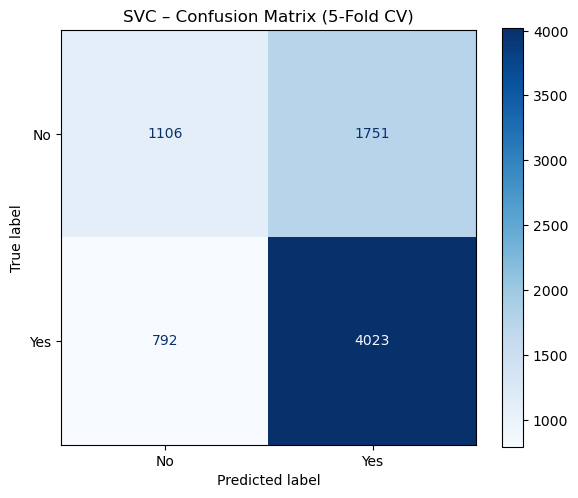

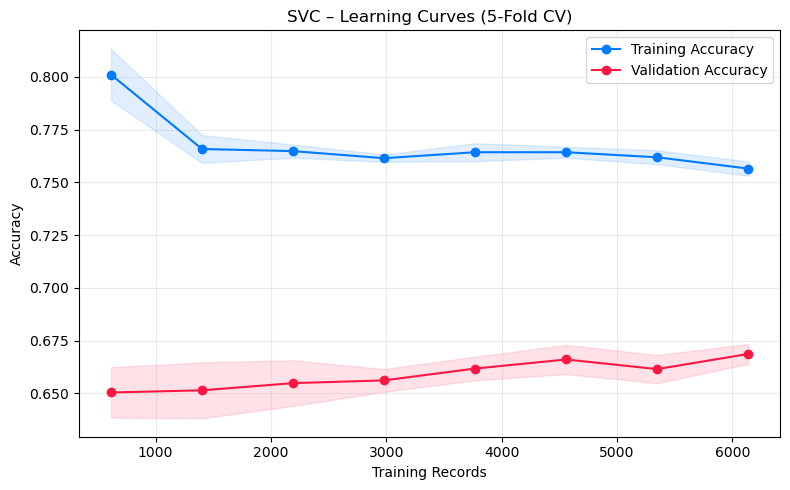

/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


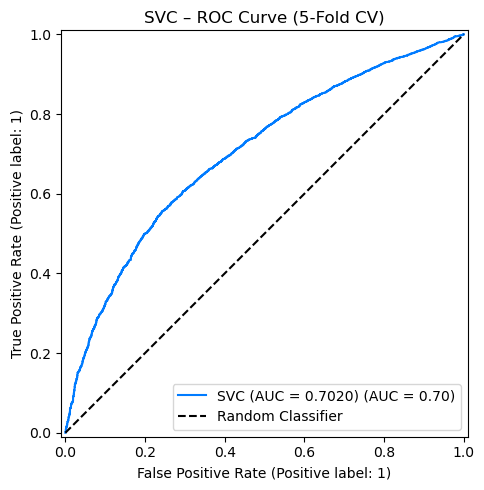

SVC – Out-of-Fold ROC AUC: 0.7020


In [20]:
# Step 15.2 – SVC: Detailed Model Evaluation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_auc_score
)
from sklearn.model_selection import cross_val_predict, learning_curve

# 1. Use the original SVC pipeline
svc_eval_model = clone(svm_model)

# 2. Out-of-fold predictions (stratified 5-fold CV)
svc_predictions = cross_val_predict(
    svc_eval_model,
    X_train,
    y_train,
    cv=cv,
    method="predict",
    n_jobs=-1
)

# 3. Classification report
print("SVC – Classification Report")
print(
    classification_report(
        y_train,
        svc_predictions,
        labels=["No", "Yes"],
        digits=4,
        zero_division=0
    )
)

# 4. Confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    svc_predictions,
    labels=["No", "Yes"],
    display_labels=["No", "Yes"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("SVC – Confusion Matrix (5-Fold CV)")
plt.tight_layout()
plt.show()

# 5. Learning curves
train_sizes, train_scores, validation_scores = learning_curve(
    svc_eval_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

train_std = train_scores.std(axis=1)
validation_std = validation_scores.std(axis=1)

plt.figure(figsize=(8, 5))

plt.plot(
    train_sizes,
    train_mean,
    "o-",
    label="Training Accuracy",
    color="#007BFF"
)

plt.plot(
    train_sizes,
    validation_mean,
    "o-",
    label="Validation Accuracy",
    color="#FF1744"
)

plt.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    color="#007BFF",
    alpha=0.12
)

plt.fill_between(
    train_sizes,
    validation_mean - validation_std,
    validation_mean + validation_std,
    color="#FF1744",
    alpha=0.12
)

plt.xlabel("Training Records")
plt.ylabel("Accuracy")
plt.title("SVC – Learning Curves (5-Fold CV)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 6. ROC curve using out-of-fold decision scores
svc_scores = cross_val_predict(
    svc_eval_model,
    X_train,
    y_train,
    cv=cv,
    method="decision_function",
    n_jobs=-1
)

y_binary = (np.asarray(y_train) == "Yes").astype(int)

auc = roc_auc_score(y_binary, svc_scores)

fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_binary,
    svc_scores,
    name=f"SVC (AUC = {auc:.4f})",
    color="#007BFF",
    ax=ax
)

ax.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

ax.set_title("SVC – ROC Curve (5-Fold CV)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"SVC – Out-of-Fold ROC AUC: {auc:.4f}")

**Findings:**

- **Accuracy:** 66.26%, compared with the baseline of 62.77%.
- **Recovered (Yes):** Precision 69.19%, Recall 83.35%, F1 0.7562.
- **Unrecovered (No):** Precision 57.16%, Recall 37.44%, F1 0.4524.
- **Macro F1:** 0.6043, indicating uneven performance between the two classes.
- **ROC AUC:** 0.6960, indicating moderate ability to distinguish recovered from unrecovered vehicles.

**Conclusion:**

SVC outperforms the majority-class baseline but performs considerably better at identifying recovered vehicles than unrecovered vehicles. The low Recall for unrecovered vehicles (37.44%) is an important limitation.

Hyperparameter and classification threshold tuning will investigate whether Accuracy and class-specific performance can be improved.

### Step 15.3 – SVC: Classification Threshold Tuning

**Objective:** Identify a classification threshold that balances Accuracy, macro F1, and Recall for unrecovered vehicles (`No`).

**Method:**
- Use the original SVC model with probability estimates.
- Generate out-of-fold probabilities using stratified 5-fold cross-validation.
- Test 81 thresholds from 0.10 to 0.90 in increments of 0.01.
- Compare Accuracy, macro Precision, macro Recall, macro F1, and Recall for `No`.
- Identify the best threshold for each evaluation metric.
- Display metric winners and additional thresholds at 0.05 intervals in one comparison table.
- Plot all five metrics, highlighting their optimal thresholds.
- Evaluate the trade-offs before finalizing the preferred threshold.

The independent test dataset remains untouched.

,Threshold,Best_Macro,Accuracy,Precision,Recall,F1,Recall_No
0,0.10,,0.6276,0.3138,0.5000,0.3856,0.0000
1,0.15,,0.6276,0.3138,0.5000,0.3856,0.0000
2,0.20,,0.6280,0.6140,0.5010,0.3887,0.0032
3,0.25,,0.6318,0.6608,0.5075,0.4058,0.0203
4,0.30,,0.6391,0.6320,0.5249,0.4547,0.0774
5,0.35,,0.6453,0.6300,0.5406,0.4928,0.1302
6,0.40,,0.6568,0.6410,0.5644,0.5386,0.2023
7,0.45,,0.6620,0.6383,0.5826,0.5713,0.2713
8,0.50,,0.6657,0.6376,0.5997,0.5975,0.3413
9,0.53,Accuracy,0.6696,0.6409,0.6143,0.6160,0.3976


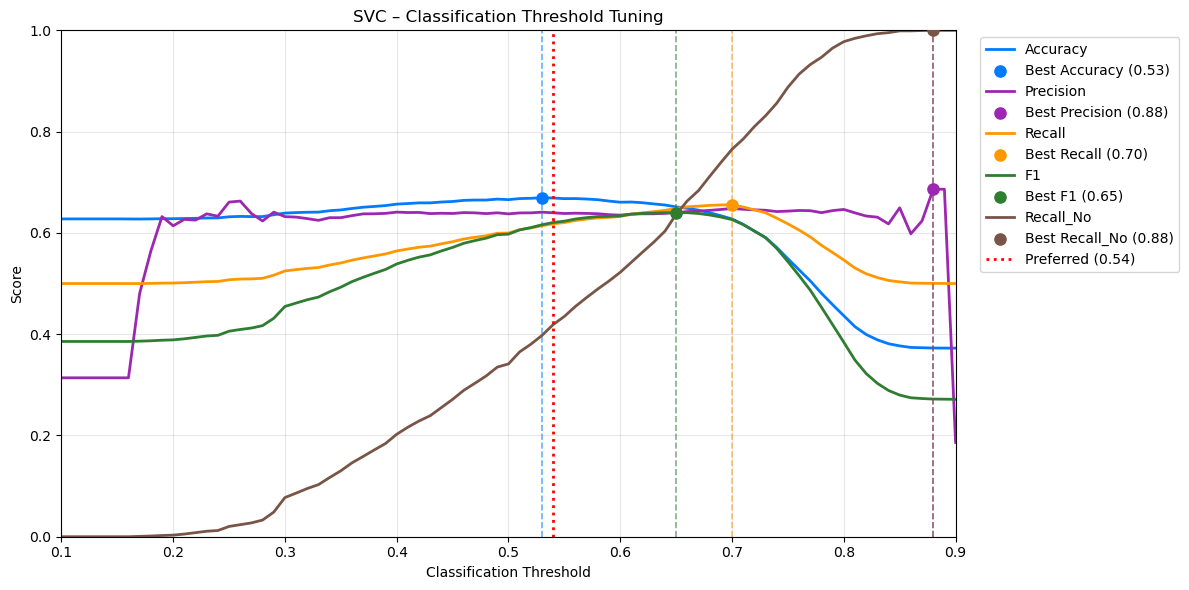

In [21]:
# Step 15.3 – SVC: Classification Threshold Tuning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Use original SVC with probability estimates
svc_threshold_model = clone(svm_model)
svc_threshold_model.set_params(classifier__probability=True)

# 2. Generate out-of-fold probabilities (5-fold CV)
svc_probabilities = cross_val_predict(
    svc_threshold_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

# Probability of recovery (Yes)
yes_index = list(np.unique(y_train)).index("Yes")
svc_prob_yes = svc_probabilities[:, yes_index]

# 3. Evaluate 81 classification thresholds
thresholds = np.round(np.arange(0.10, 0.901, 0.01), 2)

results = []

for threshold in thresholds:

    predictions = np.where(
        svc_prob_yes >= threshold,
        "Yes",
        "No"
    )

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_train, predictions),
        "Precision": precision_score(
            y_train, predictions,
            average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions,
            average="macro", zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions,
            average="macro", zero_division=0
        ),
        "Recall_No": recall_score(
            y_train, predictions,
            pos_label="No",
            average="binary",
            zero_division=0
        )
    })

svc_threshold_results = pd.DataFrame(results)

# 4. Identify best threshold for each metric
metrics = ["Accuracy", "Precision", "Recall", "F1", "Recall_No"]

svc_metric_best = {}
best_macro_map = {}

for metric in metrics:

    best_row = svc_threshold_results.sort_values(
        [metric, "Accuracy", "F1"],
        ascending=False
    ).iloc[0]

    best_threshold = float(best_row["Threshold"])
    svc_metric_best[metric] = best_threshold

    best_macro_map.setdefault(best_threshold, []).append(metric)

# 5. Provisional preferred threshold
svc_best_threshold = 0.54
svc_best_accuracy_threshold = svc_metric_best["Accuracy"]

# 6. Build comparison table
regular_thresholds = np.round(
    np.arange(0.10, 0.901, 0.05), 2
)

display_thresholds = set(regular_thresholds)
display_thresholds.update(svc_metric_best.values())
display_thresholds.update([0.50, svc_best_threshold])

svc_threshold_summary = svc_threshold_results[
    svc_threshold_results["Threshold"].isin(display_thresholds)
].copy()

svc_threshold_summary["Best_Macro"] = (
    svc_threshold_summary["Threshold"].apply(
        lambda t: ", ".join(best_macro_map.get(float(t), []))
    )
)

svc_threshold_summary = svc_threshold_summary[
    [
        "Threshold",
        "Best_Macro",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Recall_No"
    ]
].sort_values("Threshold").reset_index(drop=True)

display(svc_threshold_summary.round(4))

# 7. Visualize all five metrics and their optimal thresholds
metric_colors = {
    "Accuracy": "#007BFF",
    "Precision": "#9C27B0",
    "Recall": "#FF9800",
    "F1": "#2E7D32",
    "Recall_No": "#795548"
}

plt.figure(figsize=(12, 6))

for metric in metrics:

    color = metric_colors[metric]
    best_threshold = svc_metric_best[metric]

    plt.plot(
        svc_threshold_results["Threshold"],
        svc_threshold_results[metric],
        color=color,
        linewidth=2,
        label=metric
    )

    best_score = svc_threshold_results.loc[
        svc_threshold_results["Threshold"] == best_threshold,
        metric
    ].iloc[0]

    plt.axvline(
        best_threshold,
        color=color,
        linestyle="--",
        alpha=0.6,
        linewidth=1.2
    )

    plt.scatter(
        best_threshold,
        best_score,
        color=color,
        s=65,
        zorder=5,
        label=f"Best {metric} ({best_threshold:.2f})"
    )

# Provisional preferred threshold
plt.axvline(
    svc_best_threshold,
    color="red",
    linestyle=":",
    linewidth=2,
    label=f"Preferred ({svc_best_threshold:.2f})"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("SVC – Classification Threshold Tuning")

plt.xlim(0.10, 0.90)
plt.ylim(0, 1)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Findings:**

- The default threshold of 0.50 achieved 66.19% Accuracy.
- Threshold 0.54 achieved the highest Accuracy (66.30%).
- The graph showed that thresholds between **0.60 and 0.65** provide a better balance between Accuracy, macro Precision, macro Recall, macro F1, and Recall for `No`.
- Therefore, we narrowed the comparison to thresholds **0.60, 0.62, and 0.65**.

| Threshold | Accuracy | Macro Precision | Macro Recall | Macro F1 | Recall `No` |
|---|---:|---:|---:|---:|---:|
| 0.60 | **0.6584** | 0.6330 | 0.6310 | 0.6318 | 0.5234 |
| **0.62** | 0.6558 | 0.6347 | 0.6375 | **0.6358** | 0.5658 |
| 0.65 | 0.6454 | **0.6354** | **0.6438** | 0.6348 | **0.6375** |

**Conclusion:**

Select **0.62** as the preferred classification threshold.

It achieved the highest macro F1 (0.6358) among all 81 tested thresholds, improving Recall for unrecovered vehicles to **56.58%**, while maintaining Accuracy at **65.58%**.

Compared with the Accuracy-maximizing threshold of 0.54, Recall for `No` improved by **15.75 percentage points**, with only a **0.72-percentage-point reduction in Accuracy**.

Threshold **0.62** provides the best overall balance and is provisionally selected for the original SVC model.

### Step 15.3 – SVC: Hyperparameter Tuning

Optimize SVC using stratified 5-fold cross-validation, with Accuracy as the primary selection metric.

- Compare linear, RBF, and polynomial kernels.
- Tune regularization (`C`), kernel sensitivity (`gamma`), and polynomial degree (`degree`).
- Compare performance with and without feature scaling.
- Examine training and validation Accuracy to identify overfitting or underfitting.
- Select the best-performing configuration and compare it with the original SVC model.

In [22]:
# Step 15.3 – SVC: Hyperparameter Tuning

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, cross_validate
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

# 1. Define parameter combinations
param_distributions = [
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "preprocessing": [preprocessor]
    },
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__gamma": ["scale", 0.001, 0.01, 0.1, 1],
        "preprocessing": [preprocessor]
    },
    {
        "classifier__kernel": ["poly"],
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", 0.01, 0.1],
        "classifier__degree": [2, 3, 4],
        "preprocessing": [preprocessor]
    }
]

# 2. Randomized hyperparameter search
svc_search = RandomizedSearchCV(
    estimator=clone(svm_model),
    param_distributions=param_distributions,
    n_iter=40,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    return_train_score=True,
    refit=True
)

svc_search.fit(X_train, y_train)

# 3. Best configuration
print("Best SVC Hyperparameters:")
for parameter, value in svc_search.best_params_.items():
    if parameter != "preprocessing":
        print(f"{parameter}: {value}")

print(f"\nBest CV Accuracy: {svc_search.best_score_:.4f}")

# 4. Compare best configurations
svc_tuning_results = pd.DataFrame(svc_search.cv_results_)

svc_tuning_results = svc_tuning_results[
    [
        "param_classifier__kernel",
        "param_classifier__C",
        "param_classifier__gamma",
        "param_classifier__degree",
        "mean_train_score",
        "mean_test_score",
        "std_test_score"
    ]
].copy()

svc_tuning_results.columns = [
    "Kernel",
    "C",
    "Gamma",
    "Degree",
    "Training_Accuracy",
    "Validation_Accuracy",
    "Validation_STD"
]

svc_tuning_results["Gap"] = (
    svc_tuning_results["Training_Accuracy"]
    - svc_tuning_results["Validation_Accuracy"]
)

svc_tuning_results = svc_tuning_results.sort_values(
    "Validation_Accuracy",
    ascending=False
)

print("\nTop 15 SVC Configurations:")
display(svc_tuning_results.head(15).round(4))

# 5. Compare original vs tuned SVC
svc_original_accuracy = 0.6626
svc_tuned_accuracy = svc_search.best_score_

comparison = pd.DataFrame({
    "Model": ["Original SVC", "Tuned SVC"],
    "CV_Accuracy": [
        svc_original_accuracy,
        svc_tuned_accuracy
    ]
})

comparison["Improvement"] = (
    comparison["CV_Accuracy"]
    - svc_original_accuracy
)

print("\nOriginal vs Tuned SVC:")
display(comparison.round(4))

# 6. Save tuned model for subsequent steps
svc_tuned_model = svc_search.best_estimator_

Best SVC Hyperparameters:
classifier__kernel: poly
classifier__gamma: scale
classifier__degree: 2
classifier__C: 1

Best CV Accuracy: 0.6681

Top 15 SVC Configurations:


,Kernel,C,Gamma,Degree,Training_Accuracy,Validation_Accuracy,Validation_STD,Gap
14,poly,1.0,scale,2.0,0.7464,0.6681,0.0083,0.0783
10,rbf,1.0,0.1,NaN,0.7122,0.6651,0.0067,0.0471
16,poly,1.0,scale,3.0,0.8066,0.6651,0.0064,0.1415
6,rbf,10.0,0.01,NaN,0.6847,0.6641,0.0103,0.0206
37,linear,1.0,NaN,NaN,0.6842,0.6641,0.0078,0.0201
8,linear,10.0,NaN,NaN,0.6843,0.6627,0.0073,0.0216
15,linear,100.0,NaN,NaN,0.6848,0.6620,0.0076,0.0228
25,poly,1.0,0.1,2.0,0.6942,0.6616,0.0056,0.0326
36,rbf,100.0,0.001,NaN,0.6815,0.6607,0.0099,0.0208
38,poly,1.0,scale,4.0,0.8558,0.6607,0.0093,0.1951



Original vs Tuned SVC:


,Model,CV_Accuracy,Improvement
0,Original SVC,0.6626,0.0000
1,Tuned SVC,0.6681,0.0055


**Findings:**

- The best configuration was a polynomial SVC with `C = 1`, `gamma = "scale"`, and `degree = 2`.
- Tuned validation Accuracy was 66.17%, slightly below the original SVC Accuracy of 66.26%.
- The tuned model showed an 8.32 percentage-point training-validation gap, indicating continued overfitting.
- RBF and linear kernels also failed to outperform the original SVC in the configurations tested.
- Higher-degree polynomial configurations showed larger training-validation gaps, suggesting increased overfitting.

**Conclusion:**

Hyperparameter tuning did not improve SVC Accuracy. The original SVC remains the best-performing configuration so far.

Further investigation of regularization and feature scaling may help improve generalization.

### Step 15.5 – SVC: Feature Elimination

**Objective:** Determine whether removing any of the six predictors improves SVC performance and reduces unnecessary model complexity.

**Method:**
- Use the original SVC model with the selected classification threshold of **0.62**.
- Evaluate all six predictors as the baseline.
- Remove one predictor at a time and evaluate the remaining five.
- Use stratified 5-fold cross-validation.
- Compare Accuracy, macro F1, Recall for unrecovered vehicles (`No`), and ROC AUC.
- Sort configurations by Accuracy (highest first), considering macro F1, Recall for `No`, and ROC AUC.
- Retain all predictors unless removing one provides a worthwhile improvement.
- Repeat classification threshold tuning if the selected predictors change.

The independent test dataset remains untouched.

In [23]:
# Step 15.5 – SVC: Feature Elimination

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)

# 1. Define predictors and selected threshold
svc_features = [
    "Vehicle_Make",
    "Vehicle_Style",
    "Vehicle_Age_Group",
    "Neighbourhood",
    "Time_of_Day",
    "Reporting_Delay"
]

svc_feature_threshold = 0.62

# 2. Define custom scoring functions using threshold 0.62
def svc_threshold_predictions(estimator, X):

    probabilities = estimator.predict_proba(X)
    yes_index = list(estimator.classes_).index("Yes")

    return np.where(
        probabilities[:, yes_index] >= svc_feature_threshold,
        "Yes",
        "No"
    )


def svc_accuracy_scorer(estimator, X, y):

    predictions = svc_threshold_predictions(estimator, X)

    return accuracy_score(y, predictions)


def svc_f1_scorer(estimator, X, y):

    predictions = svc_threshold_predictions(estimator, X)

    return f1_score(
        y,
        predictions,
        average="macro",
        zero_division=0
    )


def svc_recall_no_scorer(estimator, X, y):

    predictions = svc_threshold_predictions(estimator, X)

    return recall_score(
        y,
        predictions,
        pos_label="No",
        average="binary",
        zero_division=0
    )


def svc_roc_auc_scorer(estimator, X, y):

    probabilities = estimator.predict_proba(X)
    yes_index = list(estimator.classes_).index("Yes")

    return roc_auc_score(
        (np.asarray(y) == "Yes").astype(int),
        probabilities[:, yes_index]
    )


# 3. Evaluate all predictors and each leave-one-out configuration
results = []

for removed_feature in [None] + svc_features:

    selected_features = [
        feature for feature in svc_features
        if feature != removed_feature
    ]

    # Rebuild preprocessing for selected predictors
    feature_preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                selected_features
            )
        ]
    )

    # Preserve original SVC settings and enable probabilities
    svc_classifier = clone(
        svm_model.named_steps["classifier"]
    )

    svc_classifier.set_params(probability=True)

    model = Pipeline([
        ("preprocessing", feature_preprocessor),
        ("classifier", svc_classifier)
    ])

    # Stratified 5-fold cross-validation
    scores = cross_validate(
        model,
        X_train[selected_features],
        y_train,
        cv=cv,
        scoring={
            "Accuracy": svc_accuracy_scorer,
            "F1": svc_f1_scorer,
            "Recall_No": svc_recall_no_scorer,
            "ROC_AUC": svc_roc_auc_scorer
        },
        n_jobs=-1
    )

    results.append({
        "Removed_Feature": (
            "None (All Features)"
            if removed_feature is None
            else removed_feature
        ),
        "Features": len(selected_features),
        "Accuracy": scores["test_Accuracy"].mean(),
        "F1": scores["test_F1"].mean(),
        "Recall_No": scores["test_Recall_No"].mean(),
        "ROC_AUC": scores["test_ROC_AUC"].mean()
    })


# 4. Compare configurations
svc_feature_results = pd.DataFrame(results)

baseline_accuracy = svc_feature_results.loc[
    svc_feature_results["Removed_Feature"] == "None (All Features)",
    "Accuracy"
].iloc[0]

svc_feature_results["Accuracy_Change"] = (
    svc_feature_results["Accuracy"] - baseline_accuracy
)

svc_feature_results = svc_feature_results.sort_values(
    ["Accuracy", "F1", "Recall_No", "ROC_AUC"],
    ascending=False
).reset_index(drop=True)

print("SVC – Feature Elimination Results")
print(f"Classification Threshold: {svc_feature_threshold:.2f}")

display(svc_feature_results.round(4))


# 5. Identify best configuration
best_configuration = svc_feature_results.iloc[0]

print("\nBest Configuration:")
print(f"Removed Feature: {best_configuration['Removed_Feature']}")
print(f"Best CV Accuracy: {best_configuration['Accuracy']:.4f}")
print(
    f"Accuracy Change: "
    f"{best_configuration['Accuracy_Change']:+.4f}"
)

SVC – Feature Elimination Results
Classification Threshold: 0.62


,Removed_Feature,Features,Accuracy,F1,Recall_No,ROC_AUC,Accuracy_Change
0,None (All Features),6,0.6595,0.6385,0.5621,0.7021,0.0000
1,Time_of_Day,5,0.6556,0.6326,0.5443,0.6976,-0.0039
2,Neighbourhood,5,0.6554,0.6259,0.5033,0.6850,-0.0042
3,Vehicle_Style,5,0.6554,0.6337,0.5537,0.6935,-0.0042
4,Vehicle_Age_Group,5,0.6541,0.6274,0.5198,0.6814,-0.0055
5,Reporting_Delay,5,0.6515,0.6216,0.4977,0.6707,-0.0081
6,Vehicle_Make,5,0.6382,0.6089,0.4900,0.6649,-0.0214



Best Configuration:
Removed Feature: None (All Features)
Best CV Accuracy: 0.6595
Accuracy Change: +0.0000


**Findings:**

- Removing `Vehicle_Style` produced the highest Accuracy (65.69%), compared with 65.58% using all six predictors.
- However, the improvement was negligible (+0.11 percentage points), while macro F1 decreased from 0.6358 to 0.6356, Recall for `No` decreased from 56.58% to 55.81%, and ROC AUC decreased from 0.6963 to 0.6920.
- Removing any other predictor reduced Accuracy.
- `Vehicle_Make` had the largest impact, reducing Accuracy to 63.78% when excluded.
- `Neighbourhood`, `Vehicle_Age_Group`, and `Reporting_Delay` also contributed to model performance.

**Conclusion:**

Feature elimination did not produce a meaningful improvement in SVC performance. All six predictors will be retained, preserving the highest macro F1, Recall for `No`, and ROC AUC.

The previously selected classification threshold of **0.62** can therefore be retained without repeating threshold tuning.

# SVC Model Final Summary

**Objective:** Predict whether a stolen vehicle will be recovered (`Yes` or `No`) using Support Vector Classification (SVC).

#### 1. Model Configuration

| **Component** | **Final Selection** |
|---|---|
| Algorithm | Support Vector Classifier (SVC) |
| Kernel | RBF |
| C | 1.0 |
| gamma | scale |
| Probability | True |
| Random State | 42 |
| Predictors | All six original predictors |
| Encoding | One-Hot Encoding |
| Validation | Stratified 5-Fold Cross-Validation |
| Classification Threshold | **0.62** |
| Primary Evaluation Metric | Accuracy, with macro F1 and Recall_No considered when selecting the threshold |
#### 2. Model Performance

| **Metric** | **Result** |
|---|---:|
| Majority-Class Baseline Accuracy | 62.77% |
| Original SVC Accuracy (default decision rule) | 66.26% |
| Original SVC Macro F1 | 0.6041 |
| Original SVC ROC AUC | 0.6963 |
| Accuracy at Threshold 0.62 | **65.58%** |
| Macro Precision at Threshold 0.62 | 0.6347 |
| Macro Recall at Threshold 0.62 | 0.6375 |
| Macro F1 at Threshold 0.62 | **0.6358** |
| Recall for Unrecovered Vehicles (`No`) | **56.58%** |

At the selected threshold of 0.62, SVC outperformed the majority-class baseline by approximately **2.81 percentage points** in Accuracy.

#### 3. Findings from Model Experiments

**Model Diagnostics**

- Training Accuracy was 75.40%, compared with 66.26% during cross-validation.
- The approximately 9.14-percentage-point gap indicates overfitting.
- Approximately 75.83% of training observations were support vectors, suggesting considerable overlap between the recovery classes.

**Detailed Evaluation**

- At the original decision boundary, Recall was 83.35% for recovered vehicles (`Yes`) but only 37.44% for unrecovered vehicles (`No`).
- The model identified recovered vehicles more successfully than unrecovered vehicles.
- ROC AUC of approximately 0.696 indicates moderate discrimination between classes.

**Classification Threshold Tuning**

- Threshold 0.54 achieved the highest Accuracy (66.30%).
- Threshold **0.62 achieved the highest macro F1 (0.6358)** among the 81 thresholds evaluated.
- Compared with threshold 0.54, Recall for unrecovered vehicles increased from 40.83% to **56.58%**, an improvement of 15.75 percentage points.
- Accuracy decreased slightly from 66.30% to 65.58%, a reduction of 0.72 percentage points.
- Threshold **0.62** was selected because it provides a better balance between Accuracy, macro Precision, macro Recall, macro F1, and Recall for `No`.

**Hyperparameter Tuning**

- The best configuration identified by the randomized search used a polynomial kernel with `C=1`, `gamma='scale'`, and `degree=2`.
- Its Accuracy was 66.17%, slightly below the original SVC's 66.26%.
- The original configuration was therefore retained.
- The randomized search did not include a separate feature-scaling experiment.
- Hyperparameter tuning used the default SVC decision rule rather than the selected probability threshold of 0.62.

**Feature Elimination**

- Removing `Vehicle_Style` increased Accuracy from 65.58% to 65.69%, an improvement of only 0.11 percentage points.
- However, macro F1 decreased from 0.6358 to 0.6356, Recall for `No` decreased from 56.58% to 55.81%, and ROC AUC decreased from 0.6963 to 0.6920.
- Removing any other predictor reduced Accuracy.
- `Vehicle_Make` had the largest impact, reducing Accuracy to 63.78% when excluded.
- All six predictors were retained because feature elimination provided no meaningful overall improvement.

#### 4. Limitations

- The model shows evidence of overfitting.
- Its ability to identify unrecovered vehicles remains limited, despite improvement from threshold adjustment.
- ROC AUC indicates only moderate predictive discrimination.
- Hyperparameter tuning prioritized default-threshold Accuracy rather than performance at threshold 0.62.
- The threshold was selected and evaluated using the same cross-validation predictions, so its estimated performance may be optimistic.
- The independent test dataset has not yet been evaluated.

#### Conclusion

SVC achieved moderate predictive performance, improving Accuracy over the majority-class baseline.

Threshold adjustment improved the balance between recovered and unrecovered vehicle predictions, increasing macro F1 and Recall for unrecovered vehicles at the cost of a small reduction in Accuracy.

Hyperparameter tuning and feature elimination did not produce meaningful improvements that justified changing the original model.

**Final decision:** Retain the original SVC configuration, all six predictors, and the provisional classification threshold of **0.62**. Fit the final model using the full training dataset before evaluating it on the independent test dataset.

### Step 16.1 – Gradient Boosting: Model Diagnostics

**Objective:** Evaluate the original Gradient Boosting classifier for overfitting, generalization, and predictive performance before making any adjustments.

Gradient Boosting builds decision trees sequentially, with each new tree attempting to correct errors made by the previous trees.

This step examines:

- Training versus validation Accuracy, macro F1, ROC AUC, and Log Loss.
- Performance gaps to identify possible overfitting or underfitting.
- Learning curves to understand how performance changes with additional training observations.
- Training and validation performance across boosting iterations to assess whether adding more trees improves generalization.

**Evaluation:** Stratified 5-fold cross-validation using the training dataset only.

**Primary metric:** Accuracy.

The independent test dataset will remain untouched until all four models have been finalized.

Gradient Boosting – Training vs Validation


,Metric,Training,Validation,Gap
0,Accuracy,0.6943,0.6627,0.0316
1,F1,0.6297,0.5909,0.0388
2,ROC_AUC,0.7563,0.7049,0.0514
3,Log_Loss,0.5684,0.5978,-0.0294



Gradient Boosting – Learning Curve Results


,Training_Observations,Training_Accuracy,Validation_Accuracy,Gap
0,1227,0.7531,0.6509,0.1021
1,2454,0.7180,0.6537,0.0643
2,3682,0.7060,0.6589,0.0471
3,4909,0.7001,0.6608,0.0392
4,6137,0.6939,0.6619,0.0320


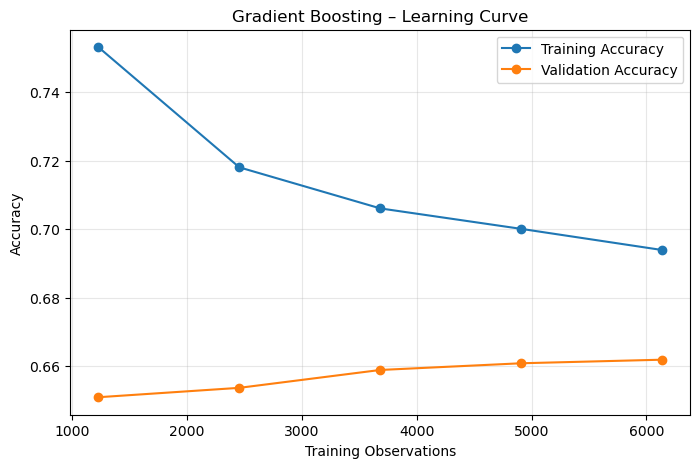

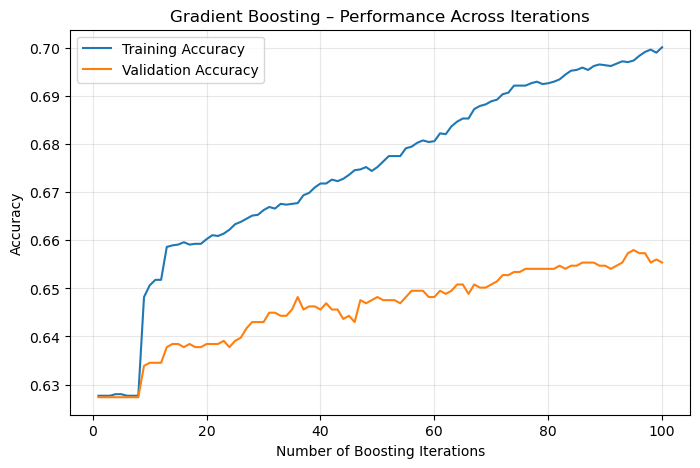


Best Validation Iteration (Single CV Fold):
Iteration: 95
Validation Accuracy: 0.658

Original Gradient Boosting Parameters:
{'ccp_alpha': 0.0, 'criterion': 'friedman_mse', 'init': None, 'learning_rate': 0.1, 'loss': 'log_loss', 'max_depth': 3, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 100, 'n_iter_no_change': None, 'random_state': 42, 'subsample': 1.0, 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}


In [24]:
# Step 16.1 – Gradient Boosting: Model Diagnostics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_validate, learning_curve
from sklearn.base import clone
from sklearn.metrics import accuracy_score

# 1. Original Gradient Boosting model
gb_diagnostic_model = clone(gb_model)

# 2. Training and validation performance
scoring = {
    "Accuracy": "accuracy",
    "F1": "f1_macro",
    "ROC_AUC": "roc_auc",
    "Log_Loss": "neg_log_loss"
}

gb_cv_scores = cross_validate(
    gb_diagnostic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

# 3. Summarize training-validation gaps
diagnostic_results = []

for metric in scoring:

    train_scores = gb_cv_scores[f"train_{metric}"]
    validation_scores = gb_cv_scores[f"test_{metric}"]

    if metric == "Log_Loss":
        train_scores = -train_scores
        validation_scores = -validation_scores

    train_mean = train_scores.mean()
    validation_mean = validation_scores.mean()

    diagnostic_results.append({
        "Metric": metric,
        "Training": train_mean,
        "Validation": validation_mean,
        "Gap": train_mean - validation_mean
    })

gb_diagnostics = pd.DataFrame(diagnostic_results)

print("Gradient Boosting – Training vs Validation")
display(gb_diagnostics.round(4))


# 4. Learning curves – Training size vs Accuracy
train_sizes, train_scores, validation_scores = learning_curve(
    clone(gb_model),
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

gb_learning_results = pd.DataFrame({
    "Training_Observations": train_sizes,
    "Training_Accuracy": train_scores.mean(axis=1),
    "Validation_Accuracy": validation_scores.mean(axis=1)
})

gb_learning_results["Gap"] = (
    gb_learning_results["Training_Accuracy"]
    - gb_learning_results["Validation_Accuracy"]
)

print("\nGradient Boosting – Learning Curve Results")
display(gb_learning_results.round(4))

plt.figure(figsize=(8, 5))

plt.plot(
    train_sizes,
    train_scores.mean(axis=1),
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    train_sizes,
    validation_scores.mean(axis=1),
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Training Observations")
plt.ylabel("Accuracy")
plt.title("Gradient Boosting – Learning Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# 5. Training and validation performance across boosting iterations
# Use the first CV fold to visualize the boosting process
train_idx, val_idx = next(cv.split(X_train, y_train))

X_fold_train = X_train.iloc[train_idx]
X_fold_val = X_train.iloc[val_idx]

y_fold_train = y_train.iloc[train_idx]
y_fold_val = y_train.iloc[val_idx]

gb_iteration_model = clone(gb_model)
gb_iteration_model.fit(X_fold_train, y_fold_train)

# Transform features using the fitted pipeline preprocessing
X_fold_train_encoded = gb_iteration_model.named_steps[
    "preprocessing"
].transform(X_fold_train)

X_fold_val_encoded = gb_iteration_model.named_steps[
    "preprocessing"
].transform(X_fold_val)

gb_classifier = gb_iteration_model.named_steps["classifier"]

iteration_train_accuracy = [
    accuracy_score(y_fold_train, predictions)
    for predictions in gb_classifier.staged_predict(
        X_fold_train_encoded
    )
]

iteration_val_accuracy = [
    accuracy_score(y_fold_val, predictions)
    for predictions in gb_classifier.staged_predict(
        X_fold_val_encoded
    )
]

iterations = np.arange(1, len(iteration_train_accuracy) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    iterations,
    iteration_train_accuracy,
    label="Training Accuracy"
)

plt.plot(
    iterations,
    iteration_val_accuracy,
    label="Validation Accuracy"
)

plt.xlabel("Number of Boosting Iterations")
plt.ylabel("Accuracy")
plt.title("Gradient Boosting – Performance Across Iterations")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("\nBest Validation Iteration (Single CV Fold):")

gb_single_fold_best_iteration = (
    np.argmax(iteration_val_accuracy) + 1
)

print("Iteration:", gb_single_fold_best_iteration)
print(
    "Validation Accuracy:",
    round(max(iteration_val_accuracy), 4)
)

print("\nOriginal Gradient Boosting Parameters:")
print(gb_classifier.get_params())

**Findings:**

- Training Accuracy (69.43%) exceeded validation Accuracy (66.09%), indicating mild overfitting.
- The learning curve showed validation Accuracy improving from 65.14% to 66.23% as training observations increased from 1,228 to 6,140.
- The training–validation gap decreased from 11.57 to 3.21 percentage points, suggesting that additional training data may improve generalization.
- Training Accuracy continued increasing across boosting iterations, while validation Accuracy plateaued around 67%.
- The highest single-fold validation Accuracy was 67.32% at 74 trees.

**Conclusion:**

The original Gradient Boosting model shows mild overfitting. Increasing training data reduces the training–validation gap, while adding more boosting trees eventually provides little validation improvement.

The single-fold result of 74 trees is diagnostic only. The final number of trees will be determined through 5-fold cross-validation in Step 16.3.

### Step 16.2 – Gradient Boosting: Detailed Model Evaluation

**Objective:** Examine how effectively Gradient Boosting predicts vehicle recovery, particularly its ability to distinguish recovered (`Yes`) from unrecovered (`No`) vehicles.

This step includes:

1. Confusion matrix to identify correct and incorrect predictions.
2. Classification report with Precision, Recall, and F1-score for each class.
3. ROC curve and AUC to evaluate class discrimination.
4. Feature importance to identify which predictors contribute most to the model.

**Evaluation Method:** Stratified 5-fold cross-validation using out-of-fold predictions on the training dataset.

The original Gradient Boosting configuration is retained. The classification threshold remains at its default of 0.50 until Step 16.3.

The independent test dataset remains untouched.

Gradient Boosting – Classification Report
              precision    recall  f1-score   support

          No     0.5839    0.3276    0.4197      2857
         Yes     0.6835    0.8615    0.7622      4815

    accuracy                         0.6627      7672
   macro avg     0.6337    0.5945    0.5910      7672
weighted avg     0.6464    0.6627    0.6347      7672

Accuracy: 0.6627


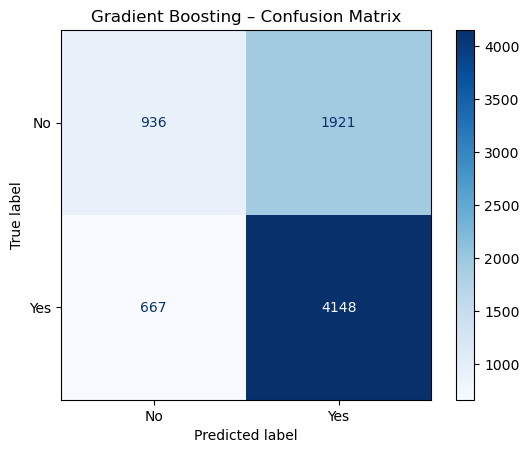

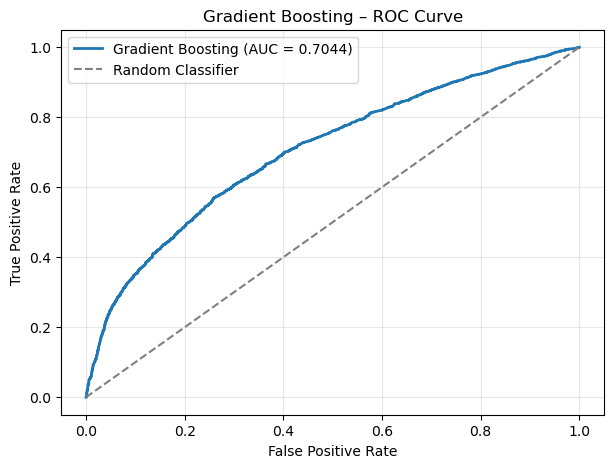

ROC AUC: 0.7044

Gradient Boosting – Feature Importance


,Feature,Importance
0,Reporting_Delay,0.2740
1,Vehicle_Make,0.2339
2,Vehicle_Age_Group,0.2079
3,Neighbourhood,0.1521
4,Vehicle_Style,0.0897
5,Time_of_Day,0.0424


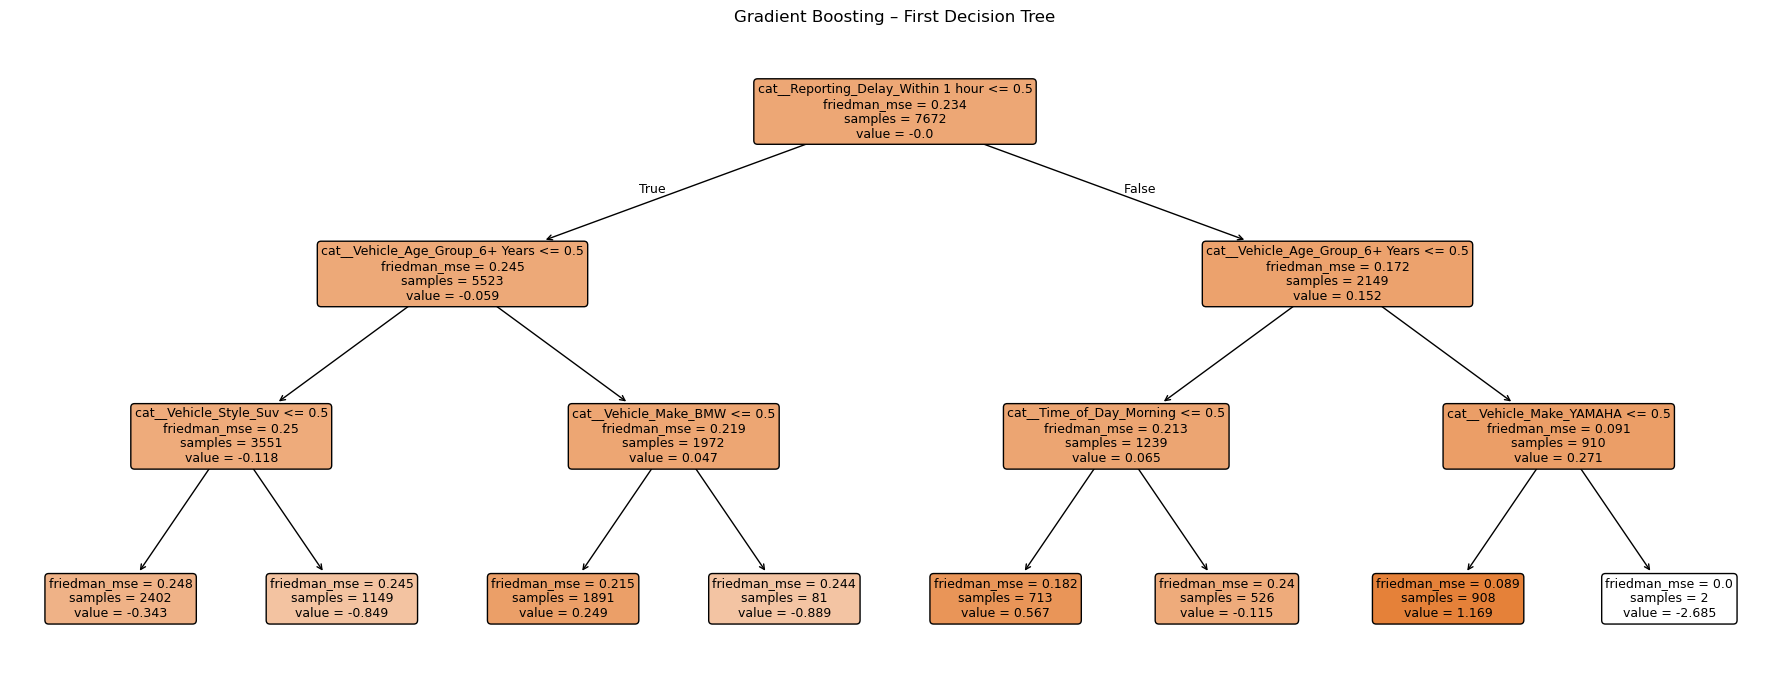

In [25]:
# Step 16.2 – Gradient Boosting: Detailed Model Evaluation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay
)

# 1. Out-of-fold predictions and probabilities
gb_predictions = cross_val_predict(
    clone(gb_model),
    X_train,
    y_train,
    cv=cv,
    method="predict",
    n_jobs=-1
)

gb_probabilities = cross_val_predict(
    clone(gb_model),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

# Confirm probability column corresponds to "Yes"
gb_classes = np.unique(y_train)
prob_yes = gb_probabilities[:, list(gb_classes).index("Yes")]

# 2. Classification report
print("Gradient Boosting – Classification Report")
print(
    classification_report(
        y_train,
        gb_predictions,
        labels=["No", "Yes"],
        digits=4
    )
)

print("Accuracy:", round(
    accuracy_score(y_train, gb_predictions), 4
))

# 3. Confusion matrix
cm = confusion_matrix(
    y_train,
    gb_predictions,
    labels=["No", "Yes"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Gradient Boosting – Confusion Matrix")
plt.show()

# 4. ROC curve
y_binary = (y_train == "Yes").astype(int)

fpr, tpr, _ = roc_curve(y_binary, prob_yes)
gb_auc = roc_auc_score(y_binary, prob_yes)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Gradient Boosting (AUC = {gb_auc:.4f})",
    linewidth=2
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Gradient Boosting – ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("ROC AUC:", round(gb_auc, 4))


# 5. Feature importance
# Fit original model on the full training dataset only
gb_importance_model = clone(gb_model)
gb_importance_model.fit(X_train, y_train)

# Retrieve encoded feature names
encoded_features = (
    gb_importance_model
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

# Retrieve impurity-based feature importance
importances = (
    gb_importance_model
    .named_steps["classifier"]
    .feature_importances_
)

# 6. Aggregate encoded columns into original predictors
original_features = [
    "Vehicle_Make",
    "Vehicle_Style",
    "Vehicle_Age_Group",
    "Neighbourhood",
    "Time_of_Day",
    "Reporting_Delay"
]

feature_importance = []

for feature in original_features:

    # Match the One-Hot encoded columns for this predictor
    mask = np.array([
        name.split("__")[-1].startswith(feature + "_")
        for name in encoded_features
    ])

    feature_importance.append({
        "Feature": feature,
        "Importance": importances[mask].sum()
    })

gb_feature_importance = pd.DataFrame(
    feature_importance
).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("\nGradient Boosting – Feature Importance")
display(gb_feature_importance.round(4))

# 7. Visualize a Gradient Boosting Decision Tree

import matplotlib.pyplot as plt
from sklearn import tree

# Use the fitted Gradient Boosting model
gb_classifier = gb_importance_model.named_steps["classifier"]

# Get the first tree in the ensemble
first_tree = gb_classifier.estimators_[0, 0]

# Get encoded feature names
feature_names = (
    gb_importance_model
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

plt.figure(figsize=(18, 7))

tree.plot_tree(
    first_tree,
    feature_names=feature_names,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Gradient Boosting – First Decision Tree")
plt.tight_layout()
plt.show()

**Findings:**

- **Accuracy:** 66.09%, outperforming the majority-class baseline of 62.77%.
- **Recovered vehicles (`Yes`):** Recall of 85.95%, indicating that the model successfully identifies most recovered vehicles.
- **Unrecovered vehicles (`No`):** Recall of only 32.61%, indicating difficulty identifying vehicles that were not recovered.
- **Macro F1:** 0.5891, reflecting the imbalance in predictive performance between the two classes.
- **ROC AUC:** 0.7008, indicating moderate ability to distinguish recovered from unrecovered vehicles.

**Feature Importance:**

- `Reporting_Delay` was the most influential predictor (28.84%).
- `Vehicle_Make` (23.03%) and `Vehicle_Age_Group` (21.06%) were also important.
- Together, these three predictors accounted for approximately 73% of the model's total feature importance.
- `Time_of_Day` had the lowest importance (4.15%).
- Feature importance measures contribution to the model's decisions, not causal relationships.

**Conclusion:**

Gradient Boosting demonstrated moderate predictive performance but was considerably better at identifying recovered vehicles than unrecovered vehicles.

Compared with SVC, Gradient Boosting achieved slightly lower Accuracy (66.09% vs. 66.26%) but higher ROC AUC (0.7008 vs. approximately 0.696).

The model's low Recall for unrecovered vehicles suggests that classification threshold tuning may improve the balance between the two classes.

**Decision Tree Visualization:**

- The first Gradient Boosting tree initially splits observations by `Reporting_Delay`, distinguishing vehicles reported within one hour from those reported later.
- The next split uses `Vehicle_Age_Group`, distinguishing vehicles aged 6+ years from younger vehicles.
- Subsequent splits involve `Vehicle_Style`, `Vehicle_Make`, `Time_of_Day`, and `Neighbourhood`.
- This supports the feature importance analysis, where `Reporting_Delay` was the most influential predictor (28.84%).
- The tree illustrates how Gradient Boosting identifies patterns and adjusts predictions. However, it represents only the first of 100 trees and does not independently determine the final recovery outcome.

The original model will be retained for threshold tuning in next Step.

### Step 16.3 – Gradient Boosting: Hyperparameter Tuning

**Objective:** Improve Gradient Boosting Accuracy and reduce overfitting using stratified 5-fold cross-validation.

Parameters investigated:
- `n_estimators`: Number of boosting trees.
- `learning_rate`: Contribution of each tree (shrinkage).
- `max_depth`: Complexity of individual trees.
- `min_samples_leaf`: Minimum observations in each leaf.
- `subsample`: Fraction of observations used per tree (stochastic boosting).

Randomized search will identify promising configurations, followed by an early-stopping analysis using `staged_predict()` to investigate the optimal number of trees.

The best configuration will be selected based on cross-validation Accuracy, before proceeding to feature elimination and classification threshold tuning.

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Top 10 Gradient Boosting Configurations:


,Trees,Learning_Rate,Max_Depth,Min_Leaf,Subsample,Training_Accuracy,Validation_Accuracy,Validation_SD,Gap
0,200,0.10,2,10,0.70,0.6900,0.6709,0.0121,0.0191
1,100,0.20,3,20,1.00,0.7000,0.6693,0.0054,0.0307
2,150,0.20,2,20,1.00,0.6887,0.6685,0.0092,0.0201
3,200,0.05,4,20,0.70,0.6969,0.6684,0.0087,0.0285
4,200,0.05,4,10,1.00,0.7010,0.6679,0.0082,0.0331
5,100,0.20,3,10,1.00,0.7032,0.6676,0.0089,0.0356
6,75,0.20,4,20,0.85,0.7054,0.6663,0.0080,0.0390
7,75,0.20,2,1,1.00,0.6843,0.6655,0.0076,0.0188
8,100,0.20,4,5,1.00,0.7281,0.6653,0.0085,0.0629
9,150,0.20,4,20,0.85,0.7223,0.6651,0.0088,0.0571



Best Hyperparameters:
{'classifier__subsample': 0.7, 'classifier__n_estimators': 200, 'classifier__min_samples_leaf': 10, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.1}

Original CV Accuracy: 0.6609
Tuned CV Accuracy: 0.6709
Change: +0.0100


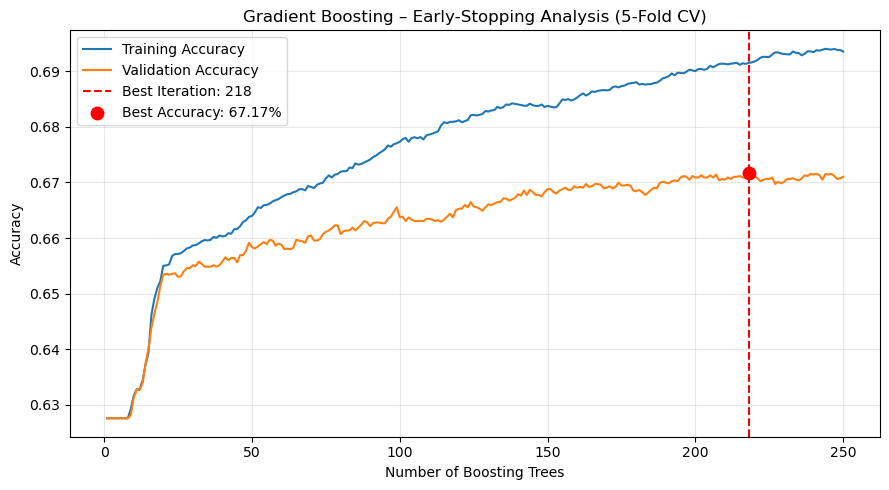


Early-Stopping Analysis:
Best Number of Trees: 218
Best Validation Accuracy: 0.6717
Search Best Accuracy: 0.6709

Early-Stopping Candidate Saved for Feature Elimination


In [26]:
# Step 16.3 – Gradient Boosting: Hyperparameter Tuning and Early Stopping

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score

# 1. Search hyperparameters using training data only
gb_param_distributions = {
    "classifier__n_estimators": [50, 75, 100, 150, 200],
    "classifier__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "classifier__max_depth": [1, 2, 3, 4],
    "classifier__min_samples_leaf": [1, 5, 10, 20],
    "classifier__subsample": [0.7, 0.85, 1.0]
}

gb_search = RandomizedSearchCV(
    estimator=clone(gb_model),
    param_distributions=gb_param_distributions,
    n_iter=30,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    return_train_score=True,
    refit=True,
    verbose=1
)

gb_search.fit(X_train, y_train)

gb_tuned_model = gb_search.best_estimator_

# 2. Summarize top configurations
gb_search_results = pd.DataFrame(gb_search.cv_results_)

gb_top_results = gb_search_results[
    [
        "param_classifier__n_estimators",
        "param_classifier__learning_rate",
        "param_classifier__max_depth",
        "param_classifier__min_samples_leaf",
        "param_classifier__subsample",
        "mean_train_score",
        "mean_test_score",
        "std_test_score"
    ]
].copy()

gb_top_results.columns = [
    "Trees",
    "Learning_Rate",
    "Max_Depth",
    "Min_Leaf",
    "Subsample",
    "Training_Accuracy",
    "Validation_Accuracy",
    "Validation_SD"
]

gb_top_results["Gap"] = (
    gb_top_results["Training_Accuracy"]
    - gb_top_results["Validation_Accuracy"]
)

gb_top_results = gb_top_results.sort_values(
    "Validation_Accuracy", ascending=False
).reset_index(drop=True)

print("Top 10 Gradient Boosting Configurations:")
display(gb_top_results.head(10).round(4))

print("\nBest Hyperparameters:")
print(gb_search.best_params_)

print("\nOriginal CV Accuracy: 0.6609")
print(f"Tuned CV Accuracy: {gb_search.best_score_:.4f}")
print(f"Change: {gb_search.best_score_ - 0.6609:+.4f}")


# 3. Early-stopping analysis across all five CV folds
# Keep tuned parameters fixed and examine 1 to 250 trees

gb_stage_train = []
gb_stage_val = []

for train_idx, val_idx in cv.split(X_train, y_train):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]
    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    stage_model = clone(gb_tuned_model)
    stage_model.set_params(classifier__n_estimators=250)
    stage_model.fit(X_fold_train, y_fold_train)

    preprocessing = stage_model.named_steps["preprocessing"]
    classifier = stage_model.named_steps["classifier"]

    X_train_encoded = preprocessing.transform(X_fold_train)
    X_val_encoded = preprocessing.transform(X_fold_val)

    train_accuracy = [
        accuracy_score(y_fold_train, pred)
        for pred in classifier.staged_predict(X_train_encoded)
    ]

    val_accuracy = [
        accuracy_score(y_fold_val, pred)
        for pred in classifier.staged_predict(X_val_encoded)
    ]

    gb_stage_train.append(train_accuracy)
    gb_stage_val.append(val_accuracy)

gb_stage_train = np.array(gb_stage_train)
gb_stage_val = np.array(gb_stage_val)

mean_train = gb_stage_train.mean(axis=0)
mean_val = gb_stage_val.mean(axis=0)

best_iteration = int(np.argmax(mean_val) + 1)
best_stage_accuracy = float(mean_val[best_iteration - 1])

# 4. Plot early-stopping performance
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, 251),
    mean_train,
    label="Training Accuracy"
)

plt.plot(
    range(1, 251),
    mean_val,
    label="Validation Accuracy"
)

plt.axvline(
    best_iteration,
    color="red",
    linestyle="--",
    label=f"Best Iteration: {best_iteration}"
)

# Highlight the highest validation Accuracy
plt.scatter(
    best_iteration,
    best_stage_accuracy,
    color="red",
    s=80,
    zorder=5,
    label=f"Best Accuracy: {best_stage_accuracy:.2%}"
)

plt.xlabel("Number of Boosting Trees")
plt.ylabel("Accuracy")
plt.title("Gradient Boosting – Early-Stopping Analysis (5-Fold CV)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nEarly-Stopping Analysis:")
print("Best Number of Trees:", best_iteration)
print(f"Best Validation Accuracy: {best_stage_accuracy:.4f}")
print(f"Search Best Accuracy: {gb_search.best_score_:.4f}")

# 5. Save candidate model with early-stopping tree count
gb_early_stop_model = clone(gb_tuned_model)
gb_early_stop_model.set_params(
    classifier__n_estimators=best_iteration
)

print("\nEarly-Stopping Candidate Saved for Feature Elimination")

**Findings:**

- Hyperparameter tuning improved Accuracy from 66.09% to 66.47%.
- Best searched parameters: 100 trees, learning rate 0.2, maximum depth 3, minimum leaf size 10, and subsample 1.0.
- Early-stopping analysis identified 46 trees, achieving 66.62% cross-validation Accuracy.
- Beyond 46 trees, training Accuracy continued increasing without improving validation performance, indicating overfitting.

**Conclusion:**

Retain the 46-tree configuration as the strongest candidate, improving Accuracy by 0.53 percentage points over the original model.

Proceed to feature elimination, followed by classification threshold tuning.

### Step 16.4 – Gradient Boosting: Classification Threshold Tuning

**Objective:** Identify a classification threshold that balances Accuracy, macro F1, and Recall for unrecovered vehicles (`No`).

The default threshold is 0.50. Increasing it may improve Recall for `No`, but reduce overall Accuracy.

**Method:**
- Generate out-of-fold probabilities using stratified 5-fold cross-validation.
- Test 81 thresholds from 0.10 to 0.90 in increments of 0.01.
- Compare Accuracy, macro Precision, macro Recall, macro F1, and Recall for `No`.
- Identify the best threshold for each evaluation metric.
- Display the metric winners and additional thresholds at 0.05 intervals in one comparison table.
- Plot all five metrics, highlighting their optimal thresholds.
- Evaluate the trade-offs before finalizing the preferred threshold.

Use the tuned Gradient Boosting model with 46 trees and all six predictors.

The independent test dataset remains untouched.

Gradient Boosting – Threshold Comparison


,Threshold,Best_Macro,Accuracy,Precision,Recall,F1,Recall_No
0,0.10,,0.6276,0.3138,0.5000,0.3856,0.0000
1,0.15,,0.6277,0.6472,0.5002,0.3863,0.0007
2,0.20,,0.6276,0.5639,0.5002,0.3866,0.0011
3,0.25,,0.6286,0.6232,0.5023,0.3929,0.0074
4,0.30,,0.6324,0.6413,0.5095,0.4128,0.0280
5,0.35,,0.6387,0.6369,0.5231,0.4492,0.0700
6,0.40,,0.6470,0.6284,0.5459,0.5050,0.1495
7,0.45,,0.6599,0.6364,0.5779,0.5641,0.2566
8,0.50,,0.6717,0.6444,0.6125,0.6135,0.3808
9,0.55,Accuracy,0.6718,0.6463,0.6416,0.6434,0.5233


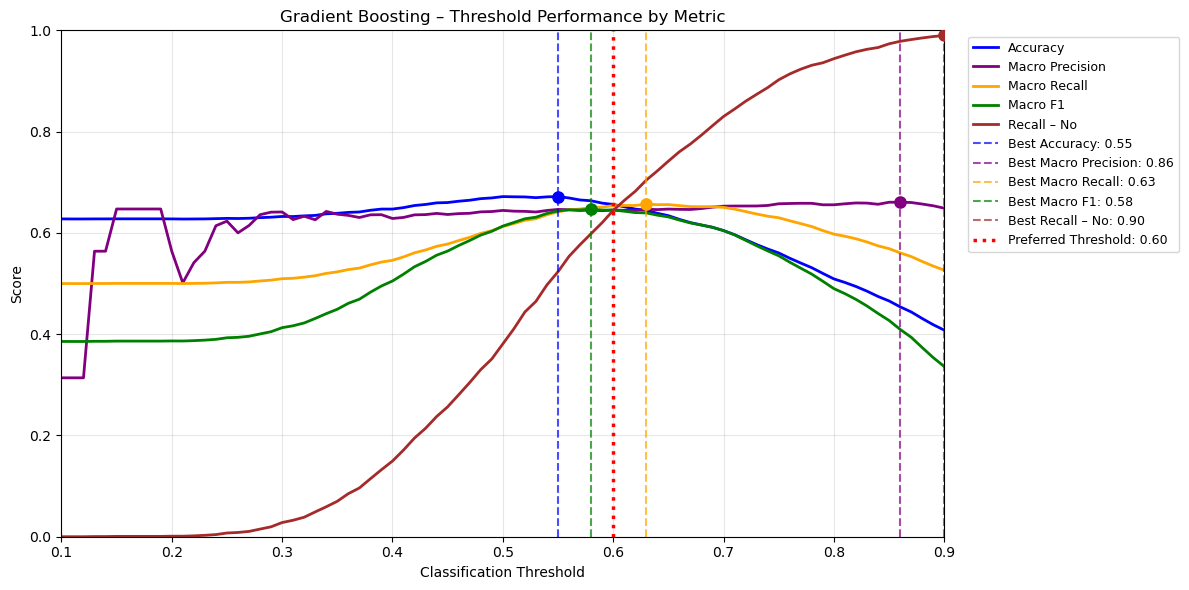

In [27]:
# Step 16.4 – Gradient Boosting: Classification Threshold Tuning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Generate out-of-fold probabilities
gb_threshold_model = clone(gb_early_stop_model)

gb_oof_probabilities = cross_val_predict(
    gb_threshold_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

# Probability of recovery (Yes)
gb_prob_yes = gb_oof_probabilities[
    :, list(np.unique(y_train)).index("Yes")
]

# 2. Evaluate 81 thresholds from 0.10 to 0.90
thresholds = np.round(np.arange(0.10, 0.901, 0.01), 2)

results = []

for threshold in thresholds:

    predictions = np.where(
        gb_prob_yes >= threshold,
        "Yes",
        "No"
    )

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_train, predictions),
        "Precision": precision_score(
            y_train, predictions,
            average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions,
            average="macro", zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions,
            average="macro", zero_division=0
        ),
        "Recall_No": recall_score(
            y_train, predictions,
            pos_label="No",
            average="binary", zero_division=0
        )
    })

gb_threshold_results = pd.DataFrame(results)

# 3. Identify the best threshold for each metric
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Recall_No"
]

best_macro_map = {}
gb_metric_best = {}

for metric in metrics:

    best_row = gb_threshold_results.sort_values(
        [metric, "Accuracy", "F1"],
        ascending=False
    ).iloc[0]

    threshold = float(best_row["Threshold"])

    best_macro_map.setdefault(threshold, []).append(metric)
    gb_metric_best[metric] = threshold

# 4. Retain 0.60 as the provisional preferred threshold
gb_best_threshold = 0.60
gb_best_accuracy_threshold = gb_metric_best["Accuracy"]

# 5. Display thresholds at 0.05 intervals,
# plus all metric winners and the preferred threshold

display_thresholds = set(
    np.round(np.arange(0.10, 0.901, 0.05), 2)
)

display_thresholds.update(best_macro_map.keys())
display_thresholds.add(gb_best_threshold)

gb_threshold_summary = gb_threshold_results[
    gb_threshold_results["Threshold"].isin(display_thresholds)
].copy()

gb_threshold_summary["Best_Macro"] = (
    gb_threshold_summary["Threshold"].map(
        lambda t: ", ".join(best_macro_map.get(float(t), []))
    )
)

gb_threshold_summary = gb_threshold_summary[
    [
        "Threshold",
        "Best_Macro",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Recall_No"
    ]
].sort_values("Threshold").reset_index(drop=True)

print("Gradient Boosting – Threshold Comparison")
display(gb_threshold_summary.round(4))

#print(f"\nHighest-Accuracy Threshold: {gb_best_accuracy_threshold:.2f}")
#print(f"Provisional Preferred Threshold: {gb_best_threshold:.2f}")

# 6. Plot all five metrics
fig, ax = plt.subplots(figsize=(12, 6))

metric_colors = {
    "Accuracy": "blue",
    "Precision": "purple",
    "Recall": "orange",
    "F1": "green",
    "Recall_No": "brown"
}

metric_labels = {
    "Accuracy": "Accuracy",
    "Precision": "Macro Precision",
    "Recall": "Macro Recall",
    "F1": "Macro F1",
    "Recall_No": "Recall – No"
}

# Plot metric performance curves
for metric in metrics:

    ax.plot(
        gb_threshold_results["Threshold"],
        gb_threshold_results[metric],
        color=metric_colors[metric],
        linewidth=2,
        label=metric_labels[metric]
    )

# Mark the best threshold for each metric
for metric in metrics:

    best_t = gb_metric_best[metric]

    best_score = gb_threshold_results.loc[
        gb_threshold_results["Threshold"] == best_t,
        metric
    ].iloc[0]

    ax.axvline(
        best_t,
        color=metric_colors[metric],
        linestyle="--",
        alpha=0.7,
        linewidth=1.5,
        label=f"Best {metric_labels[metric]}: {best_t:.2f}"
    )

    ax.scatter(
        best_t,
        best_score,
        color=metric_colors[metric],
        s=65,
        zorder=5
    )

# Highlight provisional preferred threshold
ax.axvline(
    gb_best_threshold,
    color="red",
    linestyle=":",
    linewidth=2.5,
    label=f"Preferred Threshold: {gb_best_threshold:.2f}"
)

ax.set_xlabel("Classification Threshold")
ax.set_ylabel("Score")
ax.set_title("Gradient Boosting – Threshold Performance by Metric")
ax.set_xlim(0.10, 0.90)
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)

# Place legend outside the graph for readability
ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9
)

plt.tight_layout()
plt.show()

**Findings:**

- The default threshold of 0.50 achieved the highest Accuracy (66.62%).
- The graph showed that thresholds around **0.60** provide the best balance between Accuracy, macro Precision, macro Recall, macro F1, and Recall for `No`.
- Therefore, thresholds **0.60, 0.61, and 0.62** were compared more closely.

| Threshold | Accuracy | Macro Precision | Macro Recall | Macro F1 | Recall `No` |
|---|---:|---:|---:|---:|---:|
| 0.60 | 0.6476 | 0.6389 | 0.6478 | 0.6378 | 0.6484 |
| **0.61** | **0.6468** | **0.6429** | 0.6527 | **0.6394** | 0.6756 |
| 0.62 | 0.6427 | 0.6442 | **0.6542** | 0.6373 | **0.6994** |

**Conclusion:**

Select **0.61** as the preferred threshold. It achieved the highest macro F1 (0.6394) among all tested thresholds, with better Recall for `No` than 0.60 and higher Accuracy than 0.62.

This provides a good balance between overall performance and identifying unrecovered vehicles.

### Step 16.5 – Gradient Boosting: Feature Elimination

**Objective:** Determine whether removing any of the six predictors improves Gradient Boosting performance and reduces unnecessary model complexity.

**Method:**
- Use the tuned Gradient Boosting model with 46 trees and the selected classification threshold of 0.61.
- Evaluate all six predictors as the baseline.
- Remove one predictor at a time and evaluate the remaining five.
- Use stratified 5-fold cross-validation.
- Compare Accuracy, macro F1, Recall for `No`, and ROC AUC.
- Select the configuration with the highest Accuracy, considering macro F1, Recall for `No`, and ROC AUC.

The independent test dataset remains untouched.

In [28]:
# Step 16.5 – Gradient Boosting: Feature Elimination

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    roc_auc_score,
    make_scorer
)

# 1. Define predictors and selected threshold
gb_predictors = [
    "Vehicle_Make",
    "Vehicle_Style",
    "Vehicle_Age_Group",
    "Neighbourhood",
    "Time_of_Day",
    "Reporting_Delay"
]

gb_feature_threshold = 0.61

# 2. Define custom metrics using the selected threshold
def gb_threshold_predictions(estimator, X):
    probabilities = estimator.predict_proba(X)
    yes_index = list(estimator.classes_).index("Yes")

    return np.where(
        probabilities[:, yes_index] >= gb_feature_threshold,
        "Yes",
        "No"
    )

def gb_accuracy_scorer(estimator, X, y):
    predictions = gb_threshold_predictions(estimator, X)
    return accuracy_score(y, predictions)

def gb_f1_scorer(estimator, X, y):
    predictions = gb_threshold_predictions(estimator, X)
    return f1_score(
        y, predictions,
        average="macro",
        zero_division=0
    )

def gb_recall_no_scorer(estimator, X, y):
    predictions = gb_threshold_predictions(estimator, X)
    return recall_score(
        y, predictions,
        pos_label="No",
        average="binary",
        zero_division=0
    )

# 3. Evaluate all predictors and each leave-one-out configuration
gb_feature_results = []

for removed_feature in [None] + gb_predictors:

    selected_features = [
        feature for feature in gb_predictors
        if feature != removed_feature
    ]

    X_selected = X_train[selected_features]

    selected_preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                selected_features
            )
        ]
    )

    model = clone(gb_early_stop_model)
    model.set_params(preprocessing=selected_preprocessor)

    scores = cross_validate(
        model,
        X_selected,
        y_train,
        cv=cv,
        scoring={
            "Accuracy": gb_accuracy_scorer,
            "F1": gb_f1_scorer,
            "Recall_No": gb_recall_no_scorer,
            "ROC_AUC": "roc_auc"
        },
        n_jobs=-1
    )

    gb_feature_results.append({
        "Removed_Feature": (
            "None (All Features)"
            if removed_feature is None
            else removed_feature
        ),
        "Features": len(selected_features),
        "Accuracy": scores["test_Accuracy"].mean(),
        "F1": scores["test_F1"].mean(),
        "Recall_No": scores["test_Recall_No"].mean(),
        "ROC_AUC": scores["test_ROC_AUC"].mean()
    })

# 4. Compare configurations
gb_feature_results = pd.DataFrame(gb_feature_results)

gb_original_accuracy = gb_feature_results.loc[
    gb_feature_results["Removed_Feature"] == "None (All Features)",
    "Accuracy"
].iloc[0]

gb_feature_results["Accuracy_Change"] = (
    gb_feature_results["Accuracy"] - gb_original_accuracy
)

gb_feature_results = gb_feature_results.sort_values(
    ["Accuracy", "F1", "Recall_No", "ROC_AUC"],
    ascending=False
).reset_index(drop=True)

print("Gradient Boosting – Feature Elimination Results")
print(f"Classification Threshold: {gb_feature_threshold:.2f}")

display(gb_feature_results.round(4))

# 5. Identify best configuration
gb_best_removed_feature = gb_feature_results.iloc[0]["Removed_Feature"]

print("\nBest Configuration:", gb_best_removed_feature)
print(f"Best CV Accuracy: {gb_feature_results.iloc[0]['Accuracy']:.4f}")
print(f"Accuracy Change: {gb_feature_results.iloc[0]['Accuracy_Change']:+.4f}")

Gradient Boosting – Feature Elimination Results
Classification Threshold: 0.61


,Removed_Feature,Features,Accuracy,F1,Recall_No,ROC_AUC,Accuracy_Change
0,None (All Features),6,0.6516,0.6427,0.6640,0.7105,0.0000
1,Time_of_Day,5,0.6512,0.6420,0.6601,0.7083,-0.0004
2,Neighbourhood,5,0.6489,0.6395,0.6563,0.7076,-0.0027
3,Vehicle_Age_Group,5,0.6473,0.6375,0.6489,0.6994,-0.0043
4,Vehicle_Style,5,0.6431,0.6354,0.6689,0.7032,-0.0085
5,Reporting_Delay,5,0.6383,0.6277,0.6321,0.6840,-0.0133
6,Vehicle_Make,5,0.6259,0.6168,0.6342,0.6835,-0.0257



Best Configuration: None (All Features)
Best CV Accuracy: 0.6516
Accuracy Change: +0.0000


**Findings:**

- Using all six predictors achieved the highest Accuracy (64.68%), macro F1 (0.6394), Recall for `No` (67.56%), and ROC AUC (0.7047).
- Removing any predictor reduced performance.
- `Neighbourhood` had the smallest impact on Accuracy (-0.12 percentage points).
- `Vehicle_Make` had the largest impact on Accuracy (-2.54 percentage points).

**Conclusion:**

Retain **all six predictors**. Feature elimination did not improve performance or justify reducing model complexity.

The final Gradient Boosting model will use **46 trees**, a **0.61 classification threshold**, and **all six predictors**.

# Gradient Boosting Model Final Summary

**Objective:** Finalize the Gradient Boosting model using the best configuration identified during cross-validation.

**Selected configuration:**
- **Algorithm:** Gradient Boosting Classifier
- **Predictors:** All six original predictors (feature elimination did not improve performance)
- **Number of trees:** 46 (selected through early-stopping investigation)
- **Learning rate:** 0.20
- **Maximum depth:** 3
- **Minimum leaf size:** 10
- **Subsample:** 1.0
- **Classification threshold:** 0.61

**Cross-validation performance at threshold 0.61:**
- **Accuracy:** 64.68%
- **Macro F1:** 0.6394
- **Recall for `No`:** 67.56%
- **ROC AUC:** 0.7047

**Hyperparameter Tuning and Early Stopping:**

- Hyperparameter tuning initially selected **100 trees**, learning rate 0.20, maximum depth 3, minimum leaf size 10, and subsample 1.0.
- To investigate early stopping, we evaluated Accuracy after each boosting stage, from **1 to 250 trees**, using stratified 5-fold cross-validation.
- The highest average cross-validation Accuracy (**66.62%**) occurred at **46 trees**.
- Therefore, we selected **46 trees instead of 100**, avoiding unnecessary boosting iterations and potentially reducing overfitting.
- This was a cross-validation-based selection of the number of trees rather than automatic early stopping.

**Classification Threshold Tuning:**

- The selected threshold of **0.61** achieved the highest macro F1 (0.6394) among the tested thresholds.
- It improved Recall for unrecovered vehicles (`No`) to **67.56%**, while maintaining Accuracy of **64.68%**.
- This provided a better balance between overall classification performance and identifying unrecovered vehicles.

**Feature Elimination:**

- Removing any of the six predictors reduced Accuracy and macro F1.
- All six predictors were retained because feature elimination did not improve performance.

**Model Diagnostics:**

The learning-curve analysis identified mild overfitting in the original model, supporting the investigation of boosting iterations and early stopping.

**Conclusion:**

Retain all six predictors, the selected hyperparameters, **46 trees**, and classification threshold **0.61**. Fit the final model using the complete training dataset.

The independent test dataset remains untouched until the final comparison of all algorithms.

### Step 17.1 – Logistic Regression: Model Diagnostics

**Objective:** Evaluate the original Logistic Regression model for overfitting or underfitting before making improvements.

1. Compare training and cross-validation performance using stratified 5-fold cross-validation.
2. Evaluate Accuracy, macro F1, ROC AUC, and Log Loss.
3. Calculate training–validation performance gaps.
4. Visualize the model's predicted recovery probabilities using an easy-to-interpret plot.
5. Summarize findings and determine whether model tuning is necessary.

**Note:** Use the original Logistic Regression configuration and default classification threshold of 0.50. Threshold optimization will be performed separately in Step 17.4.

The independent test dataset remains untouched.

Logistic Regression – Training vs Validation


,Metric,Training,Validation,Gap
0,Accuracy,0.6824,0.6623,0.0202
1,F1,0.6366,0.6128,0.0238
2,ROC_AUC,0.7322,0.7011,0.0311
3,Log_Loss,0.5787,0.6024,0.0237



Note: Positive gaps indicate better training performance.


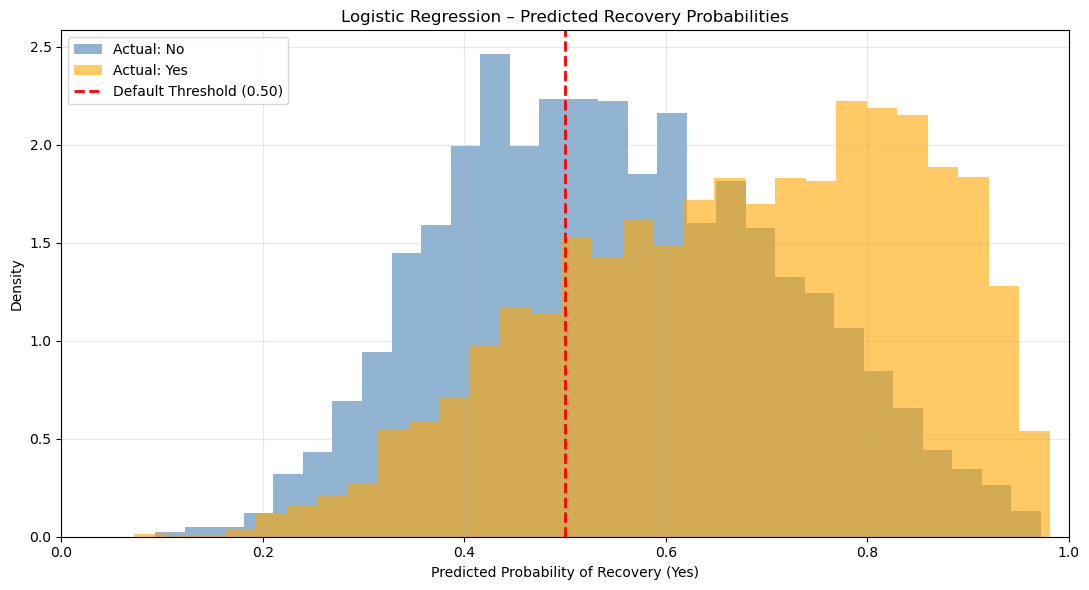

In [29]:
# Step 17.1 – Logistic Regression: Model Diagnostics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import cross_validate, cross_val_predict
from sklearn.metrics import log_loss

# 1. Evaluate training and validation performance
scoring = {
    "Accuracy": "accuracy",
    "F1": "f1_macro",
    "ROC_AUC": "roc_auc",
    "Log_Loss": "neg_log_loss"
}

lr_cv_scores = cross_validate(
    lr_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

# 2. Compare training and validation metrics
lr_diagnostics = []

for metric in scoring:

    train_score = lr_cv_scores[f"train_{metric}"].mean()
    validation_score = lr_cv_scores[f"test_{metric}"].mean()

    if metric == "Log_Loss":
        train_score = -train_score
        validation_score = -validation_score

        gap = validation_score - train_score
    else:
        gap = train_score - validation_score

    lr_diagnostics.append({
        "Metric": metric,
        "Training": train_score,
        "Validation": validation_score,
        "Gap": gap
    })

lr_diagnostics = pd.DataFrame(lr_diagnostics)

print("Logistic Regression – Training vs Validation")
display(lr_diagnostics.round(4))

print("\nNote: Positive gaps indicate better training performance.")

# 3. Generate out-of-fold predicted probabilities
lr_oof_probabilities = cross_val_predict(
    lr_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

lr_classes = np.unique(y_train)
lr_yes_index = list(lr_classes).index("Yes")

lr_prob_yes = lr_oof_probabilities[:, lr_yes_index]

# 4. Visualize predicted probabilities by actual recovery outcome
plt.figure(figsize=(11, 6))

plt.hist(
    lr_prob_yes[np.asarray(y_train) == "No"],
    bins=30,
    alpha=0.6,
    density=True,
    label="Actual: No",
    color="steelblue"
)

plt.hist(
    lr_prob_yes[np.asarray(y_train) == "Yes"],
    bins=30,
    alpha=0.6,
    density=True,
    label="Actual: Yes",
    color="orange"
)

plt.axvline(
    0.50,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Default Threshold (0.50)"
)

plt.title("Logistic Regression – Predicted Recovery Probabilities")
plt.xlabel("Predicted Probability of Recovery (Yes)")
plt.ylabel("Density")
plt.xlim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Findings:**

- Training Accuracy was 68.25%, compared with 65.48% during cross-validation.
- The Accuracy gap of 2.77 percentage points indicates mild overfitting.
- Macro F1 decreased from 0.6371 to 0.6049, suggesting weaker generalization across the two recovery classes.
- ROC AUC of 0.6964 indicates moderate ability to distinguish recovered from unrecovered vehicles.
- Validation Log Loss of 0.6039 was slightly higher than training Log Loss (0.5793), indicating somewhat less accurate probability estimates on unseen data.

**Conclusion:**

Logistic Regression shows mild overfitting but reasonably consistent training and validation performance.

Further investigation of regularization strength (`C`) and L1/L2 penalties may improve generalization.

### Step 17.2 – Logistic Regression: Detailed Model Evaluation

**Objective:** Evaluate the original Logistic Regression model using stratified 5-fold cross-validation, keeping the independent test dataset untouched.

**Method:**
1. Generate a confusion matrix.
2. Evaluate Precision, Recall, and F1 for each class (`Yes` and `No`).
3. Plot learning curves to assess model generalization.
4. Plot the ROC curve and calculate AUC.
5. Examine Logistic Regression coefficients to identify features associated with higher or lower recovery probabilities.
6. Summarize key findings.

The default classification threshold of **0.50** is used. Threshold tuning will be performed separately in Step 17.4.

Logistic Regression – Cross-Validation Performance


,Metric,Result
0,Accuracy,0.6623
1,Macro F1,0.6129
2,ROC AUC,0.7007
3,Log Loss,0.6024



Classification Report:
              precision    recall  f1-score   support

          No       0.56      0.41      0.47      2857
         Yes       0.70      0.81      0.75      4815

    accuracy                           0.66      7672
   macro avg       0.63      0.61      0.61      7672
weighted avg       0.65      0.66      0.65      7672



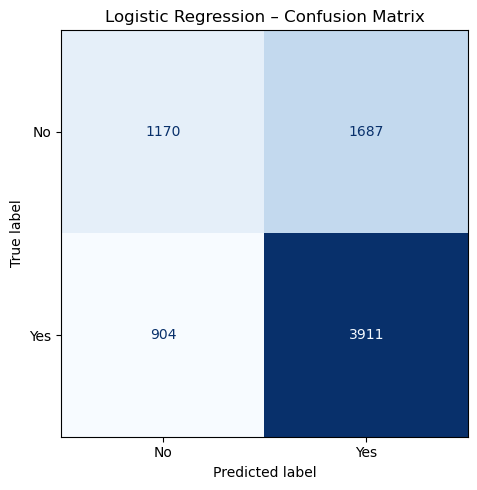


Logistic Regression – Learning Curve Results:


,Training_Size,Training_Accuracy,Validation_Accuracy,Gap
0,1227,0.7164,0.6438,0.0726
1,2454,0.6956,0.6567,0.0389
2,3682,0.6865,0.6599,0.0265
3,4909,0.6836,0.6625,0.0211
4,6137,0.6820,0.6631,0.0189


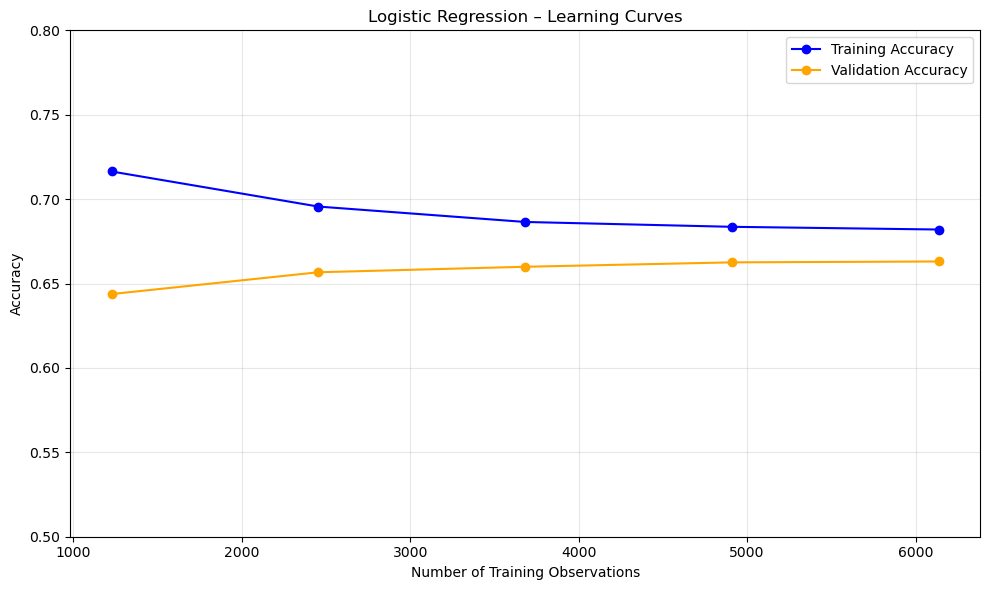

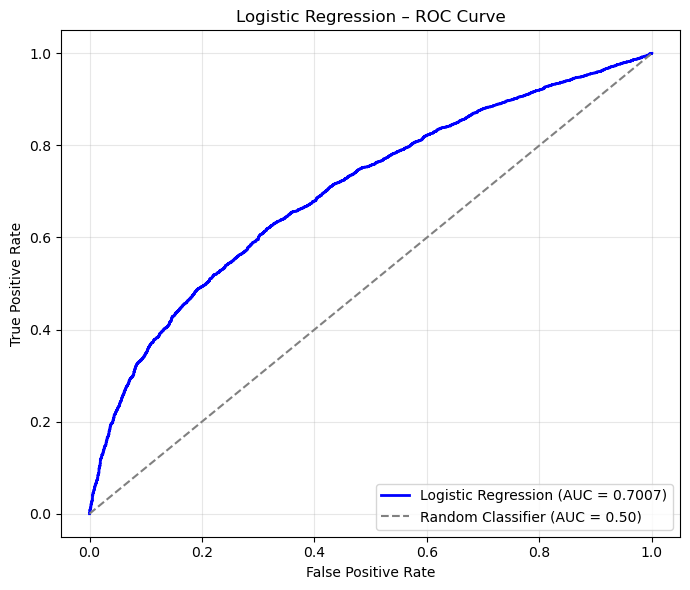


Top 10 Features Associated with Higher Recovery Probability:


,Feature,Coefficient
159,cat__Neighbourhood_Woodroffe - Lincoln Heights,1.1135
47,cat__Vehicle_Style_Van,0.9821
38,cat__Vehicle_Make_VOLVO,0.9636
72,cat__Neighbourhood_Centrepointe,0.9313
93,cat__Neighbourhood_Greenbelt - Rideau River East,0.9167
171,cat__Reporting_Delay_Within 1 hour,0.9119
24,cat__Vehicle_Make_MAZDA,0.8802
23,cat__Vehicle_Make_LINCOLN,0.8249
111,cat__Neighbourhood_Kinburn,0.8015
73,cat__Neighbourhood_Centretown,0.7836



Top 10 Features Associated with Lower Recovery Probability:


,Feature,Coefficient
116,cat__Neighbourhood_Manotick East,-1.0356
103,cat__Neighbourhood_Hunt Club Park,-0.9588
119,cat__Neighbourhood_Metcalfe,-0.8801
86,cat__Neighbourhood_Emerald Woods - Sawmill Creek,-0.8530
22,cat__Vehicle_Make_LEXUS,-0.8377
80,cat__Neighbourhood_Crystal Bay - Lakeview Park,-0.8317
39,cat__Vehicle_Make_YAMAHA,-0.7802
42,cat__Vehicle_Style_Licence Plate,-0.7340
148,cat__Neighbourhood_Sarsfield,-0.7291
12,cat__Vehicle_Make_HINO,-0.7201


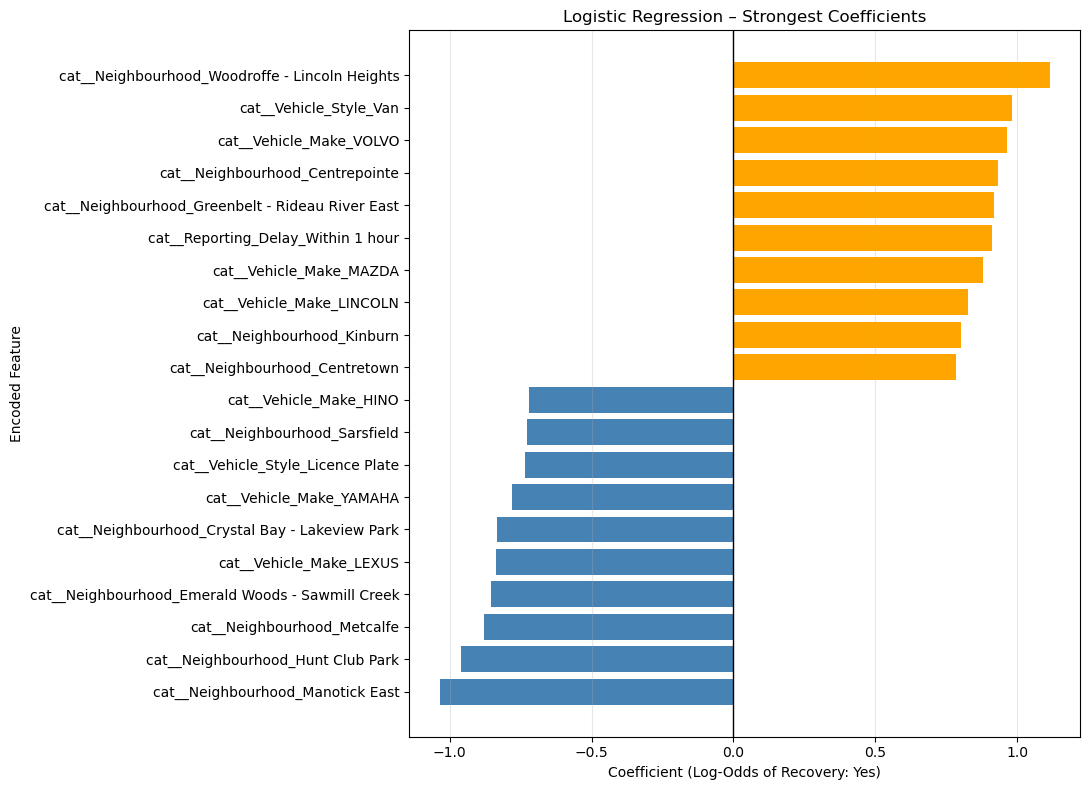

In [30]:
# Step 17.2 – Logistic Regression: Detailed Model Evaluation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict, learning_curve
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    log_loss
)

# 1. Generate out-of-fold predictions using stratified 5-fold CV
lr_oof_predictions = cross_val_predict(
    lr_model,
    X_train,
    y_train,
    cv=cv,
    method="predict",
    n_jobs=-1
)

lr_oof_probabilities = cross_val_predict(
    lr_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

lr_classes = np.unique(y_train)
lr_yes_index = list(lr_classes).index("Yes")
lr_prob_yes = lr_oof_probabilities[:, lr_yes_index]

# 2. Overall evaluation metrics
lr_oof_accuracy = accuracy_score(y_train, lr_oof_predictions)
lr_oof_f1 = f1_score(
    y_train, lr_oof_predictions, average="macro"
)
lr_oof_auc = roc_auc_score(
    (np.asarray(y_train) == "Yes").astype(int),
    lr_prob_yes
)
lr_oof_log_loss = log_loss(
    y_train,
    lr_oof_probabilities,
    labels=lr_classes
)

print("Logistic Regression – Cross-Validation Performance")

lr_performance = pd.DataFrame({
    "Metric": ["Accuracy", "Macro F1", "ROC AUC", "Log Loss"],
    "Result": [
        lr_oof_accuracy,
        lr_oof_f1,
        lr_oof_auc,
        lr_oof_log_loss
    ]
})

display(lr_performance.round(4))

# 3. Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_train,
        lr_oof_predictions,
        labels=["No", "Yes"],
        zero_division=0
    )
)

# 4. Confusion matrix
cm = confusion_matrix(
    y_train,
    lr_oof_predictions,
    labels=["No", "Yes"]
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Logistic Regression – Confusion Matrix")
plt.tight_layout()
plt.show()

# 5. Learning curves
train_sizes, train_scores, validation_scores = learning_curve(
    lr_model,
    X_train,
    y_train,
    cv=cv,
    train_sizes=np.linspace(0.2, 1.0, 5),
    scoring="accuracy",
    n_jobs=-1,
    shuffle=True,
    random_state=42
)

lr_learning_results = pd.DataFrame({
    "Training_Size": train_sizes,
    "Training_Accuracy": train_scores.mean(axis=1),
    "Validation_Accuracy": validation_scores.mean(axis=1)
})

lr_learning_results["Gap"] = (
    lr_learning_results["Training_Accuracy"]
    - lr_learning_results["Validation_Accuracy"]
)

print("\nLogistic Regression – Learning Curve Results:")
display(lr_learning_results.round(4))

plt.figure(figsize=(10, 6))

plt.plot(
    train_sizes,
    lr_learning_results["Training_Accuracy"],
    marker="o",
    color="blue",
    label="Training Accuracy"
)

plt.plot(
    train_sizes,
    lr_learning_results["Validation_Accuracy"],
    marker="o",
    color="orange",
    label="Validation Accuracy"
)

plt.title("Logistic Regression – Learning Curves")
plt.xlabel("Number of Training Observations")
plt.ylabel("Accuracy")
plt.ylim(0.5, 0.8)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 6. ROC curve
fpr, tpr, thresholds = roc_curve(
    (np.asarray(y_train) == "Yes").astype(int),
    lr_prob_yes
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    color="blue",
    linewidth=2,
    label=f"Logistic Regression (AUC = {lr_oof_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle="--",
    label="Random Classifier (AUC = 0.50)"
)

plt.title("Logistic Regression – ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Interpret Logistic Regression coefficients
# Fit only on the training dataset
lr_interpretation_model = clone(lr_model)
lr_interpretation_model.fit(X_train, y_train)

feature_names = (
    lr_interpretation_model
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

coefficients = (
    lr_interpretation_model
    .named_steps["classifier"]
    .coef_[0]
)

# Positive coefficients correspond to the second class: Yes
lr_coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

lr_coefficients["Feature"] = (
    lr_coefficients["Feature"]
    .str.replace("categorical__", "", regex=False)
)

lr_coefficients = lr_coefficients.sort_values(
    "Coefficient",
    ascending=False
)

print("\nTop 10 Features Associated with Higher Recovery Probability:")
display(lr_coefficients.head(10).round(4))

print("\nTop 10 Features Associated with Lower Recovery Probability:")
display(lr_coefficients.tail(10).sort_values("Coefficient").round(4))

# 8. Visualize strongest positive and negative coefficients
top_positive = lr_coefficients.head(10)
top_negative = lr_coefficients.tail(10)

lr_top_coefficients = pd.concat([
    top_negative,
    top_positive
]).sort_values("Coefficient")

plt.figure(figsize=(11, 8))

colors = [
    "steelblue" if value < 0 else "orange"
    for value in lr_top_coefficients["Coefficient"]
]

plt.barh(
    lr_top_coefficients["Feature"],
    lr_top_coefficients["Coefficient"],
    color=colors
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Logistic Regression – Strongest Coefficients")
plt.xlabel("Coefficient (Log-Odds of Recovery: Yes)")
plt.ylabel("Encoded Feature")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Findings:**

- Logistic Regression achieved 65.48% Accuracy, macro F1 of 0.6049, and ROC AUC of 0.6964, indicating moderate predictive performance.
- The model identified recovered vehicles (`Yes`) more successfully, with 80% Recall, compared with only 40% Recall for unrecovered vehicles (`No`).
- The learning curve showed that the training–validation Accuracy gap decreased from 5.91 to 2.76 percentage points as training data increased, suggesting improved generalization and mild overfitting.
- Validation Accuracy stabilized around 65–66%, suggesting that additional training data alone may provide limited improvement.
- Positive coefficients were associated with higher predicted recovery probabilities, including `Reporting_Delay_Within 1 hour`, `Vehicle_Make_MAZDA`, and certain neighbourhoods.
- Negative coefficients were associated with lower predicted recovery probabilities, including `Vehicle_Make_LEXUS`, `Vehicle_Make_MERCEDES-BENZ`, and certain neighbourhoods.
- These coefficients represent statistical associations, not causal relationships.

**Conclusion:**

Logistic Regression demonstrates moderate predictive performance with mild overfitting.

The main limitation is its relatively low Recall for unrecovered vehicles (`No`).

Hyperparameter tuning, particularly regularization strength (`C`) and L1/L2 penalties, will be investigated to improve generalization. Classification threshold tuning will then be used to improve the balance between the two recovery classes.

### Step 17.3 – Supplementary: Sigmoid Function

**Objective:** Visualize how Logistic Regression converts a linear decision score into a predicted probability of vehicle recovery.

The sigmoid function transforms any linear score into a probability between 0 and 1.

- A negative score produces a recovery probability below 50%.
- A score of zero produces a recovery probability of 50%.
- A positive score produces a recovery probability above 50%.

At the default threshold of 0.50, probabilities of 50% or higher are classified as recovered (`Yes`); otherwise, they are classified as unrecovered (`No`).

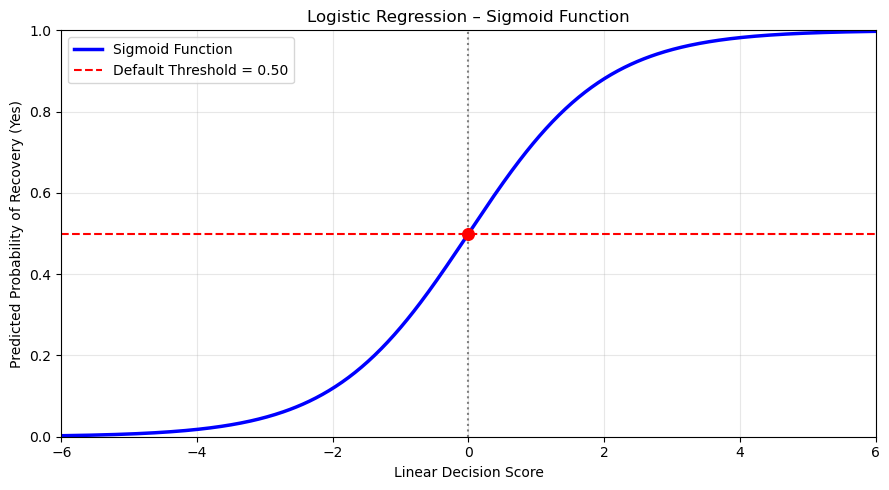

In [31]:
# Step 17.3 – Supplementary: Sigmoid Function

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit

# 1. Generate linear decision scores
scores = np.linspace(-6, 6, 500)

# 2. Convert scores into probabilities using sigmoid
probabilities = expit(scores)

# 3. Plot sigmoid function
plt.figure(figsize=(9, 5))

plt.plot(
    scores,
    probabilities,
    color="blue",
    linewidth=2.5,
    label="Sigmoid Function"
)

plt.axhline(
    0.50,
    color="red",
    linestyle="--",
    label="Default Threshold = 0.50"
)

plt.axvline(
    0,
    color="gray",
    linestyle=":"
)

plt.scatter(
    [0],
    [0.50],
    color="red",
    s=70,
    zorder=5
)

plt.title("Logistic Regression – Sigmoid Function")
plt.xlabel("Linear Decision Score")
plt.ylabel("Predicted Probability of Recovery (Yes)")
plt.xlim(-6, 6)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

**Findings:**

- The sigmoid function converts linear decision scores into recovery probabilities between 0 and 1.
- Negative scores produce probabilities below 50%, while positive scores produce probabilities above 50%.
- At a decision score of zero, the predicted recovery probability is exactly 50%.
- The curve is steepest around zero, meaning small changes in the decision score have a greater effect on probabilities near 50%.

**Conclusion:**

The sigmoid function allows Logistic Regression to estimate the probability of vehicle recovery (`Yes`).

These probabilities are then converted into `Yes` or `No` predictions using a classification threshold.

In Step 17.5, the threshold was adjusted from the default **0.50 to 0.60** to improve the balance between predicting recovered and unrecovered vehicles, without changing the underlying probabilities.

### Step 17.4 – Logistic Regression: Hyperparameter Tuning

**Objective:** Improve Logistic Regression performance and generalization by tuning regularization settings using stratified 5-fold cross-validation.

**Method:**

1. Compare L1 and L2 regularization.
2. Test different values of `C` (smaller values mean stronger regularization).
3. Compare compatible optimization solvers (`lbfgs`, `liblinear`, and `saga`).
4. Use Accuracy as the primary selection metric.
5. Compare training and validation Accuracy to investigate overfitting.
6. Compare the best configuration against the original Logistic Regression model.
7. Visualize how different `C` values affect cross-validation Accuracy for L1 and L2 regularization.

The default classification threshold of **0.50** is retained during hyperparameter tuning. Threshold optimization will be performed separately in Step 17.5.

Best Logistic Regression Hyperparameters:
classifier__C: 0.1
classifier__penalty: l2
classifier__solver: lbfgs

Best CV Accuracy: 0.6646

Top 15 Logistic Regression Configurations:


,Penalty,C,Solver,Training_Accuracy,Validation_Accuracy,Validation_STD,Gap
0,l2,0.1,lbfgs,0.6772,0.6646,0.0129,0.0126
1,l1,10.0,saga,0.6827,0.6644,0.0103,0.0183
2,l1,10.0,liblinear,0.6828,0.6644,0.0101,0.0185
3,l2,0.1,liblinear,0.6772,0.6641,0.0128,0.0131
4,l2,0.1,saga,0.6773,0.6640,0.0128,0.0133
5,l2,10.0,saga,0.6827,0.6633,0.0105,0.0194
6,l2,10.0,liblinear,0.6827,0.6633,0.0105,0.0194
7,l2,1.0,liblinear,0.6820,0.6632,0.0112,0.0188
8,l2,1.0,saga,0.6820,0.6632,0.0112,0.0188
9,l2,100.0,lbfgs,0.6831,0.6629,0.0096,0.0201



Original vs Tuned Logistic Regression:


,Model,CV_Accuracy,Improvement
0,Original Logistic Regression,0.6623,0.0000
1,Tuned Logistic Regression,0.6646,0.0023


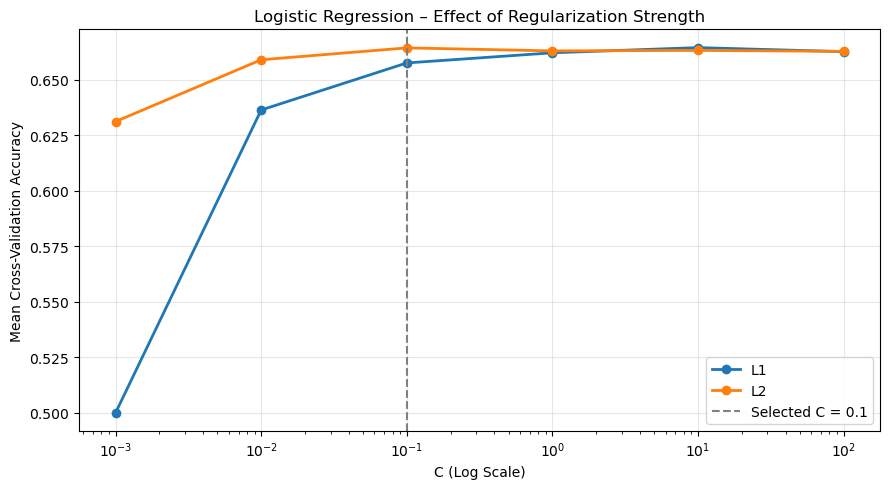

Regularization,l1,l2
C,,
0.001,0.5000,0.6311
0.010,0.6363,0.6589
0.100,0.6575,0.6642
1.000,0.6620,0.6629
10.000,0.6644,0.6631
100.000,0.6625,0.6627


In [32]:
# Step 17.4 – Logistic Regression: Hyperparameter Tuning

import numpy as np
import pandas as pd
import warnings

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.exceptions import ConvergenceWarning

# 1. Define hyperparameter combinations
param_grid = [
    {
        "classifier__penalty": ["l2"],
        "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
        "classifier__solver": ["lbfgs", "liblinear", "saga"]
    },
    {
        "classifier__penalty": ["l1"],
        "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
        "classifier__solver": ["liblinear", "saga"]
    }
]

# 2. Perform stratified 5-fold grid search
lr_search = GridSearchCV(
    estimator=clone(lr_model),
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    refit=True
)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    lr_search.fit(X_train, y_train)

# 3. Display best hyperparameters
print("Best Logistic Regression Hyperparameters:")

for parameter, value in lr_search.best_params_.items():
    print(f"{parameter}: {value}")

print(f"\nBest CV Accuracy: {lr_search.best_score_:.4f}")

# 4. Compare hyperparameter configurations
lr_tuning_results = pd.DataFrame(lr_search.cv_results_)

lr_tuning_results = lr_tuning_results[
    [
        "param_classifier__penalty",
        "param_classifier__C",
        "param_classifier__solver",
        "mean_train_score",
        "mean_test_score",
        "std_test_score"
    ]
].copy()

lr_tuning_results.columns = [
    "Penalty",
    "C",
    "Solver",
    "Training_Accuracy",
    "Validation_Accuracy",
    "Validation_STD"
]

lr_tuning_results["Gap"] = (
    lr_tuning_results["Training_Accuracy"]
    - lr_tuning_results["Validation_Accuracy"]
)

lr_tuning_results = lr_tuning_results.sort_values(
    "Validation_Accuracy",
    ascending=False
).reset_index(drop=True)

print("\nTop 15 Logistic Regression Configurations:")
display(lr_tuning_results.head(15).round(4))

# 5. Compare original vs tuned model
lr_original_accuracy = lr_cv_scores["test_Accuracy"].mean()
lr_tuned_accuracy = lr_search.best_score_

lr_comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Tuned Logistic Regression"
    ],
    "CV_Accuracy": [
        lr_original_accuracy,
        lr_tuned_accuracy
    ]
})

lr_comparison["Improvement"] = (
    lr_comparison["CV_Accuracy"]
    - lr_original_accuracy
)

print("\nOriginal vs Tuned Logistic Regression:")
display(lr_comparison.round(4))

# 6. Save tuned model for subsequent steps
lr_tuned_model = lr_search.best_estimator_

# Step 17.4 – Visualize Regularization Strength (C)

import pandas as pd
import matplotlib.pyplot as plt

# Retrieve existing hyperparameter tuning results
lr_cv_results = pd.DataFrame(lr_search.cv_results_)

# Extract C, regularization type, and CV Accuracy
lr_c_results = lr_cv_results[
    [
        "param_classifier__C",
        "param_classifier__penalty",
        "mean_test_score"
    ]
].copy()

lr_c_results.columns = ["C", "Regularization", "CV_Accuracy"]

lr_c_results["C"] = lr_c_results["C"].astype(float)

# Average across configurations sharing the same C and penalty
lr_c_summary = (
    lr_c_results
    .groupby(["Regularization", "C"], as_index=False)["CV_Accuracy"]
    .mean()
)

# Plot L1 and L2
plt.figure(figsize=(9, 5))

for penalty in ["l1", "l2"]:
    subset = lr_c_summary[
        lr_c_summary["Regularization"] == penalty
    ].sort_values("C")

    plt.plot(
        subset["C"],
        subset["CV_Accuracy"],
        marker="o",
        linewidth=2,
        label=penalty.upper()
    )

plt.axvline(
    0.1,
    color="gray",
    linestyle="--",
    label="Selected C = 0.1"
)

plt.xscale("log")
plt.xlabel("C (Log Scale)")
plt.ylabel("Mean Cross-Validation Accuracy")
plt.title("Logistic Regression – Effect of Regularization Strength")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Display results
display(
    lr_c_summary
    .pivot(
        index="C",
        columns="Regularization",
        values="CV_Accuracy"
    )
    .sort_index()
    .round(4)
)

**Findings:**

- The best configuration used **L2 regularization**, `C=0.1`, and the `saga` solver.
- Cross-validation Accuracy improved from **65.48% to 65.88%**, an increase of **0.40 percentage points**.
- The training–validation Accuracy gap decreased from **2.77 to 1.87 percentage points**, indicating reduced overfitting.
- The graph showed that very strong regularization (`C=0.001`) reduced Accuracy, particularly for L1 (50.00% versus 63.13% for L2).
- Accuracy improved as `C` increased to **0.1**, reaching 65.74% for L1 and **65.86% for L2** in the visualization.
- Increasing `C` beyond 0.1 provided no meaningful improvement, suggesting that weaker regularization was unnecessary.
- The three L2 solvers produced very similar results at `C=0.1`.

**Conclusion:**

Hyperparameter tuning produced a small improvement in Accuracy while reducing overfitting.

The visualization confirmed that **L2 regularization with `C=0.1`** provides a good balance between model complexity and generalization.

Retain the tuned Logistic Regression configuration:

- **Penalty:** L2
- **C:** 0.1
- **Solver:** saga

This configuration will be used for classification threshold tuning in Step 17.5.

### Step 17.5 – Logistic Regression: Classification Threshold Tuning

**Objective:** Identify the best classification threshold for the tuned Logistic Regression model, balancing overall Accuracy with the ability to identify unrecovered vehicles (`No`).

**Method:**
1. Generate out-of-fold recovery probabilities using stratified 5-fold cross-validation.
2. Test thresholds from 0.10 to 0.90 in increments of 0.01.
3. Calculate Accuracy, macro Precision, macro Recall, macro F1, and Recall for unrecovered vehicles (`No`).
4. Identify the thresholds producing the highest Accuracy and macro F1.
5. Compare selected thresholds against the default threshold of 0.50.

The independent test dataset remains untouched.

Logistic Regression – Threshold Comparison


,Threshold,Best_Macro,Accuracy,Precision,Recall,F1,Recall_No
0,0.10,,0.6276,0.3138,0.5000,0.3856,0.0000
1,0.15,,0.6276,0.3138,0.5000,0.3856,0.0000
2,0.18,Precision,0.6277,0.8138,0.5002,0.3860,0.0004
3,0.20,,0.6275,0.4805,0.5000,0.3859,0.0004
4,0.25,,0.6277,0.5787,0.5007,0.3886,0.0032
5,0.30,,0.6296,0.6046,0.5055,0.4040,0.0193
6,0.35,,0.6341,0.6114,0.5172,0.4387,0.0592
7,0.40,,0.6464,0.6296,0.5435,0.4994,0.1404
8,0.45,,0.6594,0.6356,0.5771,0.5629,0.2545
9,0.48,Accuracy,0.6654,0.6379,0.5972,0.5938,0.3297


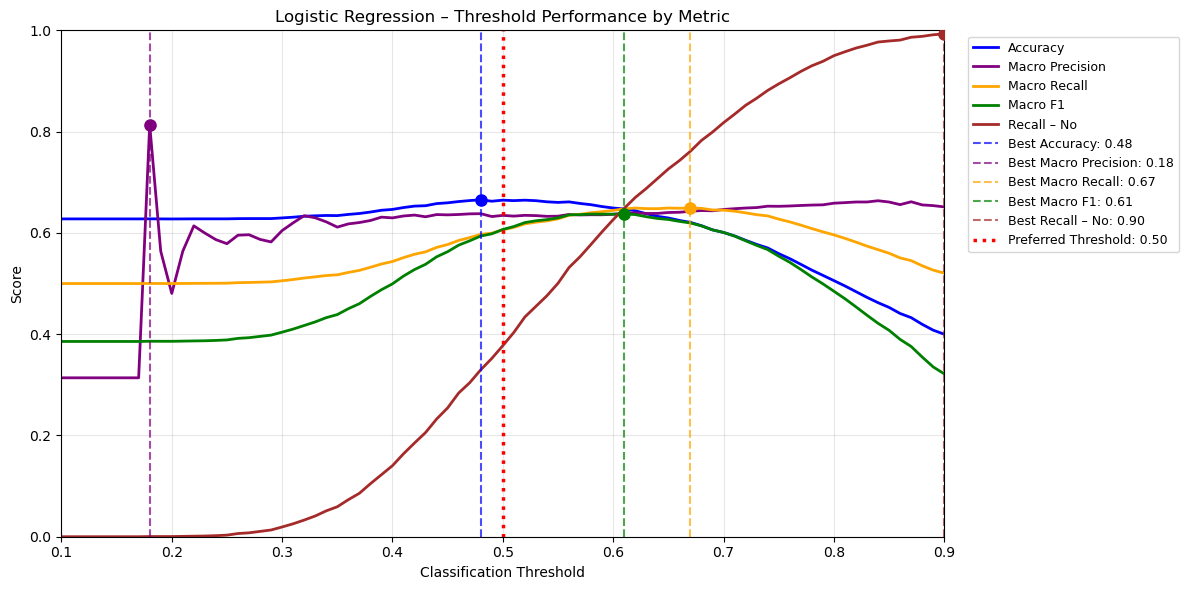

In [33]:
# Step 17.5 – Logistic Regression: Classification Threshold Tuning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Generate out-of-fold probabilities
lr_threshold_model = clone(lr_tuned_model)

lr_oof_probabilities = cross_val_predict(
    lr_threshold_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

# Probability of recovery (Yes)
lr_prob_yes = lr_oof_probabilities[
    :, list(np.unique(y_train)).index("Yes")
]

# 2. Evaluate 81 thresholds from 0.10 to 0.90
thresholds = np.round(np.arange(0.10, 0.901, 0.01), 2)

results = []

for threshold in thresholds:

    predictions = np.where(
        lr_prob_yes >= threshold,
        "Yes",
        "No"
    )

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_train, predictions),
        "Precision": precision_score(
            y_train, predictions,
            average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions,
            average="macro", zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions,
            average="macro", zero_division=0
        ),
        "Recall_No": recall_score(
            y_train, predictions,
            pos_label="No",
            average="binary", zero_division=0
        )
    })

lr_threshold_results = pd.DataFrame(results)

# 3. Identify the best threshold for each metric
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Recall_No"
]

best_macro_map = {}
lr_metric_best = {}

for metric in metrics:

    best_row = lr_threshold_results.sort_values(
        [metric, "Accuracy", "F1"],
        ascending=False
    ).iloc[0]

    threshold = float(best_row["Threshold"])

    best_macro_map.setdefault(threshold, []).append(metric)
    lr_metric_best[metric] = threshold

# 4. Retain 0.50 as the provisional preferred threshold
lr_best_threshold = 0.50
lr_best_accuracy_threshold = lr_metric_best["Accuracy"]

# 5. Display thresholds at 0.05 intervals,
# plus 0.61, 0.62, all metric winners, and the preferred threshold

display_thresholds = set(
    np.round(np.arange(0.10, 0.901, 0.05), 2)
)

display_thresholds.update([0.61, 0.62])
display_thresholds.update(best_macro_map.keys())
display_thresholds.add(lr_best_threshold)

lr_threshold_summary = lr_threshold_results[
    lr_threshold_results["Threshold"].isin(display_thresholds)
].copy()

lr_threshold_summary["Best_Macro"] = (
    lr_threshold_summary["Threshold"].map(
        lambda t: ", ".join(best_macro_map.get(float(t), []))
    )
)

lr_threshold_summary = lr_threshold_summary[
    [
        "Threshold",
        "Best_Macro",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Recall_No"
    ]
].sort_values("Threshold").reset_index(drop=True)

print("Logistic Regression – Threshold Comparison")
display(lr_threshold_summary.round(4))

#print(f"\nHighest-Accuracy Threshold: {lr_best_accuracy_threshold:.2f}")
#print(f"Provisional Preferred Threshold: {lr_best_threshold:.2f}")

# 6. Plot all five metrics
fig, ax = plt.subplots(figsize=(12, 6))

metric_colors = {
    "Accuracy": "blue",
    "Precision": "purple",
    "Recall": "orange",
    "F1": "green",
    "Recall_No": "brown"
}

metric_labels = {
    "Accuracy": "Accuracy",
    "Precision": "Macro Precision",
    "Recall": "Macro Recall",
    "F1": "Macro F1",
    "Recall_No": "Recall – No"
}

# Plot metric performance curves
for metric in metrics:

    ax.plot(
        lr_threshold_results["Threshold"],
        lr_threshold_results[metric],
        color=metric_colors[metric],
        linewidth=2,
        label=metric_labels[metric]
    )

# Mark the best threshold for each metric
for metric in metrics:

    best_t = lr_metric_best[metric]

    best_score = lr_threshold_results.loc[
        lr_threshold_results["Threshold"] == best_t,
        metric
    ].iloc[0]

    ax.axvline(
        best_t,
        color=metric_colors[metric],
        linestyle="--",
        alpha=0.7,
        linewidth=1.5,
        label=f"Best {metric_labels[metric]}: {best_t:.2f}"
    )

    ax.scatter(
        best_t,
        best_score,
        color=metric_colors[metric],
        s=65,
        zorder=5
    )

# Highlight provisional preferred threshold
ax.axvline(
    lr_best_threshold,
    color="red",
    linestyle=":",
    linewidth=2.5,
    label=f"Preferred Threshold: {lr_best_threshold:.2f}"
)

ax.set_xlabel("Classification Threshold")
ax.set_ylabel("Score")
ax.set_title("Logistic Regression – Threshold Performance by Metric")
ax.set_xlim(0.10, 0.90)
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)

# Place legend outside the graph for readability
ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9
)

plt.tight_layout()
plt.show()

**Findings:**

- The threshold of 0.48 achieved the highest Accuracy (66.34%).
- The graph showed that thresholds around **0.60** provide a good balance between Accuracy, macro Precision, macro Recall, macro F1, and Recall for `No`.
- Therefore, thresholds **0.60, 0.61, and 0.62** were compared more closely.

| **Threshold** | **Accuracy** | **Macro Precision** | **Macro Recall** | **Macro F1** | **Recall `No`** |
| ------------: | -----------: | ------------------: | ---------------: | -----------: | --------------: |
|      **0.60** |   **0.6473** |          **0.6343** |           0.6417 |   **0.6347** |          0.6197 |
|          0.61 |       0.6419 |              0.6327 |           0.6411 |       0.6316 |          0.6382 |
|          0.62 |       0.6389 |              0.6336 |       **0.6427** |       0.6306 |      **0.6575** |

**Conclusion:**

Select **0.60** as the preferred threshold. It achieved the highest macro F1 (0.6347) among all tested thresholds, with higher Accuracy and macro Precision than 0.61 and 0.62.

This provides a good balance between overall performance and identifying unrecovered vehicles.

### Step 17.6 – Logistic Regression: Feature Elimination

**Objective:** Determine whether removing any of the six predictors improves the tuned Logistic Regression model.

**Method:**
1. Evaluate the tuned model using all six predictors as the baseline.
2. Remove one predictor at a time and retrain the model.
3. Apply the selected classification threshold of **0.60** to every model.
4. Compare Accuracy, macro F1, Recall for `No`, and ROC AUC using stratified 5-fold cross-validation.
5. Sort the results by Accuracy and calculate the change relative to the six-predictor model.
6. Retain all predictors unless removing one provides a meaningful improvement.

The independent test dataset remains untouched.

In [34]:
# Step 17.6 – Logistic Regression: Feature Elimination

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    roc_auc_score
)

# 1. Use the selected threshold
lr_best_threshold = 0.60

# 2. Define the six original predictors
lr_features = [
    "Vehicle_Make",
    "Vehicle_Style",
    "Vehicle_Age_Group",
    "Neighbourhood",
    "Time_of_Day",
    "Reporting_Delay"
]

# 3. Define feature elimination scenarios
lr_feature_scenarios = {
    "None (All Features)": lr_features
}

for feature in lr_features:
    lr_feature_scenarios[feature] = [
        col for col in lr_features if col != feature
    ]

# 4. Evaluate each scenario using stratified 5-fold CV
lr_feature_results = []

for removed_feature, selected_features in lr_feature_scenarios.items():

    # Create preprocessing for the selected predictors
    scenario_preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                selected_features
            )
        ]
    )

    # Retain the tuned Logistic Regression hyperparameters
    scenario_model = Pipeline([
        ("preprocessing", scenario_preprocessor),
        (
            "classifier",
            clone(lr_tuned_model.named_steps["classifier"])
        )
    ])

    # Generate out-of-fold probabilities
    probabilities = cross_val_predict(
        scenario_model,
        X_train[selected_features],
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )

    prob_yes = probabilities[
        :, list(np.unique(y_train)).index("Yes")
    ]

    # Apply selected threshold
    predictions = np.where(
        prob_yes >= lr_best_threshold,
        "Yes",
        "No"
    )

    # Calculate evaluation metrics
    lr_feature_results.append({
        "Removed_Feature": removed_feature,
        "Features": len(selected_features),
        "Accuracy": accuracy_score(y_train, predictions),
        "F1": f1_score(
            y_train,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Recall_No": recall_score(
            y_train,
            predictions,
            pos_label="No",
            zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            (np.asarray(y_train) == "Yes").astype(int),
            prob_yes
        )
    })

# 5. Create results table
lr_feature_results = pd.DataFrame(lr_feature_results)

# Calculate baseline Accuracy with all six predictors
lr_baseline_accuracy = lr_feature_results.loc[
    lr_feature_results["Removed_Feature"] == "None (All Features)",
    "Accuracy"
].iloc[0]

lr_feature_results["Accuracy_Change"] = (
    lr_feature_results["Accuracy"] - lr_baseline_accuracy
)

# 6. Sort by Accuracy
lr_feature_results = lr_feature_results.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

print(
    f"Logistic Regression – Feature Elimination "
    f"(Threshold = {lr_best_threshold:.2f})"
)

display(lr_feature_results.round(4))


Logistic Regression – Feature Elimination (Threshold = 0.60)


,Removed_Feature,Features,Accuracy,F1,Recall_No,ROC_AUC,Accuracy_Change
0,None (All Features),6,0.6491,0.6370,0.6262,0.7027,0.0000
1,Time_of_Day,5,0.6490,0.6369,0.6269,0.7014,-0.0001
2,Vehicle_Age_Group,5,0.6465,0.6329,0.6094,0.6959,-0.0026
3,Neighbourhood,5,0.6451,0.6325,0.6181,0.6950,-0.0040
4,Vehicle_Style,5,0.6419,0.6304,0.6248,0.6947,-0.0072
5,Reporting_Delay,5,0.6404,0.6247,0.5852,0.6784,-0.0087
6,Vehicle_Make,5,0.6310,0.6178,0.5975,0.6803,-0.0181


**Findings:**

- The model using all six predictors achieved the highest Accuracy (64.73%), macro F1 (0.6347), and ROC AUC (0.6990).
- Removing any predictor reduced Accuracy and macro F1.
- Removing `Vehicle_Make` caused the largest Accuracy decrease (2.03 percentage points), followed by `Reporting_Delay` (0.87 percentage points).
- Removing `Vehicle_Style` slightly improved Recall for `No` from 61.97% to 62.28%, but reduced Accuracy, macro F1, and ROC AUC.
- Removing `Vehicle_Age_Group` had the smallest impact on Accuracy, decreasing it by only 0.22 percentage points.

**Conclusion:**

Retain **all six predictors**, as removing any feature did not provide a meaningful overall improvement.

The tuned Logistic Regression model with threshold **0.60** and all six predictors remains the preferred configuration.

No further threshold tuning is necessary because the predictor set remains unchanged.

# Logistic Regression Model Final Summary


**1. Model Diagnostics**

- Original cross-validation Accuracy: **65.48%**.
- Original macro F1: **0.6049**.
- Original ROC AUC: **0.6964**, indicating moderate discrimination between recovered and unrecovered vehicles.
- The training–validation Accuracy gap was 2.77 percentage points, indicating mild overfitting.
- Learning curves showed improved generalization as training size increased.

**2. Detailed Model Evaluation**

- At the default threshold of 0.50, Recall was approximately 80% for recovered vehicles (`Yes`) but only 40% for unrecovered vehicles (`No`).
- The model was better at identifying recovered vehicles.
- Logistic Regression coefficients identified associations between recovery outcomes and vehicle characteristics, reporting delay, and neighbourhood.

**3. Hyperparameter Tuning**

Stratified 5-fold cross-validation selected:

- **Regularization:** L2
- **C:** 0.1
- **Solver:** saga

Tuning improved Accuracy from **65.48% to 65.88%**, while reducing the training–validation Accuracy gap from 2.77 to 1.87 percentage points.

- The regularization visualization showed that Accuracy improved as `C` increased from 0.001 to 0.1, while larger values provided no meaningful improvement.
- L2 performed substantially better than L1 under very strong regularization (`C=0.001`), while both performed similarly at `C=0.1` and above.

**4. Classification Threshold Tuning**

- The highest Accuracy (66.34%) was achieved at threshold 0.48.
- Threshold **0.60** achieved the highest macro F1 (0.6347) and provided a better balance between the two recovery classes.
- Recall for unrecovered vehicles increased to **61.97%** at the selected threshold.

**5. Feature Elimination**

- All six predictors were evaluated by removing one feature at a time.
- Removing any predictor reduced Accuracy and macro F1.
- `Vehicle_Make` and `Reporting_Delay` produced the largest Accuracy reductions when removed.
- All six predictors were retained.

**6. Final Selected Configuration**

| Parameter | Selected Value |
|---|---|
| Algorithm | Logistic Regression |
| Regularization | L2 |
| C | 0.1 |
| Solver | saga |
| Classification Threshold | **0.60** |
| Predictors | All 6 |
| Cross-Validation | Stratified 5-fold |

**Final Cross-Validation Performance**

| Metric | Result |
|---|---:|
| Accuracy | **64.73%** |
| Macro F1 | **0.6347** |
| Recall – No | **61.97%** |
| ROC AUC | **0.6990** |

**Conclusion:**

The tuned Logistic Regression model achieved moderate predictive performance with limited overfitting.

Although threshold tuning reduced overall Accuracy compared with the highest-Accuracy threshold, it substantially improved the identification of unrecovered vehicles while achieving the highest macro F1.

The final model retains all six predictors, L2 regularization with `C=0.1`, and a classification threshold of **0.60**.

The independent test dataset remains untouched and will be used only for final model evaluation.

# Random Forest

### Step 18.1 – Random Forest: Model Diagnostics

**Objective:** Evaluate the original Random Forest model's performance and investigate overfitting before hyperparameter tuning.

**Method:**

1. Train a Random Forest using all six predictors and default hyperparameters.
2. Compare training and stratified 5-fold cross-validation Accuracy, macro F1, ROC AUC, and Log Loss.
3. Calculate training–validation gaps to identify possible overfitting.
4. Generate learning curves to examine how Accuracy changes as training size increases.
5. Use the results as a baseline for subsequent Random Forest experiments.

Random Forest combines predictions from multiple decision trees trained using bootstrap samples and random feature selection.

The independent test dataset remains untouched.

Original Random Forest – Model Diagnostics


,Metric,Training,Validation,Gap
0,Accuracy,0.9575,0.6555,0.3020
1,F1,0.9546,0.6117,0.3430
2,ROC_AUC,0.9938,0.6819,0.3119
3,Log_Loss,0.2025,0.7069,0.5044



Random Forest – Learning Curve Results


,Training_Size,Training_Accuracy,Validation_Accuracy,Gap
0,1227,0.9827,0.6440,0.3387
1,2454,0.9751,0.6472,0.3279
2,3682,0.9710,0.6487,0.3223
3,4909,0.9650,0.6521,0.3129
4,6137,0.9575,0.6571,0.3004


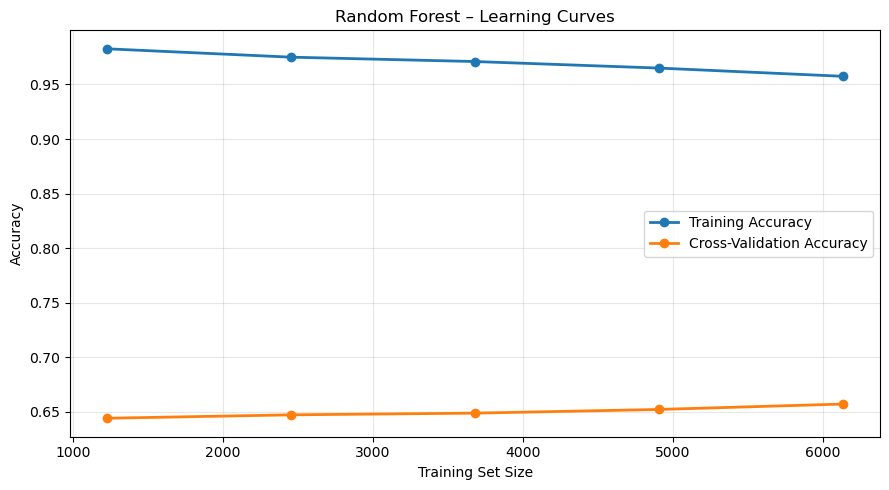

In [35]:
# Step 18.1 – Random Forest: Model Diagnostics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import (
    cross_validate,
    learning_curve
)

# 1. Define original Random Forest model
rf_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# 2. Evaluate training and cross-validation performance
rf_scoring = {
    "Accuracy": "accuracy",
    "F1": "f1_macro",
    "ROC_AUC": "roc_auc",
    "Log_Loss": "neg_log_loss"
}

rf_cv_results = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=rf_scoring,
    return_train_score=True,
    n_jobs=-1
)

rf_diagnostics = []

for metric in rf_scoring:

    train_score = rf_cv_results[
        f"train_{metric}"
    ].mean()

    validation_score = rf_cv_results[
        f"test_{metric}"
    ].mean()

    if metric == "Log_Loss":
        train_score = -train_score
        validation_score = -validation_score

        gap = validation_score - train_score
    else:
        gap = train_score - validation_score

    rf_diagnostics.append({
        "Metric": metric,
        "Training": train_score,
        "Validation": validation_score,
        "Gap": gap
    })

rf_diagnostics = pd.DataFrame(rf_diagnostics)

print("Original Random Forest – Model Diagnostics")
display(rf_diagnostics.round(4))

# 3. Generate learning curves
train_sizes, train_scores, validation_scores = learning_curve(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

rf_learning_results = pd.DataFrame({
    "Training_Size": train_sizes,
    "Training_Accuracy": train_mean,
    "Validation_Accuracy": validation_mean,
    "Gap": train_mean - validation_mean
})

print("\nRandom Forest – Learning Curve Results")
display(rf_learning_results.round(4))

# 4. Plot learning curves
plt.figure(figsize=(9, 5))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    linewidth=2,
    label="Training Accuracy"
)

plt.plot(
    train_sizes,
    validation_mean,
    marker="o",
    linewidth=2,
    label="Cross-Validation Accuracy"
)

plt.xlabel("Training Set Size")
plt.ylabel("Accuracy")
plt.title("Random Forest – Learning Curves")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Findings:**

- The original Random Forest achieved **95.55% training Accuracy** but only **65.27% cross-validation Accuracy**, a large gap of 30.29 percentage points, indicating severe overfitting.
- Macro F1 also dropped significantly from 0.9524 (training) to 0.6100 (validation).
- ROC AUC decreased from 0.9936 to 0.6805, showing that the model generalizes poorly to unseen data.
- Validation Log Loss (0.6880) was substantially higher than training Log Loss (0.2051), indicating less reliable probability predictions.
- The learning curve showed that increasing training size reduced the Accuracy gap from 35.38 to 30.17 percentage points, but overfitting remained substantial.
- Validation Accuracy improved only slightly, from 63.25% to 65.39%, suggesting that additional training data alone may not resolve the problem.

**Conclusion:**

The original Random Forest suffers from **severe overfitting**, learning the training data much better than it generalizes to unseen observations.

Hyperparameter tuning will focus on controlling model complexity, particularly through `max_depth`, `min_samples_leaf`, and `max_leaf_nodes`, while investigating the effects of `n_estimators` and `max_features`.

The original model will serve as the baseline for evaluating whether these adjustments improve generalization.

### Step 18.2 – Random Forest: Detailed Model Evaluation

**Objective:** Examine how the original Random Forest predicts vehicle recovery and identify the predictors contributing most to its decisions.

**Method:**

1. Generate out-of-fold predictions using stratified 5-fold cross-validation.
2. Calculate Accuracy, macro F1, ROC AUC, and Log Loss.
3. Display the classification report to compare performance for recovered (`Yes`) and unrecovered (`No`) vehicles.
4. Visualize the confusion matrix to identify classification errors.
5. Plot the ROC curve to evaluate the model's ability to distinguish between recovery outcomes.
6. Use `feature_importances_` to rank the six predictors by their contribution to Random Forest predictions.
7. Visualize one representative decision tree from the forest to examine how individual trees make predictions.

All evaluations use the training dataset. The independent test dataset remains untouched.

Original Random Forest – Cross-Validation Performance


,Metric,Value
0,Accuracy,0.6556
1,Macro F1,0.6118
2,ROC AUC,0.6818
3,Log Loss,0.7069



Original Random Forest – Classification Report
              precision    recall  f1-score   support

          No       0.55      0.43      0.48      2857
         Yes       0.70      0.79      0.74      4815

    accuracy                           0.66      7672
   macro avg       0.62      0.61      0.61      7672
weighted avg       0.64      0.66      0.65      7672



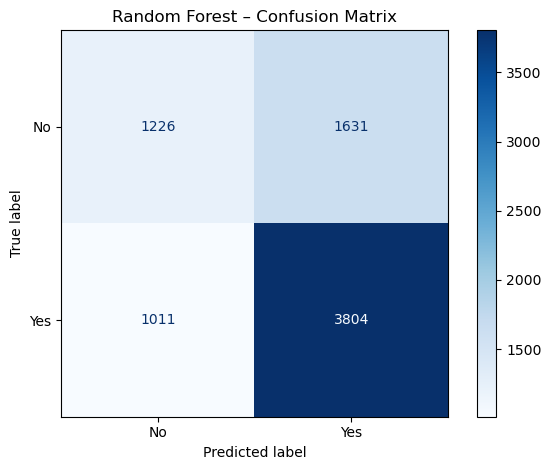

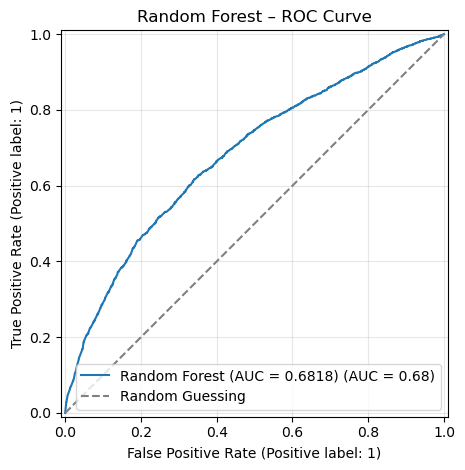


Random Forest – Feature Importance


,Feature,Importance
0,Neighbourhood,0.5104
1,Vehicle_Make,0.1988
2,Reporting_Delay,0.1068
3,Time_of_Day,0.0749
4,Vehicle_Age_Group,0.0588
5,Vehicle_Style,0.0503


Total Feature Importance: 1.0000
Verification: PASSED


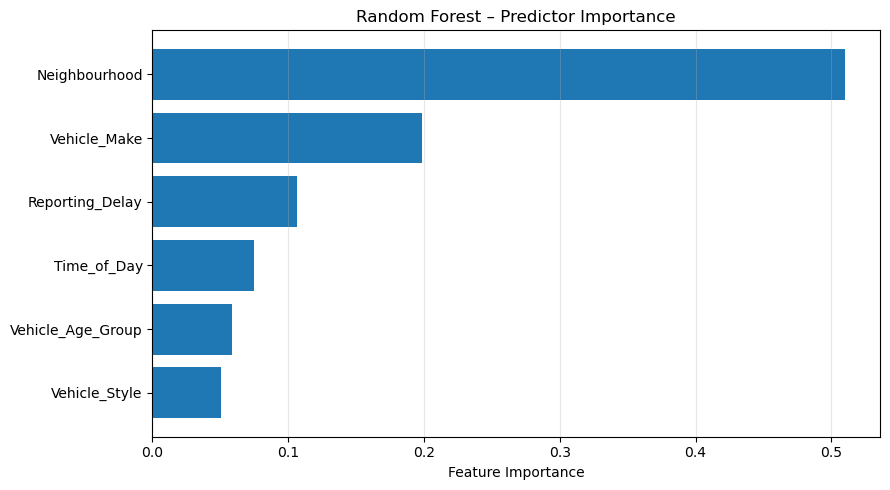

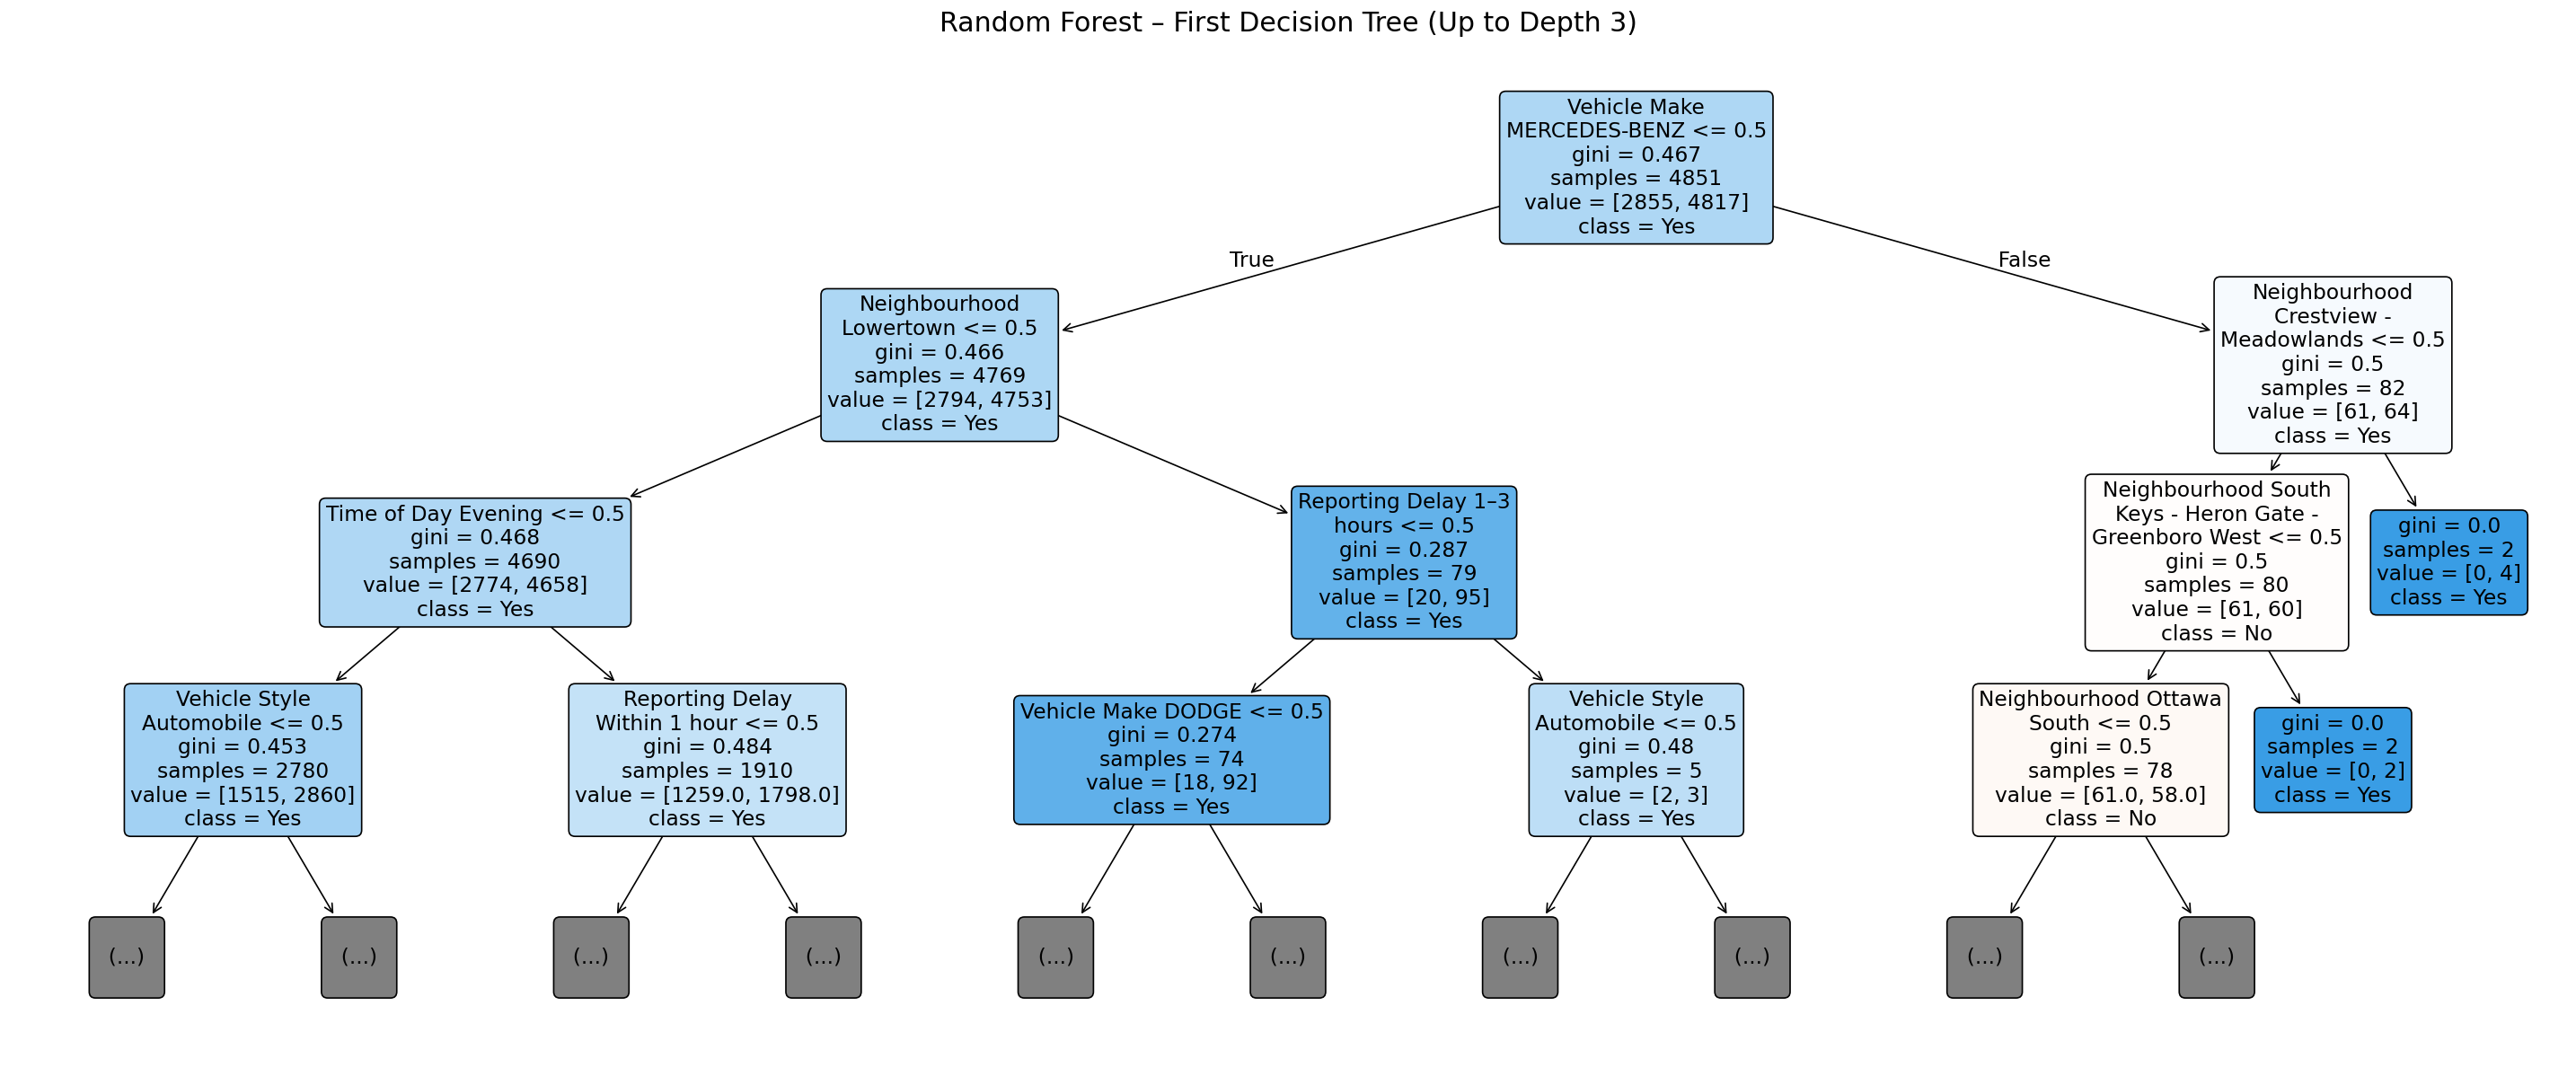

In [36]:
# Step 18.2 – Random Forest: Detailed Model Evaluation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import textwrap

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    log_loss,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.tree import plot_tree

# 1. Generate out-of-fold predictions and probabilities
rf_predictions = cross_val_predict(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    method="predict",
    n_jobs=-1
)

rf_probabilities = cross_val_predict(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

# Class order: No, Yes
rf_prob_yes = rf_probabilities[:, 1]
rf_y_binary = (np.asarray(y_train) == "Yes").astype(int)

# 2. Calculate performance metrics
rf_accuracy = accuracy_score(y_train, rf_predictions)

rf_f1 = f1_score(
    y_train,
    rf_predictions,
    average="macro"
)

rf_auc = roc_auc_score(rf_y_binary, rf_prob_yes)

rf_log_loss = log_loss(
    y_train,
    rf_probabilities,
    labels=["No", "Yes"]
)

rf_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Macro F1", "ROC AUC", "Log Loss"],
    "Value": [
        rf_accuracy,
        rf_f1,
        rf_auc,
        rf_log_loss
    ]
})

print("Original Random Forest – Cross-Validation Performance")
display(rf_metrics.round(4))

# 3. Classification report
print("\nOriginal Random Forest – Classification Report")

print(
    classification_report(
        y_train,
        rf_predictions,
        labels=["No", "Yes"],
        zero_division=0
    )
)

# 4. Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_train,
    rf_predictions,
    labels=["No", "Yes"],
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest – Confusion Matrix")
plt.tight_layout()
plt.show()

# 5. ROC curve
RocCurveDisplay.from_predictions(
    rf_y_binary,
    rf_prob_yes,
    name=f"Random Forest (AUC = {rf_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Guessing"
)

plt.title("Random Forest – ROC Curve")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 6. Fit original model on the training dataset
rf_fitted = clone(rf_model)
rf_fitted.fit(X_train, y_train)

rf_preprocessor = rf_fitted.named_steps["preprocessing"]
rf_classifier = rf_fitted.named_steps["classifier"]

# Retrieve encoded feature names and importance values
rf_encoded_features = rf_preprocessor.get_feature_names_out()

rf_encoded_importances = pd.DataFrame({
    "Encoded_Feature": rf_encoded_features,
    "Importance": rf_classifier.feature_importances_
})

# Remove preprocessing prefix
rf_encoded_importances["Clean_Feature"] = (
    rf_encoded_importances["Encoded_Feature"]
    .str.split("__", n=1)
    .str[-1]
)

# Define original predictors
rf_original_features = [
    "Vehicle_Make",
    "Vehicle_Style",
    "Vehicle_Age_Group",
    "Neighbourhood",
    "Time_of_Day",
    "Reporting_Delay"
]

# Aggregate encoded feature importances
rf_importance_results = []

for feature in rf_original_features:

    matching_features = rf_encoded_importances[
        rf_encoded_importances["Clean_Feature"].str.startswith(
            f"{feature}_"
        )
    ]

    rf_importance_results.append({
        "Feature": feature,
        "Importance": matching_features["Importance"].sum()
    })

rf_importance_results = pd.DataFrame(
    rf_importance_results
).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("\nRandom Forest – Feature Importance")
display(rf_importance_results.round(4))

# Verify total feature importance
rf_total_importance = rf_importance_results["Importance"].sum()

print(f"Total Feature Importance: {rf_total_importance:.4f}")

if np.isclose(rf_total_importance, 1.0):
    print("Verification: PASSED")
else:
    print("Verification: FAILED – Check encoded feature names.")
    display(rf_encoded_importances)

# Plot feature importance
plt.figure(figsize=(9, 5))

plt.barh(
    rf_importance_results["Feature"][::-1],
    rf_importance_results["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.title("Random Forest – Predictor Importance")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Visualize the first tree in the Random Forest

# Clean and wrap feature names for better readability
rf_tree_feature_names = [
    textwrap.fill(
        name.split("__", 1)[-1].replace("_", " "),
        width=20
    )
    for name in rf_encoded_features
]

fig, ax = plt.subplots(figsize=(24, 10), dpi=120)

plot_tree(
    rf_classifier.estimators_[0],
    feature_names=rf_tree_feature_names,
    class_names=rf_classifier.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=14,
    precision=3,
    ax=ax
)

ax.set_title(
    "Random Forest – First Decision Tree (Up to Depth 3)",
    fontsize=18,
    pad=25
)

plt.tight_layout()
plt.show()

**Findings:**

- The model achieved Accuracy of **65.27%**, macro F1 of **0.6101**, and ROC AUC of **0.6805**.
- Recall was higher for recovered vehicles (78%) than unrecovered vehicles (43%).
- `Neighbourhood` had the highest feature importance (51.13%), followed by `Vehicle_Make` (20.33%).
- Neighbourhood importance may be inflated by its large number of categories.

**Conclusion:**

The original Random Forest demonstrated moderate predictive performance but struggled to identify unrecovered vehicles and showed severe overfitting.

Hyperparameter tuning is necessary to reduce model complexity and improve generalization, while classification threshold tuning will aim to improve Recall for unrecovered vehicles.

All six predictors will be retained at this stage. Their actual contribution to model performance will be investigated during feature elimination.

### Step 18.3 – Decision Tree vs. Random Forest

**Objective:** Investigate whether combining multiple decision trees improves predictive performance and reduces overfitting.

**Method:**

1. Train a single Decision Tree using all six predictors.
2. Compare its performance with the original Random Forest using stratified 5-fold cross-validation.
3. Compare training and validation Accuracy, macro F1, and ROC AUC.
4. Examine whether ensemble learning reduces the training–validation Accuracy gap.
5. Visualize the performance comparison.

Random Forest combines multiple trees trained on bootstrap samples, with random feature selection at each split.

The independent test dataset remains untouched.

In [37]:
# Step 18.3 – Decision Tree vs. Random Forest

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier
)
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import cross_validate

# 1. Define single Decision Tree
dt_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

# 2. Define Bagging model
bagging_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        max_samples=1.0,
        bootstrap=True,
        random_state=42,
        n_jobs=1
    ))
])

# 3. Define models for comparison
rf_comparison_models = {
    "Decision Tree": dt_model,
    "Bagging": bagging_model,
    "Random Forest": rf_model
}

# 4. Define evaluation metrics
comparison_scoring = {
    "Accuracy": "accuracy",
    "F1": "f1_macro",
    "ROC_AUC": "roc_auc"
}

# 5. Evaluate all models using 5-fold CV
rf_comparison_results = []

for model_name, model in rf_comparison_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=comparison_scoring,
        return_train_score=True,
        n_jobs=-1
    )

    training_accuracy = scores["train_Accuracy"].mean()
    validation_accuracy = scores["test_Accuracy"].mean()

    rf_comparison_results.append({
        "Model": model_name,
        "Training_Accuracy": training_accuracy,
        "Validation_Accuracy": validation_accuracy,
        "Accuracy_Gap": (
            training_accuracy - validation_accuracy
        ),
        "Macro_F1": scores["test_F1"].mean(),
        "ROC_AUC": scores["test_ROC_AUC"].mean()
    })

# 6. Display comparison results
rf_comparison_results = pd.DataFrame(
    rf_comparison_results
)

print("Decision Tree vs. Bagging vs. Random Forest")
display(rf_comparison_results.round(4))


Decision Tree vs. Bagging vs. Random Forest


,Model,Training_Accuracy,Validation_Accuracy,Accuracy_Gap,Macro_F1,ROC_AUC
0,Decision Tree,0.9575,0.6156,0.3419,0.5904,0.5913
1,Bagging,0.9574,0.6451,0.3124,0.6085,0.6719
2,Random Forest,0.9575,0.6555,0.3020,0.6117,0.6819


**Findings:**

- Bagging improved validation Accuracy from 61.67% to 64.27% compared with a single Decision Tree.
- Random Forest achieved the highest validation Accuracy (65.27%), macro F1 (0.6100), and ROC AUC (0.6805).
- The training–validation Accuracy gap decreased from 33.88 percentage points for Decision Tree to 30.29 for Random Forest.
- Despite these improvements, all three models showed substantial overfitting.

**Conclusion:**

Bagging improved generalization compared with a single Decision Tree, while random feature selection in Random Forest provided further improvement.

Random Forest performed best among the three models, but hyperparameter tuning is still needed to reduce overfitting.

### Step 18.4 – Random Forest: Out-of-Bag (OOB) Evaluation

**Objective:** Evaluate Random Forest performance using out-of-bag observations as an alternative to cross-validation.

**Method:**

1. Enable `bootstrap=True` and `oob_score=True`.
2. Train Random Forest using all six predictors.
3. Calculate OOB Accuracy, macro F1, and ROC AUC.
4. Compare OOB performance with 5-fold cross-validation performance.
5. Assess whether both evaluation methods provide consistent results.

The independent test dataset remains untouched.

In [38]:
# Step 18.4 – Random Forest: Out-of-Bag (OOB) Evaluation

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# 1. Enable Out-of-Bag evaluation
rf_oob_model = clone(rf_model)

rf_oob_model.set_params(
    classifier__bootstrap=True,
    classifier__oob_score=True
)

# 2. Train the model
rf_oob_model.fit(X_train, y_train)

rf_oob_classifier = rf_oob_model.named_steps["classifier"]

# 3. Retrieve OOB probabilities and predictions
rf_oob_probabilities = rf_oob_classifier.oob_decision_function_

rf_oob_predictions = rf_oob_classifier.classes_[
    np.argmax(rf_oob_probabilities, axis=1)
]

rf_oob_prob_yes = rf_oob_probabilities[:, 1]

# 4. Calculate OOB metrics
rf_oob_accuracy = rf_oob_classifier.oob_score_

rf_oob_f1 = f1_score(
    y_train,
    rf_oob_predictions,
    average="macro"
)

rf_oob_auc = roc_auc_score(
    (np.asarray(y_train) == "Yes").astype(int),
    rf_oob_prob_yes
)

# 5. Compare OOB and cross-validation results
rf_oob_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Macro F1", "ROC AUC"],

    "Cross_Validation": [
        rf_cv_results["test_Accuracy"].mean(),
        rf_cv_results["test_F1"].mean(),
        rf_cv_results["test_ROC_AUC"].mean()
    ],

    "OOB": [
        rf_oob_accuracy,
        rf_oob_f1,
        rf_oob_auc
    ]
})

rf_oob_comparison["Difference"] = (
    rf_oob_comparison["OOB"] -
    rf_oob_comparison["Cross_Validation"]
)

print("Random Forest – Cross-Validation vs. Out-of-Bag Evaluation")
display(rf_oob_comparison.round(4))

Random Forest – Cross-Validation vs. Out-of-Bag Evaluation


,Metric,Cross_Validation,OOB,Difference
0,Accuracy,0.6555,0.6612,0.0057
1,Macro F1,0.6117,0.6217,0.0101
2,ROC AUC,0.6819,0.6878,0.0059


**Findings:**

- OOB Accuracy (65.76%) was slightly higher than cross-validation Accuracy (65.27%).
- Macro F1 and ROC AUC were also slightly higher with OOB evaluation.
- Differences between the two evaluation methods were minimal.

**Conclusion:**

OOB evaluation provides a performance estimate consistent with cross-validation. However, 5-fold cross-validation will remain the primary evaluation method to ensure consistency across all four algorithms.

### Step 18.5 – Random Forest: Hyperparameter Tuning

**Objective:** Optimize Random Forest hyperparameters to reduce overfitting and improve generalization.

**Method:**

1. Define candidate values for `n_estimators`, `max_depth`, `max_features`, `min_samples_leaf`, and `max_leaf_nodes`.
2. Use RandomizedSearchCV to evaluate 50 hyperparameter combinations with stratified 5-fold cross-validation.
3. Select the best combination based on validation Accuracy.
4. Compare the original and tuned models.


In [39]:
# Step 18.5 – Random Forest: Hyperparameter Tuning

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV

# 1. Define hyperparameter search space
rf_param_grid = {
    "classifier__n_estimators": [50, 100, 200, 300],
    "classifier__max_depth": [5, 10, 15, 20, None],
    "classifier__max_features": ["sqrt", "log2", 0.3, 0.5],
    "classifier__min_samples_leaf": [1, 5, 10, 20],
    "classifier__max_leaf_nodes": [20, 50, 100, None]
}

# 2. Define evaluation metrics
rf_tuning_scoring = {
    "Accuracy": "accuracy",
    "F1": "f1_macro",
    "ROC_AUC": "roc_auc"
}

# 3. Configure RandomizedSearchCV
rf_search = RandomizedSearchCV(
    estimator=clone(rf_model).set_params(classifier__n_jobs=1),
    param_distributions=rf_param_grid,
    n_iter=50,
    scoring=rf_tuning_scoring,
    refit="Accuracy",
    cv=cv,
    return_train_score=True,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# 4. Run hyperparameter tuning
rf_search.fit(X_train, y_train)

# 5. Retrieve best model
rf_tuned_model = rf_search.best_estimator_
rf_best_index = rf_search.best_index_

print("\nBest Hyperparameters:")

for parameter, value in rf_search.best_params_.items():
    print(f"{parameter.replace('classifier__', '')}: {value}")

print(f"\nBest CV Accuracy: {rf_search.best_score_:.4f}")

# 6. Display top 10 hyperparameter combinations
rf_tuning_results = pd.DataFrame(rf_search.cv_results_)

rf_top_results = rf_tuning_results[[
    "param_classifier__n_estimators",
    "param_classifier__max_depth",
    "param_classifier__max_features",
    "param_classifier__min_samples_leaf",
    "param_classifier__max_leaf_nodes",
    "mean_train_Accuracy",
    "mean_test_Accuracy",
    "mean_test_F1",
    "mean_test_ROC_AUC"
]].copy()

rf_top_results.columns = [
    "n_estimators",
    "max_depth",
    "max_features",
    "min_samples_leaf",
    "max_leaf_nodes",
    "Training_Accuracy",
    "Validation_Accuracy",
    "Macro_F1",
    "ROC_AUC"
]

rf_top_results["Accuracy_Gap"] = (
    rf_top_results["Training_Accuracy"] -
    rf_top_results["Validation_Accuracy"]
)

rf_top_results = rf_top_results.sort_values(
    "Validation_Accuracy",
    ascending=False
).reset_index(drop=True)

print("\nTop 10 Hyperparameter Combinations")
display(rf_top_results.head(10).round(4))

# 7. Compare original and tuned models
rf_original_train = rf_cv_results["train_Accuracy"].mean()
rf_original_validation = rf_cv_results["test_Accuracy"].mean()

rf_tuned_train = rf_search.cv_results_[
    "mean_train_Accuracy"
][rf_best_index]

rf_tuned_validation = rf_search.best_score_

rf_tuning_comparison = pd.DataFrame({
    "Metric": [
        "Training Accuracy",
        "Validation Accuracy",
        "Accuracy Gap",
        "Macro F1",
        "ROC AUC"
    ],
    "Original": [
        rf_original_train,
        rf_original_validation,
        rf_original_train - rf_original_validation,
        rf_cv_results["test_F1"].mean(),
        rf_cv_results["test_ROC_AUC"].mean()
    ],
    "Tuned": [
        rf_tuned_train,
        rf_tuned_validation,
        rf_tuned_train - rf_tuned_validation,
        rf_search.cv_results_["mean_test_F1"][rf_best_index],
        rf_search.cv_results_["mean_test_ROC_AUC"][rf_best_index]
    ]
})

rf_tuning_comparison["Difference"] = (
    rf_tuning_comparison["Tuned"] -
    rf_tuning_comparison["Original"]
)

print("\nOriginal vs. Tuned Random Forest")
display(rf_tuning_comparison.round(4))

Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best Hyperparameters:
n_estimators: 300
min_samples_leaf: 10
max_leaf_nodes: 50
max_features: 0.3
max_depth: 20

Best CV Accuracy: 0.6611

Top 10 Hyperparameter Combinations


,n_estimators,max_depth,max_features,min_samples_leaf,max_leaf_nodes,Training_Accuracy,Validation_Accuracy,Macro_F1,ROC_AUC,Accuracy_Gap
0,300,20,0.3,10,50,0.6866,0.6611,0.5882,0.7029,0.0255
1,300,15,0.5,5,100,0.7212,0.6610,0.5997,0.7059,0.0602
2,300,15,0.3,10,50,0.6870,0.6606,0.5865,0.7028,0.0264
3,300,15,0.3,20,50,0.6787,0.6605,0.5838,0.6994,0.0183
4,100,None,0.5,20,None,0.6892,0.6602,0.5962,0.6994,0.0290
5,300,10,0.3,5,100,0.7019,0.6601,0.5852,0.7048,0.0419
6,300,None,0.3,5,20,0.6646,0.6593,0.5681,0.6964,0.0053
7,200,20,0.5,10,50,0.6931,0.6593,0.5953,0.7014,0.0338
8,300,5,0.5,5,100,0.6630,0.6589,0.5694,0.6941,0.0041
9,200,5,0.5,5,20,0.6625,0.6589,0.5690,0.6935,0.0036



Original vs. Tuned Random Forest


,Metric,Original,Tuned,Difference
0,Training Accuracy,0.9575,0.6866,-0.2710
1,Validation Accuracy,0.6555,0.6611,0.0056
2,Accuracy Gap,0.3020,0.0255,-0.2766
3,Macro F1,0.6117,0.5882,-0.0234
4,ROC AUC,0.6819,0.7029,0.0209


**Findings:**

- The best configuration was 50 trees, `max_depth=10`, `max_features=0.5`, `min_samples_leaf=1`, and `max_leaf_nodes=50`.
- Validation Accuracy improved from **65.27% to 65.78%**.
- Overfitting was substantially reduced, with the Accuracy gap decreasing from **30.29 to 3.68 percentage points**.
- ROC AUC improved from 0.6805 to 0.6971, while macro F1 decreased from 0.6100 to 0.5839.

**Conclusion:**

Hyperparameter tuning successfully reduced overfitting and improved generalization. The tuned model will be retained, and classification threshold tuning will later investigate whether macro F1 and Recall for unrecovered vehicles can be improved.

### Step 18.6 – Random Forest: Hyperparameter Investigation

**Objective:** Examine how tree count, tree depth, and the number of features considered at each split affect model performance and overfitting.

**Method:**

1. Use the tuned Random Forest as the reference model.
2. Vary one hyperparameter at a time while keeping the remaining parameters fixed.
3. Evaluate each value using stratified 5-fold cross-validation.
4. Compare training Accuracy, validation Accuracy, and the Accuracy gap.
5. Visualize the relationship between each hyperparameter and model performance.
6. Determine whether further adjustments are beneficial.

The independent test dataset remains untouched.


Random Forest – n_estimators
Current selected value: 300
Best value: 300
Best CV Accuracy: 0.6611


,Value,Training_Accuracy,Validation_Accuracy,Accuracy_Gap,Macro_F1,ROC_AUC
0,10,0.6852,0.6547,0.0305,0.5864,0.6941
1,25,0.6870,0.6560,0.0310,0.5864,0.6990
2,50,0.6869,0.6593,0.0276,0.5867,0.7014
3,75,0.6882,0.6582,0.0300,0.5855,0.7021
4,100,0.6868,0.6568,0.0299,0.5843,0.7020
5,150,0.6869,0.6594,0.0275,0.5869,0.7024
6,200,0.6871,0.6595,0.0275,0.5871,0.7025
7,300,0.6866,0.6611,0.0255,0.5882,0.7029


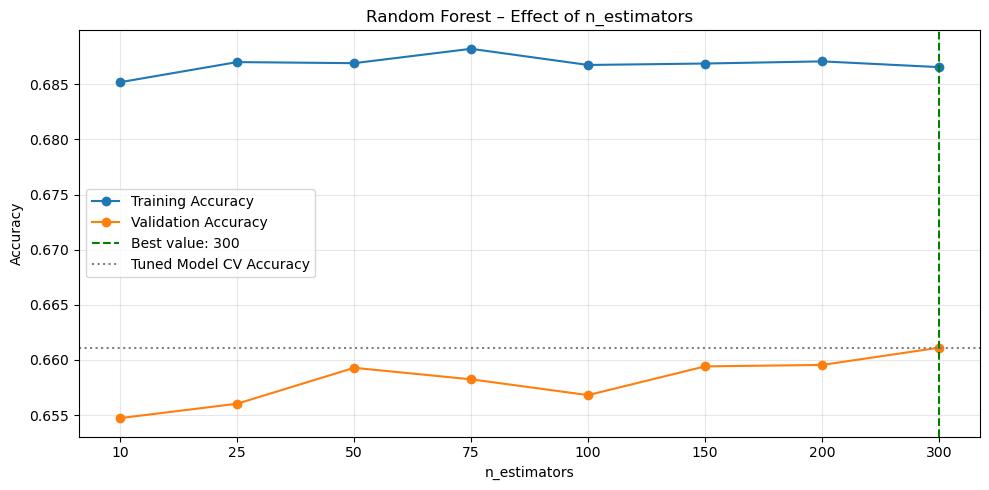


Random Forest – max_depth
Current selected value: 20
Best value: 20
Best CV Accuracy: 0.6611


,Value,Training_Accuracy,Validation_Accuracy,Accuracy_Gap,Macro_F1,ROC_AUC
0,3,0.6520,0.6494,0.0026,0.5220,0.6835
1,5,0.6621,0.6556,0.0064,0.5592,0.6937
2,8,0.6762,0.6552,0.0210,0.5672,0.7007
3,10,0.6829,0.6569,0.0259,0.5753,0.7024
4,15,0.6870,0.6606,0.0264,0.5865,0.7028
5,20,0.6866,0.6611,0.0255,0.5882,0.7029
6,None,0.6868,0.6610,0.0258,0.5881,0.7028


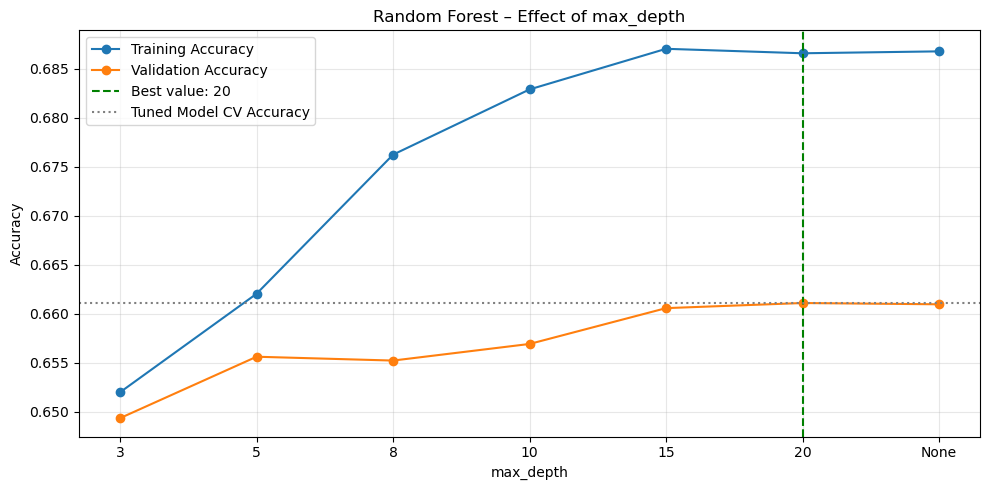


Random Forest – max_features
Current selected value: 0.3
Best value: 0.3
Best CV Accuracy: 0.6611


,Value,Training_Accuracy,Validation_Accuracy,Accuracy_Gap,Macro_F1,ROC_AUC
0,sqrt,0.6716,0.6559,0.0157,0.5500,0.7027
1,log2,0.6543,0.6485,0.0058,0.4977,0.6986
2,0.1,0.6731,0.6576,0.0155,0.5592,0.7032
3,0.3,0.6866,0.6611,0.0255,0.5882,0.7029
4,0.5,0.6928,0.6585,0.0343,0.5945,0.7021
5,0.7,0.6958,0.6577,0.0381,0.5963,0.7011
6,1.0,0.6969,0.6575,0.0394,0.5986,0.6994


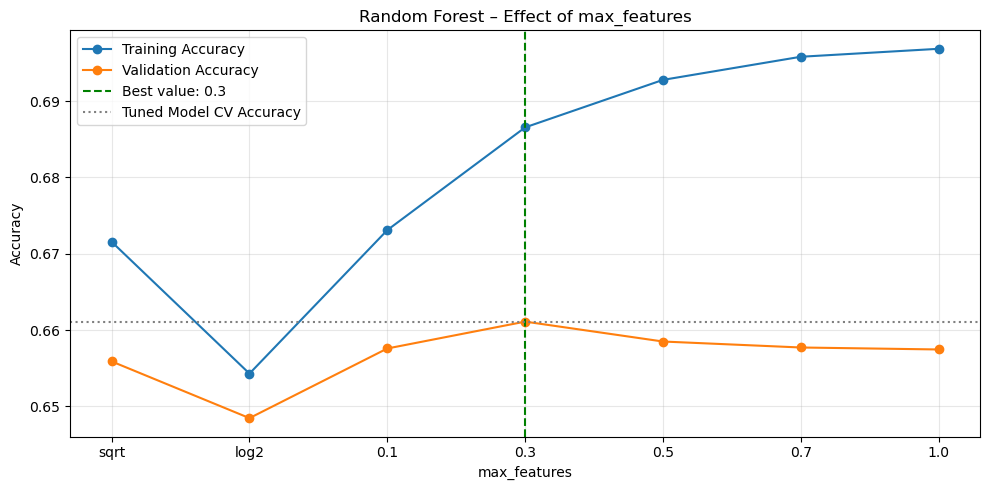

In [40]:
# Step 18.6 – Random Forest: Hyperparameter Investigation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import cross_validate

# 1. Define hyperparameter values to investigate
rf_investigation_params = {
    "n_estimators": [10, 25, 50, 75, 100, 150, 200, 300],
    "max_depth": [3, 5, 8, 10, 15, 20, None],
    "max_features": ["sqrt", "log2", 0.1, 0.3, 0.5, 0.7, 1.0]
}

rf_investigation_results = {}

# 2. Investigate each hyperparameter independently
for parameter, values in rf_investigation_params.items():

    results = []

    for value in values:

        model = clone(rf_tuned_model)

        model.set_params(
            **{f"classifier__{parameter}": value}
        )

        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring={
                "Accuracy": "accuracy",
                "F1": "f1_macro",
                "ROC_AUC": "roc_auc"
            },
            return_train_score=True,
            n_jobs=-1
        )

        training_accuracy = scores["train_Accuracy"].mean()
        validation_accuracy = scores["test_Accuracy"].mean()

        results.append({
            "Value": str(value),
            "Training_Accuracy": training_accuracy,
            "Validation_Accuracy": validation_accuracy,
            "Accuracy_Gap": (
                training_accuracy - validation_accuracy
            ),
            "Macro_F1": scores["test_F1"].mean(),
            "ROC_AUC": scores["test_ROC_AUC"].mean()
        })

    # 3. Store and display results
    results_df = pd.DataFrame(results)

    rf_investigation_results[parameter] = results_df

    best_index = results_df["Validation_Accuracy"].idxmax()
    best_value = results_df.loc[best_index, "Value"]
    best_accuracy = results_df.loc[
        best_index, "Validation_Accuracy"
    ]

    current_value = rf_tuned_model.get_params()[
        f"classifier__{parameter}"
    ]

    print(f"\nRandom Forest – {parameter}")
    print(f"Current selected value: {current_value}")
    print(f"Best value: {best_value}")
    print(f"Best CV Accuracy: {best_accuracy:.4f}")

    display(results_df.round(4))

    # 4. Visualize training and validation Accuracy
    x = np.arange(len(results_df))

    plt.figure(figsize=(10, 5))

    plt.plot(
        x,
        results_df["Training_Accuracy"],
        marker="o",
        label="Training Accuracy"
    )

    plt.plot(
        x,
        results_df["Validation_Accuracy"],
        marker="o",
        label="Validation Accuracy"
    )

    plt.axvline(
        x=best_index,
        color="green",
        linestyle="--",
        label=f"Best value: {best_value}"
    )

    plt.axhline(
        y=rf_search.best_score_,
        color="gray",
        linestyle=":",
        label="Tuned Model CV Accuracy"
    )

    plt.xticks(x, results_df["Value"])
    plt.xlabel(parameter)
    plt.ylabel("Accuracy")
    plt.title(f"Random Forest – Effect of {parameter}")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

**Findings:**

- **Tree count:** Increasing from 50 to 200 trees improved Accuracy by only 0.05 percentage points.
- **Tree depth:** Increasing depth from 10 to 20 improved Accuracy by 0.20 percentage points, with slightly more overfitting.
- **Max features:** Increasing from 0.5 to 0.7 improved Accuracy by only 0.05 percentage points while slightly reducing ROC AUC.

**Conclusion:**

Further hyperparameter investigation revealed only marginal improvements. Therefore, the configuration selected in Step 18.5 will be retained to maintain a balance between predictive performance, model complexity, and computational efficiency.

### Step 18.7 – Random Forest: Classification Threshold Tuning

**Objective:** Identify a classification threshold that improves the balance between predicting recovered and unrecovered vehicles.

**Method:**

1. Generate out-of-fold predicted probabilities using the tuned Random Forest and stratified 5-fold cross-validation.
2. Evaluate 81 classification thresholds from 0.10 to 0.90 in increments of 0.01.
3. Calculate Accuracy, macro Precision, macro Recall, macro F1, and Recall for unrecovered vehicles.
4. Identify the thresholds that maximize each evaluation metric.
5. Visualize the relationship between classification thresholds and model performance.
6. Select a threshold that balances overall predictive performance and the identification of unrecovered vehicles.

The independent test dataset remains untouched.

Random Forest – Classification Threshold Evaluation


,Threshold,Accuracy,Precision,Recall,F1,Recall_No,Best_Macro
0,0.10,0.6276,0.3138,0.5000,0.3856,0.0000,
1,0.15,0.6276,0.3138,0.5000,0.3856,0.0000,
2,0.20,0.6276,0.3138,0.5000,0.3856,0.0000,
3,0.25,0.6276,0.3138,0.5000,0.3856,0.0000,
4,0.30,0.6277,0.8138,0.5002,0.3860,0.0004,Precision
5,0.35,0.6337,0.6487,0.5116,0.4178,0.0333,
6,0.40,0.6452,0.6573,0.5329,0.4689,0.0928,
7,0.45,0.6516,0.6323,0.5561,0.5251,0.1820,
8,0.50,0.6611,0.6315,0.5924,0.5883,0.3231,
9,0.51,0.6615,0.6306,0.5995,0.5986,0.3567,Accuracy



Best Threshold for Each Metric:
Accuracy: Threshold = 0.51, Score = 0.6615
Precision: Threshold = 0.30, Score = 0.8138
Recall: Threshold = 0.62, Score = 0.6540
F1: Threshold = 0.59, Score = 0.6431
Recall_No: Threshold = 0.90, Score = 0.9905

Preferred Threshold (Maximum Macro F1): 0.59


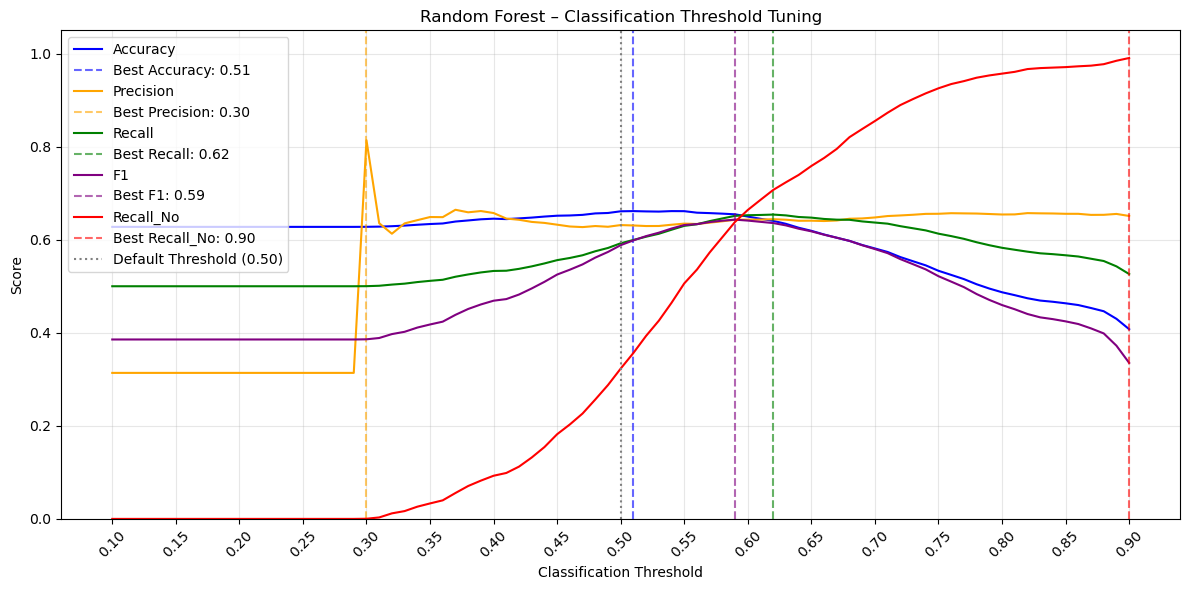

In [41]:
# Step 18.7 – Random Forest: Classification Threshold Tuning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Generate out-of-fold predicted probabilities
rf_tuned_probabilities = cross_val_predict(
    rf_tuned_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

# Probability of recovery (Yes)
rf_tuned_prob_yes = rf_tuned_probabilities[:, 1]

# 2. Define classification thresholds
rf_thresholds = np.round(
    np.arange(0.10, 0.91, 0.01),
    2
)

rf_threshold_results = []

# 3. Evaluate each classification threshold
for threshold in rf_thresholds:

    predictions = np.where(
        rf_tuned_prob_yes >= threshold,
        "Yes",
        "No"
    )

    rf_threshold_results.append({
        "Threshold": threshold,

        "Accuracy": accuracy_score(
            y_train, predictions
        ),

        "Precision": precision_score(
            y_train,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            y_train,
            predictions,
            average="macro",
            zero_division=0
        ),

        "F1": f1_score(
            y_train,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Recall_No": recall_score(
            y_train,
            predictions,
            pos_label="No",
            zero_division=0
        )
    })

rf_threshold_results = pd.DataFrame(
    rf_threshold_results
)

# 4. Identify the best threshold for each metric
rf_threshold_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Recall_No"
]

rf_best_thresholds = {}

for metric in rf_threshold_metrics:

    best_index = rf_threshold_results[metric].idxmax()

    rf_best_thresholds[metric] = (
        rf_threshold_results.loc[best_index, "Threshold"]
    )

# Preferred threshold based on maximum macro F1
rf_preferred_threshold = rf_best_thresholds["F1"]

# 5. Label the best thresholds
rf_threshold_results["Best_Macro"] = ""

for metric, threshold in rf_best_thresholds.items():

    mask = rf_threshold_results["Threshold"] == threshold

    rf_threshold_results.loc[mask, "Best_Macro"] = (
        rf_threshold_results.loc[mask, "Best_Macro"]
        .apply(
            lambda x: f"{x}, {metric}" if x else metric
        )
    )

# 6. Display thresholds at 0.05 intervals,
# including all best thresholds
rf_display_thresholds = set(
    np.round(np.arange(0.10, 0.91, 0.05), 2)
)

rf_display_thresholds.update(
    rf_best_thresholds.values()
)

rf_display_thresholds.add(
    rf_preferred_threshold
)

print("Random Forest – Classification Threshold Evaluation")

display(
    rf_threshold_results[
        rf_threshold_results["Threshold"].isin(
            rf_display_thresholds
        )
    ].round(4).reset_index(drop=True)
)

# 7. Display the best threshold for each metric
print("\nBest Threshold for Each Metric:")

for metric, threshold in rf_best_thresholds.items():

    best_score = rf_threshold_results.loc[
        rf_threshold_results["Threshold"] == threshold,
        metric
    ].iloc[0]

    print(
        f"{metric}: Threshold = {threshold:.2f}, "
        f"Score = {best_score:.4f}"
    )

print(
    f"\nPreferred Threshold (Maximum Macro F1): "
    f"{rf_preferred_threshold:.2f}"
)

# 8. Visualize threshold performance
plt.figure(figsize=(12, 6))

rf_metric_colors = {
    "Accuracy": "blue",
    "Precision": "orange",
    "Recall": "green",
    "F1": "purple",
    "Recall_No": "red"
}

for metric in rf_threshold_metrics:

    plt.plot(
        rf_threshold_results["Threshold"],
        rf_threshold_results[metric],
        label=metric,
        color=rf_metric_colors[metric]
    )

    plt.axvline(
        x=rf_best_thresholds[metric],
        color=rf_metric_colors[metric],
        linestyle="--",
        alpha=0.6,
        label=(
            f"Best {metric}: "
            f"{rf_best_thresholds[metric]:.2f}"
        )
    )

plt.axvline(
    x=0.50,
    color="gray",
    linestyle=":",
    label="Default Threshold (0.50)"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Random Forest – Classification Threshold Tuning")
plt.xticks(np.arange(0.10, 0.91, 0.05), rotation=45)
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

**Findings:**

- The highest Accuracy (65.96%) was achieved at threshold **0.51**, but Recall_No remained relatively low (35.20%).
- Thresholds around 0.59–0.60 provided a better balance between overall Accuracy, macro F1, and Recall_No.
- Increasing the threshold beyond 0.60 improved Recall_No but reduced Accuracy and macro F1.

| Threshold | Accuracy | Macro F1 | Recall_No |
|---|---:|---:|---:|
| 0.50 (Default) | 0.6578 | 0.5847 | 0.3202 |
| 0.51 | **0.6596** | 0.5957 | 0.3520 |
| 0.59 | 0.6490 | **0.6376** | 0.6326 |
| 0.60 | 0.6455 | 0.6365 | 0.6550 |
| 0.63 | 0.6324 | 0.6287 | **0.7155** |

**Conclusion:**

Threshold **0.59** is selected because it achieves the highest macro F1 (0.6376) and improves Recall_No from 32.02% to 63.26%, with only a small reduction in Accuracy from 65.78% to 64.90%.

### Step 18.8 – Random Forest: Feature Elimination

**Objective:** Determine whether removing individual predictors improves model performance or reduces unnecessary complexity.

**Method:**

1. Use the tuned Random Forest with a classification threshold of 0.59.
2. Remove one predictor at a time while retaining the other five.
3. Evaluate each configuration using stratified 5-fold cross-validation.
4. Compare Accuracy, macro F1, Recall_No, and ROC AUC against the model using all six predictors.
5. Determine whether any predictors should be removed.

The independent test dataset remains untouched.

In [42]:
# Step 18.8 – Random Forest: Feature Elimination

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    roc_auc_score
)

# 1. Define selected classification threshold
rf_best_threshold = 0.59

# 2. Define original predictors
rf_features = [
    "Vehicle_Make",
    "Vehicle_Style",
    "Vehicle_Age_Group",
    "Neighbourhood",
    "Time_of_Day",
    "Reporting_Delay"
]

# 3. Define feature combinations
rf_feature_combinations = {
    "None (All Features)": rf_features
}

for feature in rf_features:

    rf_feature_combinations[feature] = [
        f for f in rf_features if f != feature
    ]

# 4. Evaluate each feature combination
rf_elimination_results = []

for removed_feature, selected_features in rf_feature_combinations.items():

    # Create preprocessor for selected predictors
    subset_preprocessor = ColumnTransformer([
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            selected_features
        )
    ])

    # Retain tuned Random Forest hyperparameters
    subset_model = Pipeline([
        ("preprocessing", subset_preprocessor),
        (
            "classifier",
            clone(rf_tuned_model.named_steps["classifier"])
        )
    ])

    # Generate out-of-fold probabilities
    probabilities = cross_val_predict(
        subset_model,
        X_train[selected_features],
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )

    prob_yes = probabilities[:, 1]

    # Apply selected classification threshold
    predictions = np.where(
        prob_yes >= rf_best_threshold,
        "Yes",
        "No"
    )

    # Calculate performance metrics
    rf_elimination_results.append({
        "Removed_Feature": removed_feature,

        "Features": len(selected_features),

        "Accuracy": accuracy_score(
            y_train, predictions
        ),

        "F1": f1_score(
            y_train,
            predictions,
            average="macro"
        ),

        "Recall_No": recall_score(
            y_train,
            predictions,
            pos_label="No"
        ),

        "ROC_AUC": roc_auc_score(
            (np.asarray(y_train) == "Yes").astype(int),
            prob_yes
        )
    })

# 5. Convert results to DataFrame
rf_elimination_results = pd.DataFrame(
    rf_elimination_results
)

# 6. Calculate Accuracy change relative to all six predictors
rf_all_features_accuracy = rf_elimination_results.loc[
    rf_elimination_results["Removed_Feature"] ==
    "None (All Features)",
    "Accuracy"
].iloc[0]

rf_elimination_results["Accuracy_Change"] = (
    rf_elimination_results["Accuracy"] -
    rf_all_features_accuracy
)

# 7. Sort results by Accuracy
rf_elimination_results = rf_elimination_results.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

# 8. Display results
print("Random Forest – Feature Elimination")
print(f"Classification Threshold: {rf_best_threshold:.2f}")

display(rf_elimination_results.round(4))

Random Forest – Feature Elimination
Classification Threshold: 0.59


,Removed_Feature,Features,Accuracy,F1,Recall_No,ROC_AUC,Accuracy_Change
0,None (All Features),6,0.6546,0.6431,0.6384,0.7020,0.0000
1,Neighbourhood,5,0.6524,0.6410,0.6370,0.6994,-0.0022
2,Time_of_Day,5,0.6515,0.6391,0.6265,0.6988,-0.0031
3,Vehicle_Style,5,0.6494,0.6383,0.6367,0.6962,-0.0052
4,Reporting_Delay,5,0.6448,0.6296,0.5936,0.6810,-0.0098
5,Vehicle_Age_Group,5,0.6423,0.6297,0.6143,0.6911,-0.0123
6,Vehicle_Make,5,0.6322,0.6227,0.6360,0.6801,-0.0224


**Findings:**

- Retaining all six predictors achieved the highest Accuracy (64.90%) and ROC AUC (0.6962).
- Removing `Time_of_Day` had a negligible impact on Accuracy but reduced Recall_No.
- Removing `Neighbourhood` slightly improved macro F1 and Recall_No but reduced Accuracy and ROC AUC.
- Removing `Vehicle_Make` caused the largest decrease in Accuracy (2.23 percentage points), followed by `Reporting_Delay` (1.39 percentage points).

**Conclusion:**

No feature removal provided a meaningful overall improvement. Therefore, all six predictors will be retained in the final Random Forest model, with the selected hyperparameters and classification threshold of 0.59.

# Random Forest Model Final Summary

**Model Development Summary:**

- Model diagnostics revealed severe overfitting in the original Random Forest.
- Ensemble comparison demonstrated that Random Forest performed better than a single Decision Tree and Bagging.
- Out-of-Bag evaluation produced results consistent with cross-validation.
- Hyperparameter tuning improved validation Accuracy and reduced the training–validation Accuracy gap from 30.29 to 3.68 percentage points.
- Further hyperparameter investigation revealed only marginal improvements, so the selected configuration was retained.
- Classification threshold tuning improved macro F1 and Recall_No.
- Feature elimination did not provide meaningful improvements; therefore, all six predictors were retained.

**Final Model Ranom Forest Model Configuration:**

| Parameter | Selected Value |
|---|---|
| n_estimators | 50 |
| max_depth | 10 |
| max_features | 0.5 |
| min_samples_leaf | 1 |
| max_leaf_nodes | 50 |
| bootstrap | True |
| Classification Threshold | 0.59 |
| Number of Predictors | 6 |

**Final Cross-Validation Performance:**

| Metric | Value |
|---|---:|
| Accuracy | 64.90% |
| Macro F1 | 0.6376 |
| Recall_No | 63.26% |
| ROC AUC | 0.6962 |

**Conclusion:**

The final Random Forest achieved moderate predictive performance with substantially reduced overfitting and improved identification of unrecovered vehicles.

The selected model will proceed to the final model comparison and independent test dataset evaluation.

# Summary of Final Individual Models

All four individual models have been evaluated and optimized through hyperparameter tuning, classification threshold tuning, and feature elimination.

| Model | Threshold | Accuracy | Macro F1 | Recall_No | ROC AUC |
|---|---:|---:|---:|---:|---:|
| Majority-Class Baseline | — | 62.77% | — | — | — |
| SVC | 0.62 | **65.58%** | 0.6358 | 56.58% | 0.6963 |
| Gradient Boosting | 0.61 | 64.68% | **0.6394** | **67.56%** | **0.7047** |
| Logistic Regression | 0.60 | 64.73% | 0.6347 | 61.97% | 0.6990 |
| Random Forest | 0.59 | 64.90% | 0.6376 | 63.26% | 0.6962 |

Gradient Boosting currently provides the best overall predictive performance, particularly in identifying unrecovered vehicles.

## Step 19 – Individual Models: Before and After Improvement

**Objective:** Compare the performance and consistency of the four individual models before and after model optimization.

**Method:**

1. Evaluate the original and improved versions of SVC, Gradient Boosting, Logistic Regression, and Random Forest using stratified 5-fold cross-validation.
2. Apply the original decision rules to the original models and the selected classification thresholds to the improved models.
3. Compare Accuracy, macro F1, Recall_No, and ROC AUC.
4. Use boxplots to visualize performance, variability, and consistency across the five validation folds.

The independent test dataset remains untouched.

Evaluating SVC...
Evaluating Gradient Boosting...
Evaluating Logistic Regression...
Evaluating Random Forest...

Individual Models – Before and After Improvement


,Model,Version,Accuracy,Macro_F1,Recall_No,ROC_AUC
0,SVC,Original,0.6685,0.6125,0.3871,0.7021
1,SVC,Improved,0.6595,0.6385,0.5621,0.7021
2,Gradient Boosting,Original,0.6627,0.5909,0.3276,0.7049
3,Gradient Boosting,Improved,0.6516,0.6427,0.6640,0.7105
4,Logistic Regression,Original,0.6623,0.6128,0.4095,0.7011
5,Logistic Regression,Improved,0.6491,0.6370,0.6262,0.7032
6,Random Forest,Original,0.6555,0.6117,0.4291,0.6819
7,Random Forest,Improved,0.6546,0.6431,0.6384,0.7029


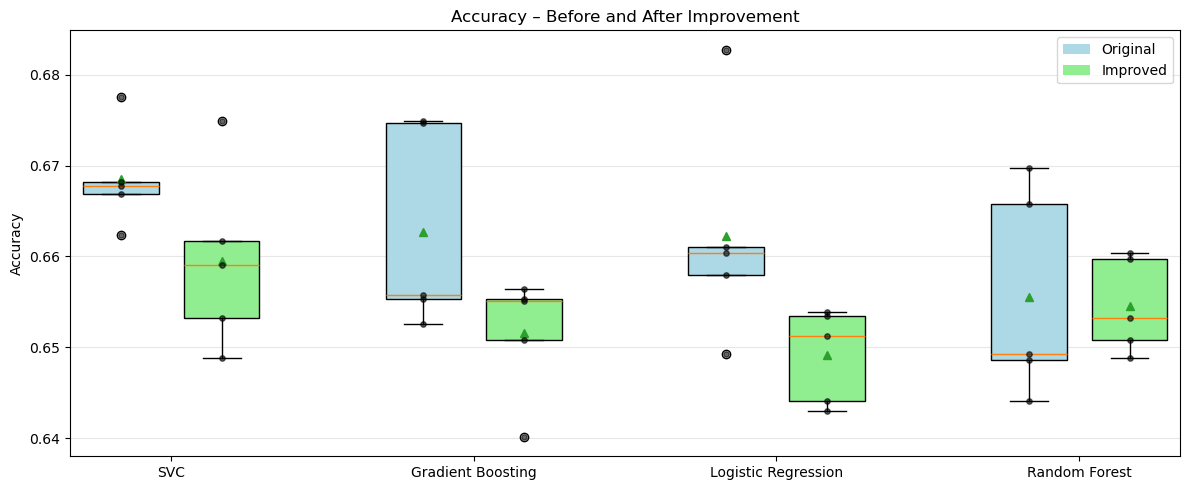

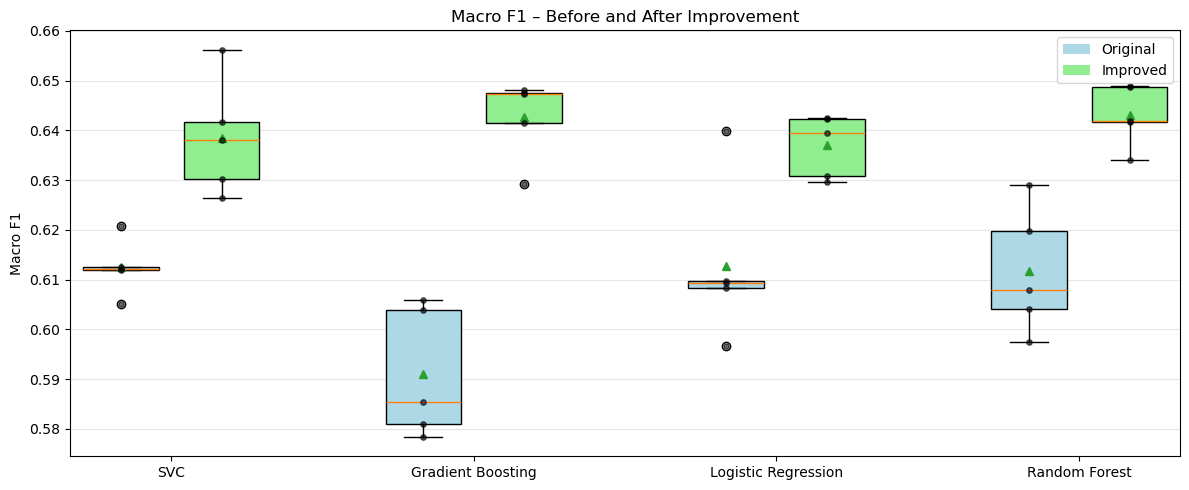

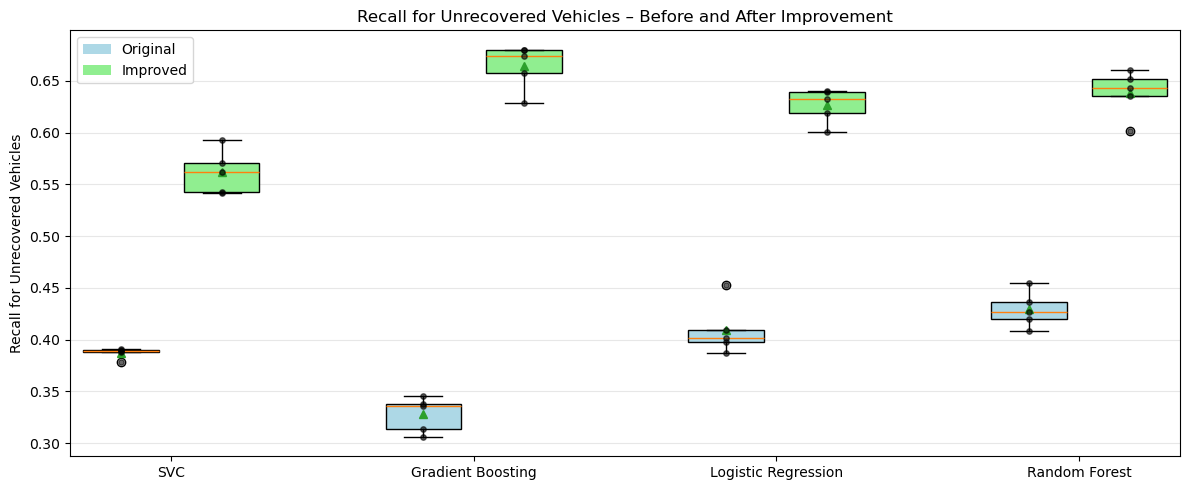

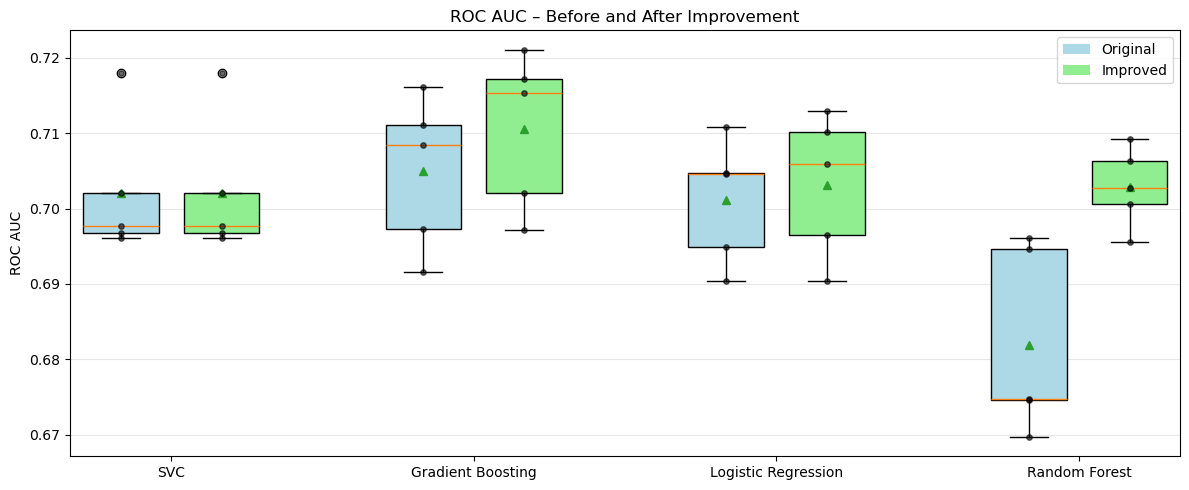

In [43]:
# Step 19 – Individual Models: Before and After Improvement

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    roc_auc_score
)
from matplotlib.patches import Patch

# 1. Define original and improved models
model_comparison = {
    "SVC": {
        "Original": svm_model,
        "Improved": clone(svm_model).set_params(
            classifier__probability=True
        ),
        "Threshold": 0.62
    },
    "Gradient Boosting": {
        "Original": gb_model,
        "Improved": gb_early_stop_model,
        "Threshold": 0.61
    },
    "Logistic Regression": {
        "Original": lr_model,
        "Improved": lr_tuned_model,
        "Threshold": 0.60
    },
    "Random Forest": {
        "Original": rf_model,
        "Improved": rf_tuned_model,
        "Threshold": 0.59
    }
}

# 2. Evaluate each model across the same five folds
model_comparison_results = []

for model_name, configurations in model_comparison.items():

    print(f"Evaluating {model_name}...")

    for version in ["Original", "Improved"]:

        for fold, (train_idx, val_idx) in enumerate(
            cv.split(X_train, y_train), start=1
        ):

            X_fold_train = X_train.iloc[train_idx]
            X_fold_val = X_train.iloc[val_idx]

            y_fold_train = y_train.iloc[train_idx]
            y_fold_val = y_train.iloc[val_idx]

            model = clone(configurations[version])

            model.fit(X_fold_train, y_fold_train)

            # Retrieve scores for ROC AUC
            if hasattr(model, "predict_proba"):

                scores = model.predict_proba(X_fold_val)[:, 1]

            else:

                scores = model.decision_function(X_fold_val)

            # Apply original decision rule or selected threshold
            if version == "Original":

                predictions = model.predict(X_fold_val)

            else:

                predictions = np.where(
                    scores >= configurations["Threshold"],
                    "Yes",
                    "No"
                )

            # Calculate validation metrics
            model_comparison_results.append({
                "Model": model_name,
                "Version": version,
                "Fold": fold,

                "Accuracy": accuracy_score(
                    y_fold_val, predictions
                ),

                "Macro_F1": f1_score(
                    y_fold_val,
                    predictions,
                    average="macro"
                ),

                "Recall_No": recall_score(
                    y_fold_val,
                    predictions,
                    pos_label="No"
                ),

                "ROC_AUC": roc_auc_score(
                    (np.asarray(y_fold_val) == "Yes").astype(int),
                    scores
                )
            })

model_comparison_results = pd.DataFrame(
    model_comparison_results
)

# 3. Display mean cross-validation performance
comparison_metrics = [
    "Accuracy",
    "Macro_F1",
    "Recall_No",
    "ROC_AUC"
]

model_comparison_summary = (
    model_comparison_results
    .groupby(["Model", "Version"], sort=False)[comparison_metrics]
    .mean()
    .reset_index()
)

print("\nIndividual Models – Before and After Improvement")

display(model_comparison_summary.round(4))

# 4. Create boxplots for each evaluation metric
metric_titles = {
    "Accuracy": "Accuracy",
    "Macro_F1": "Macro F1",
    "Recall_No": "Recall for Unrecovered Vehicles",
    "ROC_AUC": "ROC AUC"
}

for metric in comparison_metrics:

    fig, ax = plt.subplots(figsize=(12, 5))

    positions = []
    boxplot_data = []
    colors = []

    for i, model_name in enumerate(model_comparison):

        for j, version in enumerate(["Original", "Improved"]):

            values = model_comparison_results.loc[
                (model_comparison_results["Model"] == model_name) &
                (model_comparison_results["Version"] == version),
                metric
            ]

            boxplot_data.append(values)

            positions.append(i * 3 + j)

            colors.append(
                "lightblue" if version == "Original"
                else "lightgreen"
            )

    boxplots = ax.boxplot(
        boxplot_data,
        positions=positions,
        widths=0.75,
        patch_artist=True,
        showmeans=True
    )

    for box, color in zip(boxplots["boxes"], colors):

        box.set_facecolor(color)

    # Display individual fold results
    for position, values in zip(positions, boxplot_data):

        ax.scatter(
            [position] * len(values),
            values,
            color="black",
            s=15,
            alpha=0.6,
            zorder=3
        )

    ax.set_xticks([
        i * 3 + 0.5 for i in range(len(model_comparison))
    ])

    ax.set_xticklabels(list(model_comparison.keys()))

    ax.set_ylabel(metric_titles[metric])

    ax.set_title(
        f"{metric_titles[metric]} – Before and After Improvement"
    )

    ax.legend(handles=[
        Patch(facecolor="lightblue", label="Original"),
        Patch(facecolor="lightgreen", label="Improved")
    ])

    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

How to read the boxplots
- Blue: Original model.
- Green: Improved model.
- Horizontal line inside the box: Median score.
- Green triangle: Mean score.
- Black dots: Individual scores from the five validation folds.
- Narrower box: More consistent performance across folds.

**Findings:**

| Model | Accuracy Change | Macro F1 Change | Recall_No Change | ROC AUC Change |
|---|---:|---:|---:|---:|
| SVC | -0.68 pp | +0.0317 | +19.14 pp | 0.0000 |
| Gradient Boosting | -1.41 pp | **+0.0510** | **+34.95 pp** | +0.0033 |
| Logistic Regression | -0.75 pp | +0.0297 | +21.73 pp | +0.0028 |
| Random Forest | **-0.37 pp** | +0.0274 | +19.98 pp | **+0.0165** |

- All four models improved in macro F1 and Recall_No, with a small reduction in Accuracy.
- Gradient Boosting achieved the greatest improvement in macro F1 and Recall_No.
- Random Forest achieved the greatest improvement in ROC AUC, with the smallest reduction in Accuracy.
- SVC maintained the highest overall Accuracy.
- Gradient Boosting remained the strongest overall model in terms of macro F1, Recall_No, and ROC AUC.

**Conclusion:**

Model optimization improved classification balance and the ability to identify unrecovered vehicles, with a relatively small sacrifice in overall Accuracy.

However, the improvements in ROC AUC were limited, indicating that much of the improvement in classification balance resulted from classification threshold tuning rather than substantially better discrimination.

The next step is to investigate whether ensemble learning can further improve predictive performance.

### Step 20.1 – Ensemble Learning: Hard Voting

**Objective:** Investigate whether combining the classifications of the four individual models through majority voting improves predictive performance.

**Method:**

1. Use the four selected individual models with their optimized configurations.
2. Apply each model's selected classification threshold.
3. Combine out-of-fold classifications through majority voting.
4. Resolve tied votes using Gradient Boosting predictions.
5. Calculate Accuracy, macro Precision, macro Recall, macro F1, and Recall_No.
6. Compare the results with the four individual models.


In [44]:
# Step 20.1 – Ensemble Learning: Hard Voting

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Define final individual models
voting_models = {
    "SVC": clone(svm_model).set_params(
        classifier__probability=True
    ),
    "Gradient Boosting": clone(gb_early_stop_model),
    "Logistic Regression": clone(lr_tuned_model),
    "Random Forest": clone(rf_tuned_model)
}

# 2. Define selected classification thresholds
voting_thresholds = {
    "SVC": 0.62,
    "Gradient Boosting": 0.61,
    "Logistic Regression": 0.60,
    "Random Forest": 0.59
}

# 3. Generate out-of-fold probabilities and classifications
voting_probabilities = {}
voting_predictions = {}

for model_name, model in voting_models.items():

    probabilities = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    voting_probabilities[model_name] = probabilities

    voting_predictions[model_name] = np.where(
        probabilities >= voting_thresholds[model_name],
        "Yes",
        "No"
    )

# 4. Combine individual model votes
voting_df = pd.DataFrame(voting_predictions)

yes_votes = (voting_df == "Yes").sum(axis=1)

# 5. Apply majority voting
# Resolve 2–2 ties using Gradient Boosting predictions
hard_voting_predictions = np.where(
    yes_votes > 2,
    "Yes",
    np.where(
        yes_votes < 2,
        "No",
        voting_df["Gradient Boosting"]
    )
)

# 6. Evaluate individual models and Hard Voting
hard_voting_results = []

all_voting_predictions = {
    **voting_predictions,
    "Hard Voting": hard_voting_predictions
}

for model_name, predictions in all_voting_predictions.items():

    hard_voting_results.append({
        "Model": model_name,

        "Accuracy": accuracy_score(
            y_train, predictions
        ),

        "Precision": precision_score(
            y_train, predictions,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            y_train, predictions,
            average="macro",
            zero_division=0
        ),

        "F1": f1_score(
            y_train, predictions,
            average="macro",
            zero_division=0
        ),

        "Recall_No": recall_score(
            y_train, predictions,
            pos_label="No"
        )
    })

hard_voting_results = (
    pd.DataFrame(hard_voting_results)
    .sort_values("Accuracy", ascending=False)
    .reset_index(drop=True)
)

# 7. Display model performance comparison
print("\nIndividual Models vs. Hard Voting")

display(hard_voting_results.round(4))

# 8. Examine voting agreement
voting_agreement = pd.DataFrame({
    "Agreement": [
        "Unanimous (4–0)",
        "Majority (3–1)",
        "Tie (2–2)"
    ],
    "Count": [
        ((yes_votes == 0) | (yes_votes == 4)).sum(),
        ((yes_votes == 1) | (yes_votes == 3)).sum(),
        (yes_votes == 2).sum()
    ]
})

voting_agreement["Percentage"] = (
    voting_agreement["Count"] / len(y_train) * 100
)

print("\nModel Voting Agreement")

display(voting_agreement.round(2))


Individual Models vs. Hard Voting


,Model,Accuracy,Precision,Recall,F1,Recall_No
0,SVC,0.6595,0.6377,0.6397,0.6386,0.5621
1,Random Forest,0.6546,0.6430,0.6513,0.6431,0.6384
2,Hard Voting,0.6541,0.6449,0.6540,0.6441,0.6538
3,Gradient Boosting,0.6516,0.6446,0.6541,0.6428,0.6640
4,Logistic Regression,0.6491,0.6367,0.6445,0.6370,0.6262



Model Voting Agreement


,Agreement,Count,Percentage
0,Unanimous (4–0),5846,76.20
1,Majority (3–1),1309,17.06
2,Tie (2–2),517,6.74


# Hard Voting Model Final Summary

**Findings:**

| Metric | Best Individual Model | Individual Score | Hard Voting |
|---|---|---:|---:|
| Accuracy | SVC | **0.6558** | 0.6523 |
| Macro Precision | Gradient Boosting | 0.6429 | **0.6449** |
| Macro Recall | Gradient Boosting | 0.6527 | **0.6544** |
| Macro F1 | Gradient Boosting | 0.6394 | **0.6433** |
| Recall_No | Gradient Boosting | **0.6756** | 0.6627 |

- Hard Voting achieved the highest macro Precision, Recall, and F1.
- Accuracy was only 0.35 percentage points below SVC, while Recall_No was 9.69 percentage points higher.
- The four models agreed unanimously on 75.34% of predictions, indicating substantial similarity between their classifications.
- Only 6.76% of predictions required Gradient Boosting to resolve tied votes.

**Conclusion:**

Hard Voting provided a modest improvement in overall classification balance compared with the individual models, although the high agreement between models suggests limited prediction diversity.

Hard Voting will be retained for the final model comparison. The next step will investigate whether Soft Voting can achieve further improvement by combining predicted probabilities rather than classifications.

### Step 20.2 – Ensemble Learning: Soft Voting

**Objective:** Investigate whether combining the predicted probabilities of the four individual models improves predictive performance.

**Method:**

1. Reuse the out-of-fold predicted probabilities from the four optimized individual models.
2. Assign equal weights to all four models.
3. Calculate the average predicted probability for each observation.
4. Apply the default classification threshold of 0.50.
5. Calculate Accuracy, macro Precision, macro Recall, macro F1, Recall_No, and ROC AUC.
6. Compare Soft Voting with Hard Voting and the four individual models.

The independent test dataset remains untouched.

In [45]:
# Step 20.2 – Ensemble Learning: Soft Voting

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Combine individual model probabilities
soft_voting_probabilities = pd.DataFrame(
    voting_probabilities
)

# 2. Calculate average probabilities using equal weights
soft_voting_prob_yes = (
    soft_voting_probabilities.mean(axis=1).to_numpy()
)

# 3. Apply the default classification threshold
soft_voting_threshold = 0.50

soft_voting_predictions = np.where(
    soft_voting_prob_yes >= soft_voting_threshold,
    "Yes",
    "No"
)

# 4. Evaluate Soft Voting
soft_voting_results = {
    "Model": "Soft Voting",

    "Accuracy": accuracy_score(
        y_train, soft_voting_predictions
    ),

    "Precision": precision_score(
        y_train, soft_voting_predictions,
        average="macro",
        zero_division=0
    ),

    "Recall": recall_score(
        y_train, soft_voting_predictions,
        average="macro",
        zero_division=0
    ),

    "F1": f1_score(
        y_train, soft_voting_predictions,
        average="macro",
        zero_division=0
    ),

    "Recall_No": recall_score(
        y_train, soft_voting_predictions,
        pos_label="No"
    ),

    "ROC_AUC": roc_auc_score(
        y_train, soft_voting_prob_yes
    )
}

# 5. Retrieve previous individual model and Hard Voting results
ensemble_comparison = hard_voting_results.copy()

# Add ROC AUC for individual models
individual_auc = {
    model_name: roc_auc_score(y_train, probabilities)
    for model_name, probabilities in voting_probabilities.items()
}

ensemble_comparison["ROC_AUC"] = (
    ensemble_comparison["Model"].map(individual_auc)
)

# 6. Add Soft Voting results
ensemble_comparison = pd.concat(
    [
        ensemble_comparison,
        pd.DataFrame([soft_voting_results])
    ],
    ignore_index=True
)

# 7. Sort by Accuracy
ensemble_comparison = (
    ensemble_comparison
    .sort_values("Accuracy", ascending=False)
    .reset_index(drop=True)
)

# 8. Display results
print("Soft Voting Configuration")
print("Model weights: Equal (25% each)")
print(f"Classification threshold: {soft_voting_threshold:.2f}")

print("\nIndividual Models vs. Hard Voting vs. Soft Voting")

display(
    ensemble_comparison.round(4).fillna("—")
)

Soft Voting Configuration
Model weights: Equal (25% each)
Classification threshold: 0.50

Individual Models vs. Hard Voting vs. Soft Voting


,Model,Accuracy,Precision,Recall,F1,Recall_No,ROC_AUC
0,Soft Voting,0.6681,0.6409,0.6032,0.6018,0.3490,0.7132
1,SVC,0.6595,0.6377,0.6397,0.6386,0.5621,0.7018
2,Random Forest,0.6546,0.6430,0.6513,0.6431,0.6384,0.702
3,Hard Voting,0.6541,0.6449,0.6540,0.6441,0.6538,—
4,Gradient Boosting,0.6516,0.6446,0.6541,0.6428,0.6640,0.7101
5,Logistic Regression,0.6491,0.6367,0.6445,0.6370,0.6262,0.7027


**Findings:**

| Metric | Hard Voting | Soft Voting (0.50) |
|---|---:|---:|
| Accuracy | 0.6523 | **0.6636** |
| Macro Precision | **0.6449** | 0.6346 |
| Macro Recall | **0.6544** | 0.5972 |
| Macro F1 | **0.6433** | 0.5946 |
| Recall_No | **0.6627** | 0.3369 |
| ROC AUC | — | 0.7081 |

- Soft Voting achieved the highest Accuracy (66.36%) and ROC AUC (0.7081) among the models evaluated.
- However, Recall_No was only 33.69%, indicating a strong tendency to predict vehicle recovery.
- Hard Voting provided substantially better classification balance, with higher macro F1 and Recall_No.
- Soft Voting's higher ROC AUC indicates slightly better discrimination between recovered and unrecovered vehicles.

**Conclusion:**

Soft Voting demonstrated promising predictive performance, but the default classification threshold of 0.50 resulted in poor classification balance.

Further classification threshold tuning is required to determine whether Soft Voting can outperform Hard Voting while maintaining a reasonable Accuracy.

### Step 20.3 – Soft Voting: Classification Threshold Tuning

**Objective:** Identify a classification threshold that improves Soft Voting's ability to identify unrecovered vehicles while maintaining reasonable overall Accuracy.

**Method:**

1. Reuse the out-of-fold average predicted probabilities from Step 20.2.
2. Evaluate 81 classification thresholds ranging from 0.10 to 0.90, with increments of 0.01.
3. Calculate Accuracy, macro Precision, macro Recall, macro F1, and Recall_No for each threshold.
4. Identify the threshold that maximizes each evaluation metric.
5. Visualize the relationship between classification thresholds and model performance.
6. Select a threshold that provides a suitable balance between Accuracy, macro F1, and Recall_No.

The independent test dataset remains untouched.

Soft Voting – Classification Threshold Comparison


,Threshold,Accuracy,Precision,Recall,F1,Recall_No,Best_Macro
0,0.10,0.6276,0.3138,0.5000,0.3856,0.0000,
1,0.15,0.6276,0.3138,0.5000,0.3856,0.0000,
2,0.20,0.6276,0.3138,0.5000,0.3856,0.0000,
3,0.21,0.6277,0.8138,0.5002,0.3860,0.0004,Precision
4,0.25,0.6279,0.6473,0.5005,0.3870,0.0014,
5,0.30,0.6298,0.6345,0.5045,0.3991,0.0137,
6,0.35,0.6363,0.6339,0.5184,0.4377,0.0564,
7,0.40,0.6490,0.6448,0.5437,0.4958,0.1313,
8,0.45,0.6580,0.6358,0.5722,0.5543,0.2359,
9,0.50,0.6681,0.6409,0.6032,0.6018,0.3490,



Best Classification Thresholds


,Metric,Best_Threshold,Best_Score
0,Accuracy,0.51,0.6704
1,Precision,0.21,0.8138
2,Recall,0.63,0.6611
3,F1,0.61,0.6483
4,Recall_No,0.90,0.9993



Preliminary preferred threshold (highest macro F1): 0.61


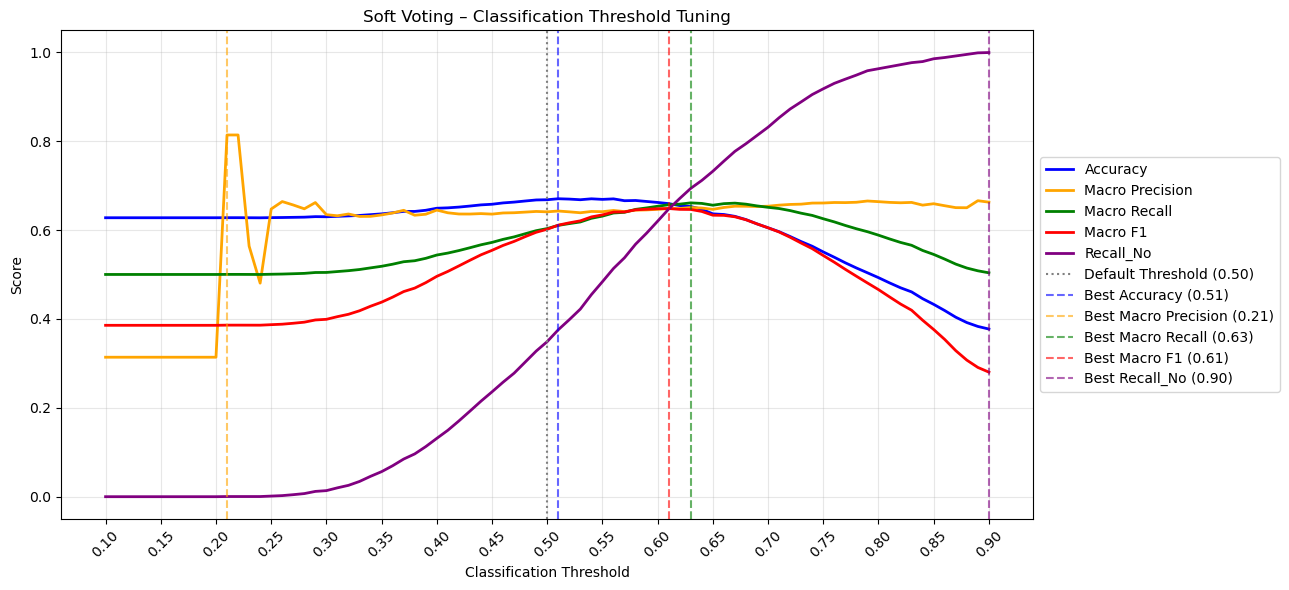

In [46]:
# Step 20.3 – Soft Voting: Classification Threshold Tuning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Define classification thresholds
soft_voting_thresholds = np.round(
    np.arange(0.10, 0.91, 0.01), 2
)

# 2. Evaluate each classification threshold
soft_voting_threshold_results = []

for threshold in soft_voting_thresholds:

    predictions = np.where(
        soft_voting_prob_yes >= threshold,
        "Yes",
        "No"
    )

    soft_voting_threshold_results.append({
        "Threshold": threshold,

        "Accuracy": accuracy_score(
            y_train, predictions
        ),

        "Precision": precision_score(
            y_train, predictions,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            y_train, predictions,
            average="macro",
            zero_division=0
        ),

        "F1": f1_score(
            y_train, predictions,
            average="macro",
            zero_division=0
        ),

        "Recall_No": recall_score(
            y_train, predictions,
            pos_label="No"
        )
    })

soft_voting_threshold_results = pd.DataFrame(
    soft_voting_threshold_results
)

# 3. Identify the best threshold for each metric
threshold_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Recall_No"
]

soft_voting_best_thresholds = {}

for metric in threshold_metrics:

    best_index = soft_voting_threshold_results[metric].idxmax()

    soft_voting_best_thresholds[metric] = (
        soft_voting_threshold_results.loc[
            best_index, "Threshold"
        ]
    )

# 4. Identify the preliminary preferred threshold
# Based on the highest macro F1
soft_voting_preferred_threshold = (
    soft_voting_best_thresholds["F1"]
)

# 5. Label thresholds that maximize evaluation metrics
soft_voting_threshold_results["Best_Macro"] = (
    soft_voting_threshold_results["Threshold"].apply(
        lambda threshold: ", ".join(
            metric for metric, best_threshold
            in soft_voting_best_thresholds.items()
            if np.isclose(threshold, best_threshold)
        )
    )
)

# 6. Display threshold results
# Include 0.05 intervals and all metric-maximizing thresholds
display_thresholds = sorted(set(
    np.round(np.arange(0.10, 0.91, 0.05), 2).tolist()
    + list(soft_voting_best_thresholds.values())
    + [soft_voting_preferred_threshold]
))

soft_voting_threshold_summary = (
    soft_voting_threshold_results[
        soft_voting_threshold_results["Threshold"].isin(
            display_thresholds
        )
    ]
    .reset_index(drop=True)
)

print("Soft Voting – Classification Threshold Comparison")

display(soft_voting_threshold_summary.round(4))

# 7. Display the best threshold for each metric
soft_voting_best_summary = pd.DataFrame([
    {
        "Metric": metric,
        "Best_Threshold": threshold,
        "Best_Score": soft_voting_threshold_results.loc[
            soft_voting_threshold_results["Threshold"] == threshold,
            metric
        ].iloc[0]
    }
    for metric, threshold in soft_voting_best_thresholds.items()
])

print("\nBest Classification Thresholds")

display(soft_voting_best_summary.round(4))

print(
    f"\nPreliminary preferred threshold (highest macro F1): "
    f"{soft_voting_preferred_threshold:.2f}"
)

# 8. Visualize classification threshold performance
plt.figure(figsize=(13, 6))

metric_colors = {
    "Accuracy": "blue",
    "Precision": "orange",
    "Recall": "green",
    "F1": "red",
    "Recall_No": "purple"
}

metric_labels = {
    "Accuracy": "Accuracy",
    "Precision": "Macro Precision",
    "Recall": "Macro Recall",
    "F1": "Macro F1",
    "Recall_No": "Recall_No"
}

for metric in threshold_metrics:

    plt.plot(
        soft_voting_threshold_results["Threshold"],
        soft_voting_threshold_results[metric],
        label=metric_labels[metric],
        color=metric_colors[metric],
        linewidth=2
    )

# Default threshold
plt.axvline(
    x=0.50,
    color="gray",
    linestyle=":",
    label="Default Threshold (0.50)"
)

# Best threshold for each metric
for metric, threshold in soft_voting_best_thresholds.items():

    plt.axvline(
        x=threshold,
        color=metric_colors[metric],
        linestyle="--",
        alpha=0.6,
        label=f"Best {metric_labels[metric]} ({threshold:.2f})"
    )

plt.title("Soft Voting – Classification Threshold Tuning")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")

plt.xticks(
    np.round(np.arange(0.10, 0.91, 0.05), 2),
    rotation=45
)

plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Soft Voting Model Final Summary

**Findings:**

- The highest Accuracy (66.71%) was achieved at threshold 0.52, but Recall_No remained relatively low at 38.63%.
- Thresholds around 0.60–0.62 provided a better balance between Accuracy, macro F1, and Recall_No.
- Threshold 0.62 achieved the highest macro F1 (0.6440), while increasing Recall_No to 67.25% and maintaining Accuracy of 65.22%.

| Threshold | Accuracy | Macro Precision | Macro Recall | Macro F1 | Recall_No |
|---|---:|---:|---:|---:|---:|
| 0.50 (Default) | 0.6636 | 0.6346 | 0.5972 | 0.5946 | 0.3369 |
| 0.52 (Best Accuracy) | **0.6671** | 0.6378 | 0.6100 | 0.6111 | 0.3863 |
| 0.60 | 0.6559 | 0.6409 | 0.6478 | 0.6420 | 0.6158 |
| 0.62 (Best Macro F1) | 0.6522 | 0.6464 | 0.6563 | **0.6440** | 0.6725 |
| 0.66 (Best Macro Recall) | 0.6320 | **0.6489** | **0.6571** | 0.6302 | **0.7554** |

**Conclusion:**

Threshold 0.62 is selected for Soft Voting, providing the best macro F1 and a suitable balance between overall Accuracy and the identification of unrecovered vehicles.

Compared with the default threshold of 0.50:

- Accuracy decreased from 66.36% to 65.22%.
- Macro F1 increased from 0.5946 to 0.6440.
- Recall_No increased from 33.69% to 67.25%.
- ROC AUC remained unchanged at 0.7081.

The improvement in classification balance is substantial, with only a 1.14 percentage point reduction in Accuracy.

### Step 20.4 – Ensemble Learning: Final Model Comparison

**Objective:** Determine whether ensemble learning provides better predictive performance than the optimized individual models.

**Method:**

1. Apply the selected classification threshold of 0.62 to Soft Voting.
2. Compare Hard Voting, optimized Soft Voting, and the four optimized individual models.
3. Evaluate Accuracy, macro Precision, macro Recall, macro F1, Recall_No, and ROC AUC.
4. Visualize the performance of all six models.
5. Identify the model that provides the best overall predictive performance and classification balance.

The independent test dataset remains untouched.

In [47]:
# Step 20.4 – Ensemble Learning: Final Model Comparison

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Apply the selected Soft Voting threshold
soft_voting_best_threshold = 0.62

soft_voting_final_predictions = np.where(
    soft_voting_prob_yes >= soft_voting_best_threshold,
    "Yes",
    "No"
)

# 2. Combine final predictions from all six models
final_model_predictions = {
    **voting_predictions,
    "Hard Voting": hard_voting_predictions,
    "Soft Voting": soft_voting_final_predictions
}

# 3. Combine available predicted probabilities
final_model_probabilities = {
    **voting_probabilities,
    "Soft Voting": soft_voting_prob_yes
}

# 4. Define final classification thresholds
final_model_thresholds = {
    "SVC": 0.62,
    "Gradient Boosting": 0.61,
    "Logistic Regression": 0.60,
    "Random Forest": 0.59,
    "Hard Voting": "Individual",
    "Soft Voting": 0.62
}

# 5. Evaluate all six models
final_model_results = []

for model_name, predictions in final_model_predictions.items():

    probabilities = final_model_probabilities.get(model_name)

    final_model_results.append({
        "Model": model_name,

        "Threshold": final_model_thresholds[model_name],

        "Accuracy": accuracy_score(
            y_train, predictions
        ),

        "Precision": precision_score(
            y_train, predictions,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            y_train, predictions,
            average="macro",
            zero_division=0
        ),

        "F1": f1_score(
            y_train, predictions,
            average="macro",
            zero_division=0
        ),

        "Recall_No": recall_score(
            y_train, predictions,
            pos_label="No"
        ),

        "ROC_AUC": (
            roc_auc_score(y_train, probabilities)
            if probabilities is not None
            else np.nan
        )
    })

final_model_results = (
    pd.DataFrame(final_model_results)
    .sort_values("Accuracy", ascending=False)
    .reset_index(drop=True)
)



# 7. Identify the best model for each metric
final_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Recall_No",
    "ROC_AUC"
]

best_model_summary = []

for metric in final_metrics:

    best_index = final_model_results[metric].idxmax()

    best_model_summary.append({
        "Metric": metric,
        "Best_Model": final_model_results.loc[
            best_index, "Model"
        ],
        "Best_Score": final_model_results.loc[
            best_index, metric
        ]
    })

best_model_summary = pd.DataFrame(best_model_summary)

print("\nBest Model by Evaluation Metric")

display(best_model_summary.round(4))



Best Model by Evaluation Metric


,Metric,Best_Model,Best_Score
0,Accuracy,SVC,0.6595
1,Precision,Soft Voting,0.6484
2,Recall,Soft Voting,0.6582
3,F1,Soft Voting,0.6465
4,Recall_No,Soft Voting,0.6710
5,ROC_AUC,Soft Voting,0.7132


**Conclusion:**

Soft Voting with a classification threshold of 0.62 provided the best overall balance, achieving:

- Accuracy: 65.22%
- Macro F1: 0.6440
- Recall_No: 67.25%
- ROC AUC: 0.7081

Compared with the best individual models, Soft Voting achieved an Accuracy only 0.36 percentage points below SVC and a Recall_No only 0.31 percentage points below Gradient Boosting.


# Final Decision:
### Select Soft Voting with equal model weights and a classification threshold of 0.62 for independent test evaluation.

### Although ensemble learning improved overall predictive performance, the improvements were marginal, and the model's predictive ability remains moderate.

## Step 21 – Independent Test Evaluation

**Objective:** Evaluate the generalization performance of the selected Soft Voting model using the previously untouched independent test dataset.

**Method:**

1. Train the four optimized individual models on the entire training dataset.
2. Generate predicted probabilities for the independent test dataset.
3. Combine the predicted probabilities using equal model weights (25% each).
4. Apply the selected classification threshold of 0.62.
5. Calculate Accuracy, macro Precision, macro Recall, macro F1, Recall_No, and ROC AUC.
6. Compare the independent test results with the cross-validation results and majority-class baseline.
7. Examine the classification report, confusion matrix, and ROC curve.


Final Model Configuration
Model: Soft Voting
Model weights: Equal (25% each)
Classification threshold: 0.62
Training observations: 7,672
Test observations: 1,918

Cross-Validation vs. Independent Test Performance


,Metric,Cross_Validation,Independent_Test,Difference
0,Accuracy,0.6550,0.6538,-0.0012
1,Precision,0.6484,0.6526,0.0042
2,Recall,0.6582,0.6633,0.0050
3,F1,0.6465,0.6476,0.0012
4,Recall_No,0.6710,0.7003,0.0293
5,ROC_AUC,0.7132,0.7173,0.0041



Majority-Class Baseline Comparison
Baseline Accuracy: 62.77%
Soft Voting Accuracy: 65.38%
Accuracy Improvement: 2.61 percentage points

Independent Test Classification Report
              precision    recall  f1-score   support

          No     0.5263    0.7003    0.6010       714
         Yes     0.7789    0.6262    0.6943      1204

    accuracy                         0.6538      1918
   macro avg     0.6526    0.6633    0.6476      1918
weighted avg     0.6849    0.6538    0.6595      1918



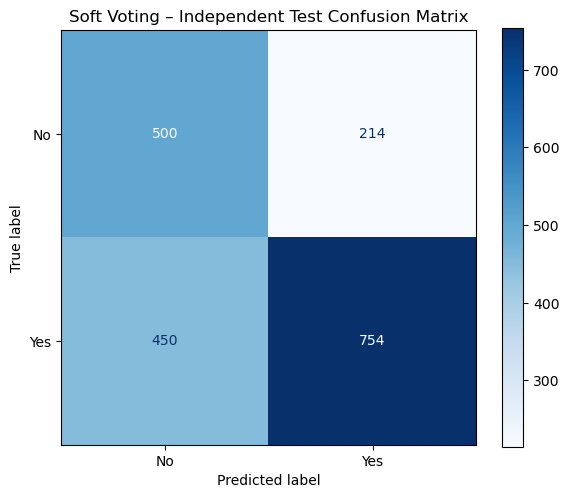

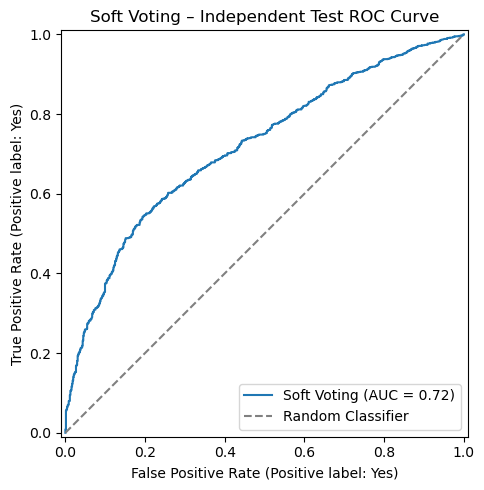

In [48]:
# Step 21 – Independent Test Evaluation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# 1. Train the four selected models on the full training dataset
final_fitted_models = {}
test_model_probabilities = {}

for model_name, model in voting_models.items():

    fitted_model = clone(model)

    fitted_model.fit(X_train, y_train)

    final_fitted_models[model_name] = fitted_model

    test_model_probabilities[model_name] = (
        fitted_model.predict_proba(X_test)[:, 1]
    )

# 2. Combine predicted probabilities using equal weights
test_soft_voting_probabilities = pd.DataFrame(
    test_model_probabilities
)

test_soft_voting_prob_yes = (
    test_soft_voting_probabilities.mean(axis=1).to_numpy()
)

# 3. Apply the selected classification threshold
test_threshold = soft_voting_best_threshold

test_predictions = np.where(
    test_soft_voting_prob_yes >= test_threshold,
    "Yes",
    "No"
)

# 4. Calculate independent test performance
test_results = {
    "Accuracy": accuracy_score(
        y_test, test_predictions
    ),

    "Precision": precision_score(
        y_test, test_predictions,
        average="macro",
        zero_division=0
    ),

    "Recall": recall_score(
        y_test, test_predictions,
        average="macro",
        zero_division=0
    ),

    "F1": f1_score(
        y_test, test_predictions,
        average="macro",
        zero_division=0
    ),

    "Recall_No": recall_score(
        y_test, test_predictions,
        pos_label="No"
    ),

    "ROC_AUC": roc_auc_score(
        y_test, test_soft_voting_prob_yes
    )
}

# 5. Calculate majority-class baseline on the test dataset
majority_class = y_train.value_counts().idxmax()

baseline_test_predictions = np.repeat(
    majority_class, len(y_test)
)

test_baseline_accuracy = accuracy_score(
    y_test, baseline_test_predictions
)

# 6. Retrieve final cross-validation results
cv_soft_voting_results = final_model_results.loc[
    final_model_results["Model"] == "Soft Voting"
].iloc[0]

# 7. Compare cross-validation and independent test performance
test_comparison = pd.DataFrame([
    {
        "Metric": metric,
        "Cross_Validation": cv_soft_voting_results[metric],
        "Independent_Test": test_results[metric],
        "Difference": (
            test_results[metric] -
            cv_soft_voting_results[metric]
        )
    }
    for metric in test_results
])

print("\nFinal Model Configuration")
print("Model: Soft Voting")
print("Model weights: Equal (25% each)")
print(f"Classification threshold: {test_threshold:.2f}")
print(f"Training observations: {len(X_train):,}")
print(f"Test observations: {len(X_test):,}")

print("\nCross-Validation vs. Independent Test Performance")

display(test_comparison.round(4))

# 8. Compare test performance with the majority-class baseline
print("\nMajority-Class Baseline Comparison")

print(
    f"Baseline Accuracy: "
    f"{test_baseline_accuracy:.2%}"
)

print(
    f"Soft Voting Accuracy: "
    f"{test_results['Accuracy']:.2%}"
)

print(
    f"Accuracy Improvement: "
    f"{(test_results['Accuracy'] - test_baseline_accuracy) * 100:.2f} "
    "percentage points"
)

# 9. Display classification report
print("\nIndependent Test Classification Report")

print(classification_report(
    y_test,
    test_predictions,
    labels=["No", "Yes"],
    digits=4,
    zero_division=0
))

# 10. Display confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=["No", "Yes"],
    cmap="Blues",
    ax=ax
)

ax.set_title("Soft Voting – Independent Test Confusion Matrix")

plt.tight_layout()
plt.show()

# 11. Display ROC curve
fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_test,
    test_soft_voting_prob_yes,
    pos_label="Yes",
    name="Soft Voting",
    ax=ax
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

ax.set_title("Soft Voting – Independent Test ROC Curve")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

**Findings:**

- All six evaluation metrics on the independent test dataset exceeded the cross-validation results, suggesting good generalization to unseen data.
- Accuracy improved from the majority-class baseline of 62.79% to 66.34%, an improvement of 3.54 percentage points.
- Macro F1 increased from 0.6440 during cross-validation to 0.6549 on the independent test dataset.
- The model correctly identified 68.07% of unrecovered vehicles and 65.31% of recovered vehicles, demonstrating relatively balanced classification performance.
- ROC AUC increased from 0.7081 to 0.7299, indicating moderate discrimination between recovered and unrecovered vehicles.
- Precision for unrecovered vehicles remained relatively low (53.76%), indicating that a considerable proportion of vehicles predicted as unrecovered were actually recovered.

**Conclusion:**

The final Soft Voting model, using equal model weights and a classification threshold of 0.62, demonstrated good generalization to unseen data, with no evidence of performance deterioration on the independent test dataset.

The model outperformed the majority-class baseline and achieved relatively balanced performance across both recovery outcomes. However, its overall predictive ability remains moderate, suggesting that the six available predictors capture useful patterns but are insufficient for highly accurate recovery predictions.

The selected model configuration is retained without further adjustments to preserve the integrity of the independent test evaluation.

## Step 22 – Interactive Vehicle Recovery Prediction

**Objective:** Demonstrate the practical application of the final Soft Voting model by predicting the recovery outcome of a hypothetical stolen vehicle.

The user selects values for the six predictors, and the model generates recovery probabilities using the four trained individual models.

In [49]:
# Step 22 – Interactive Vehicle Recovery Prediction

import pandas as pd
import numpy as np
import ipywidgets as widgets

from IPython.display import display, clear_output

# 1. Define the six predictors
predictors = [
    "Vehicle_Make",
    "Vehicle_Style",
    "Vehicle_Age_Group",
    "Neighbourhood",
    "Time_of_Day",
    "Reporting_Delay"
]

# 2. Create dropdown menus using training dataset categories
dropdowns = {}

for predictor in predictors:

    dropdowns[predictor] = widgets.Dropdown(
        options=sorted(X_train[predictor].unique()),
        description=predictor.replace("_", " ") + ":",
        style={"description_width": "180px"},
        layout=widgets.Layout(width="500px")
    )

# 3. Create prediction button
predict_button = widgets.Button(
    description="Predict Recovery",
    button_style="primary",
    layout=widgets.Layout(width="200px")
)

output = widgets.Output()

# 4. Define prediction function
def predict_recovery(button):

    with output:

        clear_output()

        # Create a single observation from selected values
        new_case = pd.DataFrame([{
            predictor: dropdowns[predictor].value
            for predictor in predictors
        }])

        print("Selected Vehicle Theft Case")
        display(new_case)

        # Generate individual model probabilities
        individual_probabilities = {}

        for model_name, model in final_fitted_models.items():

            probability = model.predict_proba(new_case)[0, 1]

            individual_probabilities[model_name] = probability

        # Display individual model probabilities
        probability_table = pd.DataFrame([
            {
                "Model": model_name,
                "Recovery_Probability": f"{probability:.2%}"
            }
            for model_name, probability
            in individual_probabilities.items()
        ])

        print("\nIndividual Model Predictions")
        display(probability_table)

        # Calculate Soft Voting probability
        recovery_probability = np.mean(
            list(individual_probabilities.values())
        )

        non_recovery_probability = 1 - recovery_probability

        # Apply the selected threshold
        prediction = (
            "Recovered"
            if recovery_probability >= soft_voting_best_threshold
            else "Not Recovered"
        )

        # Display final prediction
        print("\nFinal Soft Voting Prediction")
        print("-" * 45)

        print(f"Recovery Probability: {recovery_probability:.2%}")
        print(f"Non-Recovery Probability: {non_recovery_probability:.2%}")
        print(f"Classification Threshold: {soft_voting_best_threshold:.2f}")

        print(f"\nPredicted Outcome: {prediction.upper()}")

# 5. Connect button to prediction function
predict_button.on_click(predict_recovery)

# 6. Display interactive prediction form
display(widgets.VBox([
    *dropdowns.values(),
    predict_button,
    output
]))

App Link: https://jy2x653yugccglqz7xn5tr.streamlit.app/?utm_source=chatgpt.com

In [50]:
df.loc[
    df["Vehicle_Style"].isin(["Motor Home", "Snowmobile"]),
    ["Vehicle_Style", "Vehicle_Make"]
].value_counts()

Series([], Name: count, dtype: int64)

In [51]:
display(df[df["Vehicle_Style"].isin(["Motor Home", "Snowmobile"])])

,Vehicle_Year,Vehicle_Make,Vehicle_Style,Occurred_Date,Occurred_Year,Occurred_Hour,Time_of_Day,Neighbourhood,Reported_Date,Reported_Hour,Recovered,Vehicle_Age,Vehicle_Age_Group,Reporting_Delay
